# Cognitive-Load-Aware Phishing Defense Simulation

**Academic mobility extension notebook**  
**Topic:** Agent-based and evolutionary-game simulation of phishing-based social engineering under cognitive load.

This notebook expands the earlier phishing-intervention simulation into a stronger experiment connected to my thesis. The key idea is following:

> Under what conditions does cognitive-load-aware adaptive defense outperform static phishing interventions, and how accurate must cognitive-load detection be before adaptation becomes useful?

The notebook implements:

1. A hybrid population model: organizational roles + cognitive resilience profiles.
2. A social-engineering attack model based on pretext cues: urgency, authority, personalization, novelty, plausibility, and visible suspiciousness.
3. A cognitive-load model with individual overload thresholds.
4. Static and adaptive defense strategies.
5. A noisy pBCI-inspired overload detector.
6. Main ABM experiments, detector-sensitivity analysis, role/profile analysis.
7. An Evolutionary Game Theory layer using ABM-derived payoffs.

The notebook is a simulation framework. It is not an empirical estimate of real-world phishing rates.

## 1. Setup

No external dataset is required. The notebook uses standard scientific Python packages.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from typing import Dict, Optional, Tuple
import json

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

RNG_SEED = 42
# OUTPUT_DIR = Path('cogload_phishing_outputs')
OUTPUT_DIR = Path('cogload_phishing_outputs_last')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Output directory: {OUTPUT_DIR.resolve()}')

Output directory: C:\Users\User\Jupyter projects\eeg-analysis\academic mobility\cogload_phishing_outputs_last


## 2. Configuration

For a quick smoke test, set `n_runs=20`. For report-quality results, use `n_runs=200` or more.

`detector_ba` is the balanced-accuracy-like quality of the cognitive-load detector. It is intentionally imperfect, because my thesis showed that real EEG workload decoding is limited and should not be treated as an oracle.

In [2]:
@dataclass
class SimConfig:
    n_agents: int = 2000
    n_runs: int = 200
    seed: int = 42
    detector_ba: float = 0.65
    decision_noise: float = 0.10
    report_deadline_h: float = 4.0

    training_effect_size: float = 0.16
    static_warning_strength: float = 0.55
    adaptive_warning_strength: float = 0.65
    adaptive_ui_support: float = 0.35
    soc_speed_effect: float = 0.45

    # ------------------------------------------------------------------
    # RACS extension controls
    # ------------------------------------------------------------------
    # 1) Defense-cost sensitivity controls. These replace hard-coded costs
    #    in simulate_campaign(), while preserving the original default values.
    static_warning_intervention_cost: float = 0.040
    training_intervention_cost: float = 0.055
    soc_fast_intervention_cost: float = 0.070
    adaptive_warning_cost_per_predicted: float = 0.035
    adaptive_filtering_cost_per_predicted: float = 0.045
    adaptive_combined_cost_per_predicted: float = 0.060
    adaptive_combined_fixed_cost: float = 0.030

    # 2) Static-warning habituation / warning fatigue control.
    #    0.0 reproduces the original static warning. Higher values reduce
    #    static-warning strength to test whether static warnings remain best
    #    when users become habituated to repeated warnings.
    static_warning_habituation: float = 0.0

    # 3) Cognitive-load behavioral ablation.
    #    1.0 reproduces the original model. 0.0 keeps cognitive load computed
    #    for diagnostics but removes its direct behavioral effect on pressure,
    #    suspicion, reporting delay, and containment.
    cognitive_load_behavior_weight: float = 1.0

    # 4) Targeted adaptive defense controls.
    targeted_roles: Tuple[str, ...] = ('Finance', 'HR', 'Executive', 'IT_SOC')
    targeted_access_threshold: float = 0.75
    targeted_exposure_threshold: float = 0.70

    # stronger penalty for unnecessary adaptive intervention
    false_warning_fatigue_cost: float = 0.10
    warning_friction_cost: float = 0.06

    # adaptive help should be more useful for truly overloaded users
    true_positive_adaptive_multiplier: float = 1.00
    false_positive_adaptive_multiplier: float = 0.35

    # net-loss weights for evaluation
    breach_loss_weight: float = 1.00
    compromise_loss_weight: float = 0.45
    click_loss_weight: float = 0.20
    intervention_loss_weight: float = 0.40
    false_adaptation_loss_weight: float = 0.30
    missed_overload_loss_weight: float = 0.15


config = SimConfig()
asdict(config)

{'n_agents': 2000,
 'n_runs': 200,
 'seed': 42,
 'detector_ba': 0.65,
 'decision_noise': 0.1,
 'report_deadline_h': 4.0,
 'training_effect_size': 0.16,
 'static_warning_strength': 0.55,
 'adaptive_warning_strength': 0.65,
 'adaptive_ui_support': 0.35,
 'soc_speed_effect': 0.45,
 'static_warning_intervention_cost': 0.04,
 'training_intervention_cost': 0.055,
 'soc_fast_intervention_cost': 0.07,
 'adaptive_warning_cost_per_predicted': 0.035,
 'adaptive_filtering_cost_per_predicted': 0.045,
 'adaptive_combined_cost_per_predicted': 0.06,
 'adaptive_combined_fixed_cost': 0.03,
 'static_warning_habituation': 0.0,
 'cognitive_load_behavior_weight': 1.0,
 'targeted_roles': ('Finance', 'HR', 'Executive', 'IT_SOC'),
 'targeted_access_threshold': 0.75,
 'targeted_exposure_threshold': 0.7,
 'false_warning_fatigue_cost': 0.1,
 'warning_friction_cost': 0.06,
 'true_positive_adaptive_multiplier': 1.0,
 'false_positive_adaptive_multiplier': 0.35,
 'breach_loss_weight': 1.0,
 'compromise_loss_weight': 

## 3. Experimental logic

The model has two time scales.

**Micro scale: one social-engineering campaign.** The attacker chooses a pretext, the message reaches users, users experience cognitive load, they appraise the message, they may click or report, and the defender/SOC may contain the incident.

**Macro scale: repeated campaigns.** The Evolutionary Game Theory layer uses ABM-derived payoffs to estimate which user, defender, and attacker strategies become stable over repeated interaction.

This means the ABM models cognition and behavior inside the attack, while EGT models strategic adaptation across attacks.

## 4. Roles and cognitive profiles

The model combines two dimensions:

- **Organizational role**: exposure, access value, role stress, and reporting context.
- **Cognitive profile**: overload threshold, attention, trust, urgency sensitivity, fatigue, and cyber literacy.

This is stronger than modeling only departments or only abstract human archetypes.

In [3]:
def clip01(x):
    return np.clip(x, 0.0, 1.0)

ROLE_PROFILES = {
    'Finance':      dict(size=0.12, literacy=0.56, training=0.52, stress=0.62, access=0.82, exposure=0.65, reporting=0.55),
    'HR':           dict(size=0.10, literacy=0.52, training=0.50, stress=0.55, access=0.70, exposure=0.72, reporting=0.58),
    'CustomerCare': dict(size=0.14, literacy=0.46, training=0.42, stress=0.66, access=0.55, exposure=0.90, reporting=0.45),
    'Sales':        dict(size=0.14, literacy=0.48, training=0.43, stress=0.64, access=0.60, exposure=0.80, reporting=0.46),
    'Engineering':  dict(size=0.18, literacy=0.70, training=0.57, stress=0.52, access=0.68, exposure=0.42, reporting=0.54),
    'Operations':   dict(size=0.13, literacy=0.55, training=0.48, stress=0.59, access=0.62, exposure=0.58, reporting=0.50),
    'Executive':    dict(size=0.04, literacy=0.60, training=0.50, stress=0.78, access=0.95, exposure=0.78, reporting=0.42),
    'IT_SOC':       dict(size=0.15, literacy=0.82, training=0.75, stress=0.70, access=0.88, exposure=0.50, reporting=0.76),
}

COGNITIVE_PROFILES = {
    'resilient_skeptic': dict(size=0.15, literacy=0.12, training=0.10, attention=0.20, trust=-0.18, authority=-0.15,
                              urgency=-0.18, impulsivity=-0.18, fatigue=-0.12, threshold=0.76, reporting=0.12),
    'cautious_user': dict(size=0.22, literacy=0.06, training=0.06, attention=0.10, trust=-0.08, authority=-0.05,
                          urgency=-0.05, impulsivity=-0.08, fatigue=-0.05, threshold=0.68, reporting=0.08),
    'neutral_user': dict(size=0.25, literacy=0.00, training=0.00, attention=0.00, trust=0.00, authority=0.00,
                         urgency=0.00, impulsivity=0.00, fatigue=0.00, threshold=0.60, reporting=0.00),
    'trusting_fast_responder': dict(size=0.13, literacy=-0.04, training=-0.02, attention=-0.06, trust=0.16, authority=0.10,
                                    urgency=0.18, impulsivity=0.12, fatigue=0.04, threshold=0.55, reporting=-0.04),
    'authority_sensitive': dict(size=0.10, literacy=-0.02, training=0.00, attention=-0.03, trust=0.06, authority=0.22,
                                urgency=0.10, impulsivity=0.06, fatigue=0.02, threshold=0.56, reporting=-0.02),
    'fatigued_overloaded': dict(size=0.10, literacy=-0.08, training=-0.08, attention=-0.14, trust=0.10, authority=0.08,
                                urgency=0.14, impulsivity=0.16, fatigue=0.20, threshold=0.48, reporting=-0.10),
    'trained_but_fatigued_expert': dict(size=0.05, literacy=0.16, training=0.14, attention=0.05, trust=-0.08, authority=-0.04,
                                        urgency=0.02, impulsivity=-0.04, fatigue=0.18, threshold=0.62, reporting=0.08),
}

print('Role size sum:', round(sum(v['size'] for v in ROLE_PROFILES.values()), 3))
print('Profile size sum:', round(sum(v['size'] for v in COGNITIVE_PROFILES.values()), 3))

Role size sum: 1.0
Profile size sum: 1.0


In [4]:
def generate_population(config: SimConfig, seed: Optional[int] = None, forced_profile: Optional[str] = None) -> pd.DataFrame:
    rng = np.random.default_rng(config.seed if seed is None else seed)
    n = config.n_agents

    role_names = list(ROLE_PROFILES.keys())
    role_probs = np.array([ROLE_PROFILES[r]['size'] for r in role_names], dtype=float)
    role_probs = role_probs / role_probs.sum()
    roles = rng.choice(role_names, size=n, p=role_probs)

    profile_names = list(COGNITIVE_PROFILES.keys())
    if forced_profile is None:
        profile_probs = np.array([COGNITIVE_PROFILES[p]['size'] for p in profile_names], dtype=float)
        profile_probs = profile_probs / profile_probs.sum()
        profiles = rng.choice(profile_names, size=n, p=profile_probs)
    else:
        profiles = np.array([forced_profile] * n)

    rows = []
    for i, (role, prof) in enumerate(zip(roles, profiles)):
        rp = ROLE_PROFILES[role]
        cp = COGNITIVE_PROFILES[prof]

        cyber_lit = clip01(rng.normal(rp['literacy'] + cp['literacy'], 0.08))
        training = clip01(rng.normal(rp['training'] + cp['training'], 0.08))
        detail = clip01(rng.normal(0.52 + cp['attention'] + 0.25 * cyber_lit, 0.10))
        trust = clip01(rng.normal(0.50 + cp['trust'], 0.12))
        authority = clip01(rng.normal(0.50 + cp['authority'], 0.12))
        urgency = clip01(rng.normal(0.50 + cp['urgency'], 0.12))
        impulsivity = clip01(rng.normal(0.46 + cp['impulsivity'], 0.12))
        fatigue = clip01(rng.normal(0.38 + cp['fatigue'] + 0.12 * rp['stress'], 0.10))
        reporting = clip01(rng.normal(rp['reporting'] + cp['reporting'], 0.10))
        threshold = clip01(rng.normal(cp['threshold'], 0.06))

        readiness = clip01(0.30 * cyber_lit + 0.25 * training + 0.25 * detail + 0.20 * reporting - 0.12 * fatigue)

        rows.append({
            'agent_id': i,
            'role': role,
            'cognitive_profile': prof,
            'cyber_literacy': cyber_lit,
            'prior_training': training,
            'detail_attention': detail,
            'trust_disposition': trust,
            'authority_bias': authority,
            'urgency_susceptibility': urgency,
            'impulsivity': impulsivity,
            'security_fatigue': fatigue,
            'reporting_norm': reporting,
            'overload_threshold': threshold,
            'defensive_readiness': readiness,
            'role_stress': clip01(rng.normal(rp['stress'], 0.07)),
            'access_value': clip01(rng.normal(rp['access'], 0.06)),
            'external_exposure': clip01(rng.normal(rp['exposure'], 0.08)),
        })

    return pd.DataFrame(rows)

population = generate_population(config)
print(population.shape)
display(population.head())

(2000, 17)


,agent_id,role,cognitive_profile,cyber_literacy,prior_training,detail_attention,trust_disposition,authority_bias,urgency_susceptibility,impulsivity,security_fatigue,reporting_norm,overload_threshold,defensive_readiness,role_stress,access_value,external_exposure
0,0,Operations,authority_sensitive,0.446752,0.360267,0.736947,0.850694,0.662910,0.441549,0.251569,0.446389,0.448363,0.520922,0.444435,0.605496,0.643710,0.605847
1,1,Sales,neutral_user,0.454710,0.341870,0.700261,0.501502,0.606603,0.594809,0.289389,0.313378,0.384446,0.536624,0.436230,0.692868,0.621079,0.887935
2,2,IT_SOC,trained_but_fatigued_expert,1.000000,0.906692,0.939973,0.476367,0.468172,0.697654,0.433822,0.613566,0.756218,0.662182,0.839282,0.786594,0.876965,0.604633
3,3,Operations,trusting_fast_responder,0.352399,0.455564,0.544090,0.572761,0.886063,0.672057,0.531072,0.493396,0.259719,0.504408,0.348369,0.658827,0.582263,0.513690
4,4,Finance,resilient_skeptic,0.784762,0.727220,0.967890,0.265386,0.321263,0.223502,0.160627,0.229958,0.608195,0.697917,0.753250,0.510541,0.833164,0.668768


### Initial population diagnostics

These are not final results. They show whether the synthetic population is heterogeneous enough for simulation.

,n,literacy,readiness,fatigue,access,exposure
role,,,,,,
CustomerCare,259,0.486,0.467,0.469,0.548,0.899
Engineering,345,0.722,0.606,0.448,0.675,0.425
Executive,81,0.639,0.545,0.474,0.944,0.776
Finance,230,0.581,0.545,0.457,0.815,0.652
HR,222,0.547,0.541,0.434,0.698,0.728
IT_SOC,313,0.843,0.737,0.469,0.882,0.503
Operations,253,0.571,0.521,0.453,0.627,0.582
Sales,297,0.506,0.481,0.455,0.605,0.806


,n,threshold,attention,fatigue,readiness
cognitive_profile,,,,,
authority_sensitive,192,0.564,0.646,0.468,0.516
cautious_user,445,0.680,0.788,0.409,0.619
fatigued_overloaded,198,0.479,0.518,0.642,0.415
neutral_user,505,0.600,0.678,0.450,0.541
resilient_skeptic,317,0.764,0.880,0.326,0.686
trained_but_fatigued_expert,100,0.625,0.744,0.631,0.613
trusting_fast_responder,243,0.558,0.589,0.491,0.479


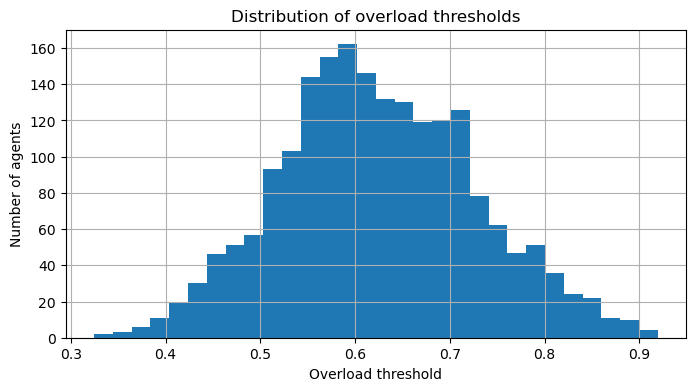

In [5]:
role_diag = population.groupby('role').agg(
    n=('agent_id', 'count'),
    literacy=('cyber_literacy', 'mean'),
    readiness=('defensive_readiness', 'mean'),
    fatigue=('security_fatigue', 'mean'),
    access=('access_value', 'mean'),
    exposure=('external_exposure', 'mean'),
).round(3)
display(role_diag)

profile_diag = population.groupby('cognitive_profile').agg(
    n=('agent_id', 'count'),
    threshold=('overload_threshold', 'mean'),
    attention=('detail_attention', 'mean'),
    fatigue=('security_fatigue', 'mean'),
    readiness=('defensive_readiness', 'mean'),
).round(3)
display(profile_diag)

plt.figure(figsize=(8, 4))
population['overload_threshold'].hist(bins=30)
plt.title('Distribution of overload thresholds')
plt.xlabel('Overload threshold')
plt.ylabel('Number of agents')
plt.show()

## 5. Social-engineering attack model

The attack is a **pretext vector**. The attacker manipulates cognitive appraisal using urgency, authority, fear/loss, personalization, plausibility, novelty, and visible suspiciousness.

This is why phishing is useful here: the attack is human-centered and therefore naturally connected to cognitive load.

In [6]:
ATTACK_STRATEGIES = {
    'generic_phishing': dict(phish_pressure=0.52, authority_cue=0.25, urgency_cue=0.30, fear_loss_cue=0.25, reward_cue=0.30,
                             personalization=0.20, plausibility=0.45, pattern_novelty=0.25, technical_suspiciousness=0.55,
                             sophistication=0.35, targeting_scope='bulk', target_roles=[], attack_cost=0.02, compromise_probability=0.18),
    'authority_urgency': dict(phish_pressure=0.68, authority_cue=0.85, urgency_cue=0.82, fear_loss_cue=0.55, reward_cue=0.15,
                              personalization=0.55, plausibility=0.62, pattern_novelty=0.45, technical_suspiciousness=0.38,
                              sophistication=0.62, targeting_scope='role_targeted', target_roles=['Finance','Executive','Operations'],
                              attack_cost=0.07, compromise_probability=0.30),
    'invoice_fraud': dict(phish_pressure=0.66, authority_cue=0.70, urgency_cue=0.64, fear_loss_cue=0.45, reward_cue=0.20,
                          personalization=0.70, plausibility=0.70, pattern_novelty=0.40, technical_suspiciousness=0.35,
                          sophistication=0.68, targeting_scope='role_targeted', target_roles=['Finance','Executive'],
                          attack_cost=0.08, compromise_probability=0.34),
    'hr_document': dict(phish_pressure=0.60, authority_cue=0.48, urgency_cue=0.48, fear_loss_cue=0.30, reward_cue=0.25,
                        personalization=0.68, plausibility=0.67, pattern_novelty=0.38, technical_suspiciousness=0.42,
                        sophistication=0.55, targeting_scope='role_targeted', target_roles=['HR','CustomerCare'],
                        attack_cost=0.06, compromise_probability=0.26),
    'alert_flooding_attack': dict(phish_pressure=0.62, authority_cue=0.45, urgency_cue=0.55, fear_loss_cue=0.45, reward_cue=0.18,
                                  personalization=0.45, plausibility=0.55, pattern_novelty=0.52, technical_suspiciousness=0.45,
                                  sophistication=0.56, targeting_scope='bulk', target_roles=[], attack_cost=0.09, compromise_probability=0.27),
    'cognitive_attack_vector': dict(phish_pressure=0.74, authority_cue=0.82, urgency_cue=0.88, fear_loss_cue=0.70, reward_cue=0.20,
                                    personalization=0.72, plausibility=0.72, pattern_novelty=0.72, technical_suspiciousness=0.32,
                                    sophistication=0.78, targeting_scope='role_targeted',
                                    target_roles=['Finance','HR','CustomerCare','Executive','Operations'], attack_cost=0.14,
                                    compromise_probability=0.40),
}

ENVIRONMENT_SCENARIOS = {
    'normal': dict(org_stress=0.42, alert_flooding=0.25, time_pressure=0.30, pattern_disruption=0.25),
    'alert_flooding': dict(org_stress=0.50, alert_flooding=0.82, time_pressure=0.40, pattern_disruption=0.35),
    'time_pressure': dict(org_stress=0.56, alert_flooding=0.34, time_pressure=0.84, pattern_disruption=0.45),
    'cognitive_attack_vector': dict(org_stress=0.64, alert_flooding=0.82, time_pressure=0.86, pattern_disruption=0.72),
}

CAMPAIGN_SCENARIOS = {
    'normal_generic': dict(environment='normal', attack='generic_phishing'),
    'alert_flooding': dict(environment='alert_flooding', attack='alert_flooding_attack'),
    'time_pressure_authority': dict(environment='time_pressure', attack='authority_urgency'),
    'full_cognitive_attack_vector': dict(environment='cognitive_attack_vector', attack='cognitive_attack_vector'),
}

BASE_CAMPAIGN_NAMES = [
    'normal_generic',
    'alert_flooding',
    'time_pressure_authority',
    'full_cognitive_attack_vector',
]

DEFENSE_MODES = ['baseline', 'training', 'static_warning', 'soc_fast', 'adaptive_warning', 'adaptive_filtering', 'adaptive_combined']

display(pd.DataFrame(ATTACK_STRATEGIES).T)

,phish_pressure,authority_cue,urgency_cue,fear_loss_cue,reward_cue,personalization,plausibility,pattern_novelty,technical_suspiciousness,sophistication,targeting_scope,target_roles,attack_cost,compromise_probability
generic_phishing,0.52,0.25,0.3,0.25,0.3,0.2,0.45,0.25,0.55,0.35,bulk,[],0.02,0.18
authority_urgency,0.68,0.85,0.82,0.55,0.15,0.55,0.62,0.45,0.38,0.62,role_targeted,"[Finance, Executive, Operations]",0.07,0.3
invoice_fraud,0.66,0.7,0.64,0.45,0.2,0.7,0.7,0.4,0.35,0.68,role_targeted,"[Finance, Executive]",0.08,0.34
hr_document,0.6,0.48,0.48,0.3,0.25,0.68,0.67,0.38,0.42,0.55,role_targeted,"[HR, CustomerCare]",0.06,0.26
alert_flooding_attack,0.62,0.45,0.55,0.45,0.18,0.45,0.55,0.52,0.45,0.56,bulk,[],0.09,0.27
cognitive_attack_vector,0.74,0.82,0.88,0.7,0.2,0.72,0.72,0.72,0.32,0.78,role_targeted,"[Finance, HR, CustomerCare, Executive, Operati...",0.14,0.4


## 6. Cognitive-load and detector model

Cognitive load is computed from role stress, organizational stress, alert flooding, time pressure, pattern disruption, security fatigue, defensive readiness, and UI support.

The adaptive defense does not know true load. It uses a noisy detector:

- detector BA = 0.50: random
- detector BA = 0.65: moderate / thesis-inspired
- detector BA = 1.00: oracle

In [7]:
def compute_cognitive_load(df: pd.DataFrame, env: Dict, attack: Dict, ui_support=None) -> np.ndarray:
    if ui_support is None:
        ui_support = np.zeros(len(df))
    effective_time_pressure = clip01(0.65 * env['time_pressure'] + 0.35 * attack['urgency_cue'])
    effective_pattern_disruption = clip01(0.65 * env['pattern_disruption'] + 0.35 * attack['pattern_novelty'])
    load = (
        0.20 * df['role_stress'].values
        + 0.20 * env['org_stress']
        + 0.18 * env['alert_flooding'] * (0.65 + 0.35 * df['external_exposure'].values)
        + 0.18 * effective_time_pressure
        + 0.12 * effective_pattern_disruption
        + 0.12 * df['security_fatigue'].values
        - 0.18 * df['defensive_readiness'].values
        - 0.10 * np.asarray(ui_support)
    )
    return clip01(load)


def detect_overload(true_overloaded: np.ndarray, detector_ba: float, rng: np.random.Generator) -> np.ndarray:
    detector_ba = float(np.clip(detector_ba, 0.0, 1.0))
    pred = np.zeros_like(true_overloaded, dtype=bool)
    high = true_overloaded.astype(bool)
    low = ~high
    pred[high] = rng.random(high.sum()) < detector_ba
    pred[low] = rng.random(low.sum()) < (1.0 - detector_ba)
    return pred


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

## 7. Defense interventions and campaign simulation

The campaign model produces both individual outcomes and organization-level outcomes:

- clicked
- reported
- compromised
- contained
- breach-risk score

The important design choice: adaptive interventions are triggered by predicted overload, not true overload. That makes detector sensitivity meaningful.

In [8]:
def apply_training(df: pd.DataFrame, config: SimConfig) -> pd.DataFrame:
    d = df.copy()
    gain = config.training_effect_size * (1.0 - d['prior_training'].values) * (0.70 + 0.30 * d['cyber_literacy'].values)
    d['prior_training'] = clip01(d['prior_training'].values + gain)
    d['cyber_literacy'] = clip01(d['cyber_literacy'].values + 0.55 * gain)
    d['detail_attention'] = clip01(d['detail_attention'].values + 0.45 * gain)
    d['reporting_norm'] = clip01(d['reporting_norm'].values + 0.40 * gain)
    d['defensive_readiness'] = clip01(0.30*d['cyber_literacy'].values + 0.25*d['prior_training'].values +
                                      0.25*d['detail_attention'].values + 0.20*d['reporting_norm'].values -
                                      0.12*d['security_fatigue'].values)
    return d


def exposure_probability(df: pd.DataFrame, attack: Dict) -> np.ndarray:
    scope = attack['targeting_scope']
    targets = set(attack.get('target_roles', []))
    role_match = df['role'].isin(targets).values if targets else np.zeros(len(df), dtype=bool)
    if scope == 'bulk':
        base = 0.70 + 0.20 * df['external_exposure'].values
    elif scope == 'role_targeted':
        base = np.where(role_match, 0.72 + 0.18 * df['external_exposure'].values, 0.12 + 0.10 * df['external_exposure'].values)
    else:
        base = 0.50 * df['external_exposure'].values
    return clip01(base)


def targeted_adaptive_mask(df: pd.DataFrame, config: SimConfig) -> np.ndarray:
    """Return users eligible for targeted adaptive intervention.

    The targeted policy keeps the cognitive-load detector but applies intervention
    only to users whose organizational position makes a compromise more costly or
    more likely: selected high-risk roles, high access value, or high external exposure.
    """
    role_mask = df['role'].isin(config.targeted_roles).values
    access_mask = df['access_value'].values >= config.targeted_access_threshold
    exposure_mask = df['external_exposure'].values >= config.targeted_exposure_threshold
    return role_mask | access_mask | exposure_mask


def simulate_campaign(population: pd.DataFrame, campaign_name: str, defense: str, config: SimConfig, seed: int,
                      detector_ba: Optional[float] = None, return_agents: bool = False) -> Tuple[pd.DataFrame, Dict]:
    rng = np.random.default_rng(seed)
    detector_ba = config.detector_ba if detector_ba is None else detector_ba
    campaign = CAMPAIGN_SCENARIOS[campaign_name]
    env = ENVIRONMENT_SCENARIOS[campaign['environment']]
    attack = ATTACK_STRATEGIES[campaign['attack']]
    d = population.copy()
    n = len(d)

    if defense == 'training':
        d = apply_training(d, config)

    preliminary_load = compute_cognitive_load(d, env, attack, ui_support=np.zeros(n))
    true_overloaded_pre = preliminary_load > d['overload_threshold'].values

    if defense.startswith('adaptive'):
        predicted_overload = detect_overload(true_overloaded_pre, detector_ba, rng)
    else:
        predicted_overload = np.zeros(n, dtype=bool)

    # RACS extension: targeted adaptive defense.
    # It uses the same detector, but only intervenes for overloaded users who are also
    # high-risk/high-value/high-exposure. This tests whether adaptive defense is more
    # useful when it is narrowly deployed instead of broadly applied.
    targeted_eligible = np.zeros(n, dtype=bool)
    if defense == 'adaptive_combined_targeted':
        targeted_eligible = targeted_adaptive_mask(d, config)
        predicted_overload = predicted_overload & targeted_eligible

    warning_strength = np.zeros(n)
    ui_support = np.zeros(n)
    soc_speed = 0.0
    intervention_cost = 0.0

    if defense == 'static_warning':
        effective_static_strength = config.static_warning_strength * (1.0 - config.static_warning_habituation)
        warning_strength[:] = clip01(effective_static_strength)
        intervention_cost = config.static_warning_intervention_cost
    elif defense == 'soc_fast':
        soc_speed = config.soc_speed_effect
        intervention_cost = config.soc_fast_intervention_cost
    elif defense == 'adaptive_warning':
        warning_strength[predicted_overload] = config.adaptive_warning_strength
        intervention_cost = config.adaptive_warning_cost_per_predicted * predicted_overload.mean()
    elif defense == 'adaptive_filtering':
        ui_support[predicted_overload] = config.adaptive_ui_support
        intervention_cost = config.adaptive_filtering_cost_per_predicted * predicted_overload.mean()
    elif defense in ('adaptive_combined', 'adaptive_combined_targeted'):
        warning_strength[predicted_overload] = config.adaptive_warning_strength
        ui_support[predicted_overload] = config.adaptive_ui_support
        soc_speed = config.soc_speed_effect * (0.35 + 0.65 * predicted_overload.mean())
        intervention_cost = config.adaptive_combined_cost_per_predicted * predicted_overload.mean() + config.adaptive_combined_fixed_cost
    elif defense == 'training':
        intervention_cost = config.training_intervention_cost
    elif defense == 'baseline':
        pass
    else:
        raise ValueError(f'Unknown defense mode: {defense}')

    false_adaptation = predicted_overload & (~true_overloaded_pre)
    true_adaptation = predicted_overload & true_overloaded_pre

    if defense.startswith('adaptive'):
        # False positives create fatigue/friction because the system interrupts users
        # who were not actually overloaded.
        d.loc[:, 'security_fatigue'] = clip01(
            d['security_fatigue'].values
            + config.false_warning_fatigue_cost * false_adaptation.astype(float)
        )

        # Adaptive warning is assumed to be most useful when the user is truly overloaded.
        # For false positives, the warning is weaker and partly perceived as friction/noise.
        adaptive_effect_multiplier = np.ones(n)
        adaptive_effect_multiplier[true_adaptation] = config.true_positive_adaptive_multiplier
        adaptive_effect_multiplier[false_adaptation] = config.false_positive_adaptive_multiplier

        warning_strength = warning_strength * adaptive_effect_multiplier
        ui_support = ui_support * adaptive_effect_multiplier

    cognitive_load = compute_cognitive_load(d, env, attack, ui_support=ui_support)
    overloaded = cognitive_load > d['overload_threshold'].values

    # RACS extension: cognitive-load behavioral ablation.
    # With weight=1.0 this is the original model. With weight=0.0, cognitive load is
    # still computed and reported, but it no longer directly modifies click pressure,
    # suspicion, reporting delay, or containment probability.
    behavioral_load = config.cognitive_load_behavior_weight * cognitive_load

    p_exposed = exposure_probability(d, attack)
    exposed = rng.random(n) < p_exposed

    targets = set(attack.get('target_roles', []))
    if targets:
        role_match = d['role'].isin(targets).values
    else:
        role_match = np.ones(n, dtype=bool) * False
    role_relevance = np.where(role_match, 1.0, 0.25)

    pressure = (0.30*attack['authority_cue']*d['authority_bias'].values +
                0.30*attack['urgency_cue']*d['urgency_susceptibility'].values +
                0.18*attack['fear_loss_cue'] + 0.12*attack['reward_cue'] +
                0.20*role_relevance*attack['personalization'] + 0.18*attack['plausibility'] +
                0.25*behavioral_load + 0.15*attack['phish_pressure'])

    suspicion = (0.35*d['cyber_literacy'].values + 0.30*d['detail_attention'].values +
                 0.25*d['prior_training'].values + 0.20*warning_strength +
                 0.18*attack['technical_suspiciousness'] - 0.25*behavioral_load -
                 0.18*attack['sophistication'] - 0.14*attack['pattern_novelty'] -
                 0.12*d['security_fatigue'].values)

    click_prob = clip01(sigmoid(2.4 * (pressure - suspicion - 0.10) + rng.normal(0, config.decision_noise, n)))
    clicked = exposed & (rng.random(n) < click_prob)

    compromise_prob = clip01(attack['compromise_probability'] * (0.65 + 0.35*attack['plausibility']) * (0.75 + 0.25*d['access_value'].values))
    compromised = clicked & (rng.random(n) < compromise_prob)

    report_drive = (0.40*suspicion + 0.28*d['reporting_norm'].values + 0.20*d['defensive_readiness'].values +
                    0.18*warning_strength - 0.25*behavioral_load - 0.15*d['security_fatigue'].values)
    report_prob = clip01(sigmoid(2.5 * (report_drive - 0.42) + rng.normal(0, config.decision_noise, n)))
    reported = exposed & (rng.random(n) < report_prob)

    base_ttr = rng.lognormal(mean=np.log(2.0), sigma=0.55, size=n)
    time_to_report_h = base_ttr * (1.0 + 0.75*behavioral_load) * (1.0 - 0.35*d['defensive_readiness'].values)
    time_to_report_h = np.where(reported, np.maximum(time_to_report_h, 0.05), np.nan)

    reported_fast = reported & (np.nan_to_num(time_to_report_h, nan=999.0) <= config.report_deadline_h)
    containment_prob = clip01(0.25*reported.astype(float) + 0.45*reported_fast.astype(float) + 0.35*soc_speed + 0.10*warning_strength - 0.15*behavioral_load)
    contained = compromised & (rng.random(n) < containment_prob)

    breach_risk_individual = np.where(compromised,
        clip01(attack['phish_pressure'] * d['access_value'].values * (1.0 - contained.astype(float)) * (0.55 + 0.45*attack['sophistication'])),
        0.0)
    org_breach_risk = float(1.0 - np.exp(-breach_risk_individual.sum() / 30.0))

    d['campaign'] = campaign_name
    d['environment'] = campaign['environment']
    d['attack'] = campaign['attack']
    d['defense'] = defense
    d['exposed'] = exposed
    d['preliminary_cognitive_load'] = preliminary_load
    d['cognitive_load'] = cognitive_load
    d['behavioral_cognitive_load'] = behavioral_load
    d['overloaded'] = overloaded
    d['predicted_overload'] = predicted_overload
    d['targeted_adaptive_eligible'] = targeted_eligible
    d['false_adaptation'] = false_adaptation
    d['warning_strength'] = warning_strength
    d['ui_support'] = ui_support
    d['pressure'] = pressure
    d['suspicion'] = suspicion
    d['click_prob'] = click_prob
    d['clicked'] = clicked
    d['compromised'] = compromised
    d['report_prob'] = report_prob
    d['reported'] = reported
    d['time_to_report_h'] = time_to_report_h
    d['contained'] = contained
    d['breach_risk_individual'] = breach_risk_individual

    exposed_n = max(int(exposed.sum()), 1)
    compromised_n = max(int(compromised.sum()), 1)

    missed_overload_rate = float((overloaded & (~predicted_overload)).mean()) if defense.startswith('adaptive') else np.nan

    warning_friction = (
        config.warning_friction_cost * float(predicted_overload.mean())
        if defense.startswith('adaptive')
        else 0.0
    )

    net_expected_loss = (
        config.breach_loss_weight * org_breach_risk
        + config.compromise_loss_weight * float(compromised.mean())
        + config.click_loss_weight * float(clicked.mean())
        + config.intervention_loss_weight * float(intervention_cost)
        + config.false_adaptation_loss_weight * float(false_adaptation.mean())
        + config.missed_overload_loss_weight * (0.0 if np.isnan(missed_overload_rate) else missed_overload_rate)
        + warning_friction
    )

    summary = {
        'campaign': campaign_name,
        'environment': campaign['environment'],
        'attack': campaign['attack'],
        'defense': defense,
        'detector_ba': detector_ba,
        'n_agents': n,
        'exposure_rate': float(exposed.mean()),
        'mean_cognitive_load': float(cognitive_load.mean()),
        'mean_behavioral_cognitive_load': float(behavioral_load.mean()),
        'cognitive_load_behavior_weight': float(config.cognitive_load_behavior_weight),
        'static_warning_habituation': float(config.static_warning_habituation),
        'overloaded_rate': float(overloaded.mean()),
        'predicted_overload_rate': float(predicted_overload.mean()),
        'targeted_adaptive_eligible_rate': float(targeted_eligible.mean()),
        'false_adaptation_rate': float(false_adaptation.mean()),
        'missed_overload_rate': missed_overload_rate,
        'net_expected_loss': float(net_expected_loss),
        'warning_friction': float(warning_friction),
        'click_rate_all': float(clicked.mean()),
        'click_rate_exposed': float(clicked.sum() / exposed_n),
        'compromise_rate_all': float(compromised.mean()),
        'compromise_rate_clicked': float(compromised.sum() / max(int(clicked.sum()), 1)),
        'report_rate_all': float(reported.mean()),
        'report_rate_exposed': float(reported.sum() / exposed_n),
        'median_time_to_report_h': float(np.nanmedian(time_to_report_h)) if reported.any() else np.nan,
        'containment_success_rate': float(contained.sum() / compromised_n) if compromised.any() else np.nan,
        'org_breach_risk': org_breach_risk,
        'expected_loss_score': float(breach_risk_individual.mean()),
        'high_load_click_rate': float(clicked[overloaded].mean()) if overloaded.any() else np.nan,
        'low_readiness_click_rate': float(clicked[d['defensive_readiness'].values < 0.45].mean()) if (d['defensive_readiness'].values < 0.45).any() else np.nan,
        'intervention_cost': float(intervention_cost),
    }
    return (d if return_agents else pd.DataFrame(), summary)

### Smoke test: one campaign

In [9]:
agents_one, summary_one = simulate_campaign(
    population=population,
    campaign_name='full_cognitive_attack_vector',
    defense='adaptive_combined',
    config=config,
    seed=123,
    detector_ba=0.65,
    return_agents=True,
)
print(json.dumps(summary_one, indent=2))
display(agents_one[['role','cognitive_profile','cognitive_load','overloaded','predicted_overload','exposed','clicked','reported','compromised','contained']].head())

{
  "campaign": "full_cognitive_attack_vector",
  "environment": "cognitive_attack_vector",
  "attack": "cognitive_attack_vector",
  "defense": "adaptive_combined",
  "detector_ba": 0.65,
  "n_agents": 2000,
  "exposure_rate": 0.534,
  "mean_cognitive_load": 0.5690885884234442,
  "mean_behavioral_cognitive_load": 0.5690885884234442,
  "cognitive_load_behavior_weight": 1.0,
  "static_warning_habituation": 0.0,
  "overloaded_rate": 0.292,
  "predicted_overload_rate": 0.461,
  "targeted_adaptive_eligible_rate": 0.0,
  "false_adaptation_rate": 0.2285,
  "missed_overload_rate": 0.1275,
  "net_expected_loss": 1.2708043046145756,
  "warning_friction": 0.02766,
  "click_rate_all": 0.4445,
  "click_rate_exposed": 0.8323970037453183,
  "compromise_rate_all": 0.1545,
  "compromise_rate_clicked": 0.34758155230596177,
  "report_rate_all": 0.187,
  "report_rate_exposed": 0.350187265917603,
  "median_time_to_report_h": 2.2872573560540936,
  "containment_success_rate": 0.23300970873786409,
  "org_brea

,role,cognitive_profile,cognitive_load,overloaded,predicted_overload,exposed,clicked,reported,compromised,contained
0,Operations,authority_sensitive,0.592366,True,False,True,True,False,False,False
1,Sales,neutral_user,0.574928,True,True,False,False,False,False,False
2,IT_SOC,trained_but_fatigued_expert,0.577511,False,False,False,False,False,False,False
3,Operations,trusting_fast_responder,0.586204,True,True,True,True,False,True,False
4,Finance,resilient_skeptic,0.494817,False,True,True,False,True,False,False


## 8. Main ABM experiment

Main design:

```text
4 campaign scenarios × 7 defense modes × n_runs Monte Carlo repetitions
```

This compares baseline, static interventions, and cognitive-load-aware adaptive defense.

In [10]:
def run_main_abm_experiment(population: pd.DataFrame, config: SimConfig) -> pd.DataFrame:
    rows = []
    base_seed = 10_000
    campaign_names = BASE_CAMPAIGN_NAMES
    for run in range(config.n_runs):
        for c_i, campaign in enumerate(campaign_names):
            for d_i, defense in enumerate(DEFENSE_MODES):
                _, summary = simulate_campaign(population, campaign, defense, config, base_seed + run*1000 + c_i*100 + d_i, config.detector_ba, False)
                summary['run'] = run
                rows.append(summary)
        if (run + 1) % max(1, config.n_runs // 5) == 0:
            print(f'Completed {run + 1}/{config.n_runs} runs')
    return pd.DataFrame(rows)

main_results = run_main_abm_experiment(population, config)
main_results.to_csv(OUTPUT_DIR / 'main_abm_results.csv', index=False)
print(main_results.shape)
display(main_results.head())

Completed 40/200 runs
Completed 80/200 runs
Completed 120/200 runs
Completed 160/200 runs
Completed 200/200 runs
(5600, 32)


,campaign,environment,attack,defense,detector_ba,n_agents,exposure_rate,mean_cognitive_load,mean_behavioral_cognitive_load,cognitive_load_behavior_weight,static_warning_habituation,overloaded_rate,predicted_overload_rate,targeted_adaptive_eligible_rate,false_adaptation_rate,missed_overload_rate,net_expected_loss,warning_friction,click_rate_all,click_rate_exposed,compromise_rate_all,compromise_rate_clicked,report_rate_all,report_rate_exposed,median_time_to_report_h,containment_success_rate,org_breach_risk,expected_loss_score,high_load_click_rate,low_readiness_click_rate,intervention_cost,run
0,normal_generic,normal,generic_phishing,baseline,0.65,2000,0.8345,0.284828,0.284828,1.0,0.0,0.0010,0.000,0.0,0.0000,NaN,0.602032,0.00000,0.3415,0.409227,0.0530,0.155198,0.3670,0.439784,1.983351,0.226415,0.509882,0.010697,0.500000,0.463415,0.00000,0
1,normal_generic,normal,generic_phishing,training,0.65,2000,0.8290,0.278152,0.278152,1.0,0.0,0.0005,0.000,0.0,0.0000,NaN,0.524184,0.00000,0.3320,0.400483,0.0455,0.137048,0.3635,0.438480,1.858804,0.318681,0.415309,0.008050,1.000000,0.452830,0.05500,0
2,normal_generic,normal,generic_phishing,static_warning,0.65,2000,0.8340,0.284828,0.284828,1.0,0.0,0.0010,0.000,0.0,0.0000,NaN,0.469758,0.00000,0.3185,0.381894,0.0430,0.135008,0.4365,0.523381,1.923259,0.372093,0.370708,0.006947,0.500000,0.429268,0.04000,0
3,normal_generic,normal,generic_phishing,soc_fast,0.65,2000,0.8135,0.284828,0.284828,1.0,0.0,0.0010,0.000,0.0,0.0000,NaN,0.506851,0.00000,0.3555,0.437001,0.0440,0.123769,0.3575,0.439459,1.933617,0.352273,0.387951,0.007364,0.500000,0.473171,0.07000,0
4,normal_generic,normal,generic_phishing,adaptive_warning,0.65,2000,0.8350,0.289238,0.289238,1.0,0.0,0.0015,0.368,0.0,0.3675,0.0005,0.624024,0.02208,0.3465,0.414970,0.0420,0.121212,0.3695,0.442515,1.926866,0.261905,0.398267,0.007619,0.666667,0.465854,0.01288,0


## 9. Main ABM summary

In [11]:
print(main_results.columns.tolist())

['campaign', 'environment', 'attack', 'defense', 'detector_ba', 'n_agents', 'exposure_rate', 'mean_cognitive_load', 'mean_behavioral_cognitive_load', 'cognitive_load_behavior_weight', 'static_warning_habituation', 'overloaded_rate', 'predicted_overload_rate', 'targeted_adaptive_eligible_rate', 'false_adaptation_rate', 'missed_overload_rate', 'net_expected_loss', 'warning_friction', 'click_rate_all', 'click_rate_exposed', 'compromise_rate_all', 'compromise_rate_clicked', 'report_rate_all', 'report_rate_exposed', 'median_time_to_report_h', 'containment_success_rate', 'org_breach_risk', 'expected_loss_score', 'high_load_click_rate', 'low_readiness_click_rate', 'intervention_cost', 'run']


In [12]:
def ci95(x):
    x = pd.Series(x).dropna()
    if len(x) <= 1:
        return 0.0
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))


# Summarize main ABM results
summary = main_results.groupby(['campaign', 'defense']).agg(
    click_rate=('click_rate_exposed', 'mean'),
    click_ci95=('click_rate_exposed', ci95),

    report_rate=('report_rate_exposed', 'mean'),
    report_ci95=('report_rate_exposed', ci95),

    compromise_rate=('compromise_rate_all', 'mean'),
    org_breach_risk=('org_breach_risk', 'mean'),
    overloaded_rate=('overloaded_rate', 'mean'),

    false_adaptation_rate=('false_adaptation_rate', 'mean'),
    missed_overload_rate=('missed_overload_rate', 'mean'),

    containment_success=('containment_success_rate', 'mean'),
    median_ttr_h=('median_time_to_report_h', 'mean'),

    expected_loss=('expected_loss_score', 'mean'),
    net_expected_loss=('net_expected_loss', 'mean'),

    warning_friction=('warning_friction', 'mean'),
    intervention_cost=('intervention_cost', 'mean'),
).reset_index()


# Extract baseline reference values for each campaign
baseline_ref = summary[summary['defense'] == 'baseline'][[
    'campaign',
    'click_rate',
    'org_breach_risk',
    'expected_loss',
    'net_expected_loss'
]].rename(columns={
    'click_rate': 'baseline_click_rate',
    'org_breach_risk': 'baseline_breach_risk',
    'expected_loss': 'baseline_expected_loss',
    'net_expected_loss': 'baseline_net_expected_loss',
})

summary = summary.merge(baseline_ref, on='campaign', how='left')


# Absolute and relative reductions vs baseline
summary['absolute_click_reduction'] = (
    summary['baseline_click_rate'] - summary['click_rate']
)

summary['relative_click_reduction_pct'] = (
    100 * summary['absolute_click_reduction'] / summary['baseline_click_rate']
)

summary['absolute_breach_risk_reduction'] = (
    summary['baseline_breach_risk'] - summary['org_breach_risk']
)

summary['relative_breach_risk_reduction_pct'] = (
    100 * summary['absolute_breach_risk_reduction'] / summary['baseline_breach_risk']
)

summary['absolute_expected_loss_reduction'] = (
    summary['baseline_expected_loss'] - summary['expected_loss']
)

summary['relative_expected_loss_reduction_pct'] = (
    100 * summary['absolute_expected_loss_reduction'] / summary['baseline_expected_loss']
)

summary['absolute_net_loss_reduction'] = (
    summary['baseline_net_expected_loss'] - summary['net_expected_loss']
)

summary['relative_net_loss_reduction_pct'] = (
    100 * summary['absolute_net_loss_reduction'] / summary['baseline_net_expected_loss']
)


summary.to_csv(OUTPUT_DIR / 'main_abm_summary.csv', index=False)

display(summary.round(4))

,campaign,defense,click_rate,click_ci95,report_rate,report_ci95,compromise_rate,org_breach_risk,overloaded_rate,false_adaptation_rate,missed_overload_rate,containment_success,median_ttr_h,expected_loss,net_expected_loss,warning_friction,intervention_cost,baseline_click_rate,baseline_breach_risk,baseline_expected_loss,baseline_net_expected_loss,absolute_click_reduction,relative_click_reduction_pct,absolute_breach_risk_reduction,relative_breach_risk_reduction_pct,absolute_expected_loss_reduction,relative_expected_loss_reduction_pct,absolute_net_loss_reduction,relative_net_loss_reduction_pct
0,alert_flooding,adaptive_combined,0.5857,0.0017,0.3912,0.0018,0.1025,0.8146,0.0519,0.3256,0.0247,0.2828,2.1006,0.0254,1.1025,0.0223,0.0523,0.5962,0.8496,0.0286,0.9956,0.0104,1.7523,0.0350,4.1141,0.0031,10.9664,-0.1069,-10.7355
1,alert_flooding,adaptive_filtering,0.5977,0.0018,0.3761,0.0017,0.1042,0.8481,0.0517,0.3262,0.0246,0.2116,2.1036,0.0284,1.1248,0.0223,0.0167,0.5962,0.8496,0.0286,0.9956,-0.0015,-0.2494,0.0015,0.1710,0.0001,0.4148,-0.1292,-12.9769
2,alert_flooding,adaptive_warning,0.5885,0.0017,0.3900,0.0017,0.1022,0.8374,0.0741,0.3254,0.0245,0.2254,2.1065,0.0274,1.1098,0.0222,0.0130,0.5962,0.8496,0.0286,0.9956,0.0077,1.2950,0.0122,1.4374,0.0012,4.0297,-0.1142,-11.4679
3,alert_flooding,baseline,0.5962,0.0016,0.3800,0.0018,0.1046,0.8496,0.0700,0.0000,NaN,0.2130,2.1033,0.0286,0.9956,0.0000,0.0000,0.5962,0.8496,0.0286,0.9956,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,alert_flooding,soc_fast,0.5965,0.0016,0.3789,0.0016,0.1049,0.8014,0.0700,0.0000,NaN,0.3286,2.1041,0.0244,0.9756,0.0000,0.0700,0.5962,0.8496,0.0286,0.9956,-0.0003,-0.0531,0.0482,5.6713,0.0042,14.6406,0.0200,2.0129
5,alert_flooding,static_warning,0.5345,0.0017,0.4646,0.0017,0.0922,0.7771,0.0700,0.0000,NaN,0.2895,2.1056,0.0226,0.9233,0.0000,0.0400,0.5962,0.8496,0.0286,0.9956,0.0617,10.3415,0.0724,8.5244,0.0059,20.7304,0.0723,7.2654
6,alert_flooding,training,0.5751,0.0018,0.3964,0.0017,0.0993,0.8282,0.0650,0.0000,NaN,0.2289,2.0697,0.0266,0.9902,0.0000,0.0550,0.5962,0.8496,0.0286,0.9956,0.0211,3.5423,0.0214,2.5188,0.0020,6.9145,0.0055,0.5504
7,full_cognitive_attack_vector,adaptive_combined,0.8088,0.0015,0.3475,0.0019,0.1424,0.9618,0.2929,0.2232,0.1261,0.2510,2.3077,0.0493,1.2476,0.0274,0.0574,0.8220,0.9747,0.0555,1.1267,0.0132,1.6035,0.0129,1.3281,0.0062,11.2041,-0.1209,-10.7330
8,full_cognitive_attack_vector,adaptive_filtering,0.8236,0.0016,0.3159,0.0020,0.1448,0.9745,0.2927,0.2242,0.1262,0.1714,2.3058,0.0554,1.2487,0.0275,0.0206,0.8220,0.9747,0.0555,1.1267,-0.0016,-0.1996,0.0002,0.0223,0.0001,0.1148,-0.1220,-10.8251
9,full_cognitive_attack_vector,adaptive_warning,0.8114,0.0016,0.3432,0.0020,0.1431,0.9708,0.3730,0.2240,0.1258,0.1927,2.3278,0.0533,1.2411,0.0275,0.0160,0.8220,0.9747,0.0555,1.1267,0.0106,1.2902,0.0039,0.4037,0.0022,3.8936,-0.1144,-10.1552


## 10. Main ABM plots

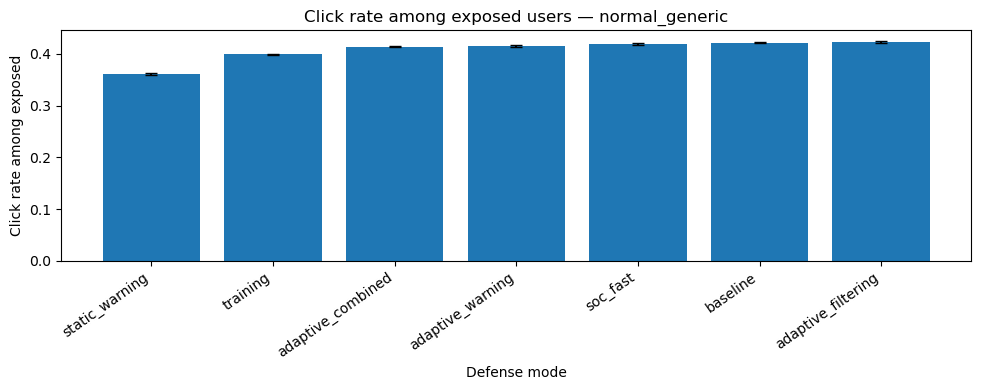

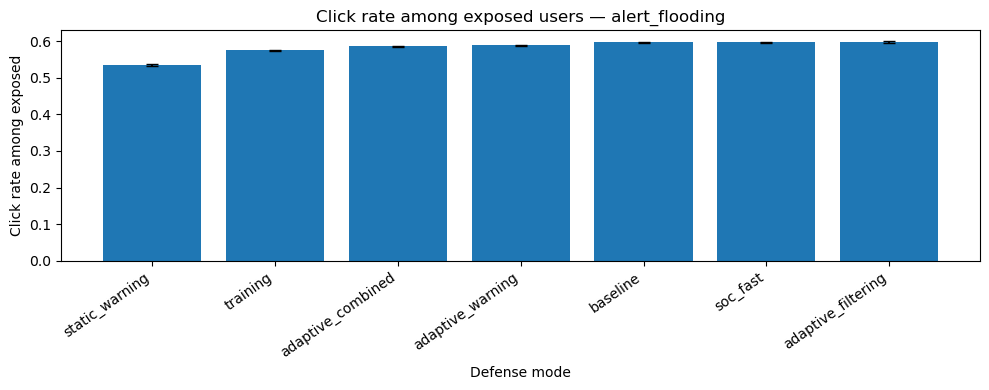

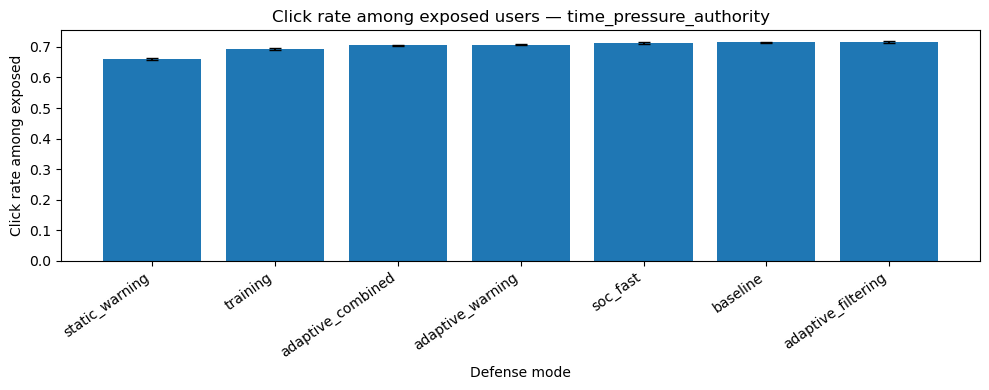

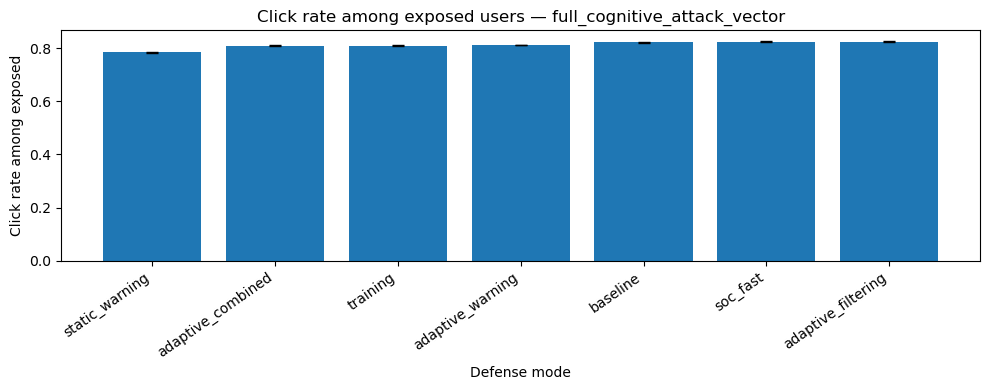

defense,adaptive_combined,adaptive_filtering,adaptive_warning,baseline,soc_fast,static_warning,training
campaign,,,,,,,
alert_flooding,1.75,-0.25,1.29,0.0,-0.05,10.34,3.54
full_cognitive_attack_vector,1.60,-0.20,1.29,0.0,-0.15,4.72,1.57
normal_generic,1.87,-0.22,1.63,0.0,0.45,14.52,5.40
time_pressure_authority,1.37,-0.09,1.13,0.0,0.26,7.76,3.15


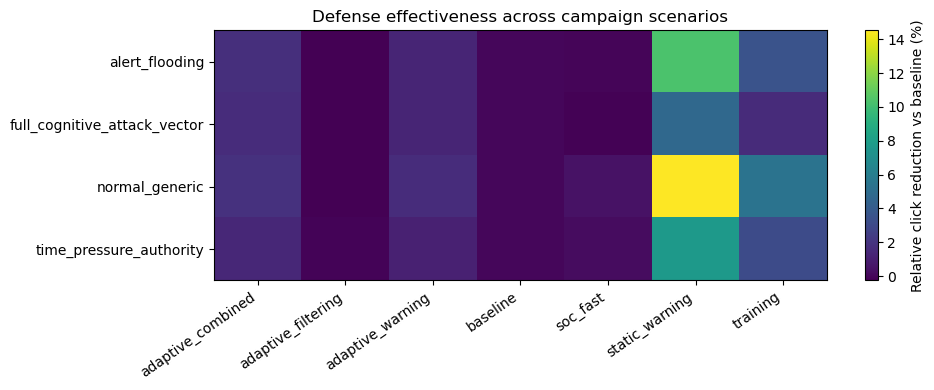

In [13]:
# for campaign in list(CAMPAIGN_SCENARIOS.keys()):
for campaign in BASE_CAMPAIGN_NAMES:
    d = summary[summary['campaign'] == campaign].sort_values('click_rate')
    plt.figure(figsize=(10, 4))
    plt.bar(d['defense'], d['click_rate'], yerr=d['click_ci95'], capsize=4)
    plt.title(f'Click rate among exposed users — {campaign}')
    plt.ylabel('Click rate among exposed')
    plt.xlabel('Defense mode')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'click_rate_{campaign}.png', dpi=160)
    plt.show()

reduction_table = summary.pivot(index='campaign', columns='defense', values='relative_click_reduction_pct')
display(reduction_table.round(2))
plt.figure(figsize=(10, 4))
plt.imshow(reduction_table.fillna(0).values, aspect='auto')
plt.colorbar(label='Relative click reduction vs baseline (%)')
plt.xticks(range(len(reduction_table.columns)), reduction_table.columns, rotation=35, ha='right')
plt.yticks(range(len(reduction_table.index)), reduction_table.index)
plt.title('Defense effectiveness across campaign scenarios')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'relative_click_reduction_heatmap.png', dpi=160)
plt.show()

## 11. Detector-accuracy sensitivity analysis

This is the strongest link to the thesis. It tests whether adaptive defense still helps when the cognitive-load detector is imperfect.

In [14]:
def run_detector_sensitivity(population: pd.DataFrame, config: SimConfig, detector_values=None, n_runs: Optional[int] = None) -> pd.DataFrame:
    if detector_values is None:
        detector_values = [0.50, 0.65, 0.80, 0.90, 1.00]
    if n_runs is None:
        n_runs = config.n_runs

    rows = []
    base_seed = 50_000

    for run in range(n_runs):
        for campaign in BASE_CAMPAIGN_NAMES:

            # Run non-adaptive baselines inside the same experiment
            for defense in ['baseline', 'static_warning']:
                defense_seed = {
                    'baseline': 101,
                    'static_warning': 202,
                }[defense]
                
                _, s = simulate_campaign(
                    population,
                    campaign,
                    defense,
                    config,
                    seed=base_seed + run * 10_000 + len(campaign) * 10 + defense_seed,
                    detector_ba=config.detector_ba,
                    return_agents=False
                )
                s['run'] = run
                s['sensitivity_condition'] = defense
                rows.append(s)

            # Run adaptive_combined under different detector qualities
            for ba in detector_values:
                _, s = simulate_campaign(
                    population,
                    campaign,
                    'adaptive_combined',
                    config,
                    seed=base_seed + run * 10_000 + int(ba * 1000) + len(campaign),
                    detector_ba=ba,
                    return_agents=False
                )
                s['run'] = run
                s['sensitivity_condition'] = f'adaptive_combined_ba_{ba:.2f}'
                rows.append(s)

        if (run + 1) % max(1, n_runs // 5) == 0:
            print(f'Sensitivity completed {run + 1}/{n_runs} runs')

    return pd.DataFrame(rows)

sensitivity_results = run_detector_sensitivity(population, config)
sensitivity_results.to_csv(OUTPUT_DIR / 'detector_sensitivity_results.csv', index=False)
print(sensitivity_results.shape)
display(sensitivity_results.head())

Sensitivity completed 40/200 runs
Sensitivity completed 80/200 runs
Sensitivity completed 120/200 runs
Sensitivity completed 160/200 runs
Sensitivity completed 200/200 runs
(5600, 33)


,campaign,environment,attack,defense,detector_ba,n_agents,exposure_rate,mean_cognitive_load,mean_behavioral_cognitive_load,cognitive_load_behavior_weight,static_warning_habituation,overloaded_rate,predicted_overload_rate,targeted_adaptive_eligible_rate,false_adaptation_rate,missed_overload_rate,net_expected_loss,warning_friction,click_rate_all,click_rate_exposed,compromise_rate_all,compromise_rate_clicked,report_rate_all,report_rate_exposed,median_time_to_report_h,containment_success_rate,org_breach_risk,expected_loss_score,high_load_click_rate,low_readiness_click_rate,intervention_cost,run,sensitivity_condition
0,normal_generic,normal,generic_phishing,baseline,0.65,2000,0.8295,0.284828,0.284828,1.0,0.0,0.0010,0.0000,0.0,0.0000,NaN,0.548970,0.00000,0.3605,0.434599,0.0505,0.140083,0.3605,0.434599,1.919454,0.326733,0.454145,0.009081,0.5,0.480488,0.00000,0,baseline
1,normal_generic,normal,generic_phishing,static_warning,0.65,2000,0.8310,0.284828,0.284828,1.0,0.0,0.0010,0.0000,0.0,0.0000,NaN,0.473617,0.00000,0.3055,0.367629,0.0425,0.139116,0.4315,0.519254,1.871063,0.352941,0.377392,0.007108,0.5,0.426829,0.04000,0,static_warning
2,normal_generic,normal,generic_phishing,adaptive_combined,0.50,2000,0.8430,0.284687,0.284687,1.0,0.0,0.0010,0.4925,0.0,0.4920,0.0005,0.660972,0.02955,0.3425,0.406287,0.0425,0.124088,0.3830,0.454330,1.972195,0.341176,0.372302,0.006985,1.0,0.458537,0.05955,0,adaptive_combined_ba_0.50
3,normal_generic,normal,generic_phishing,adaptive_combined,0.65,2000,0.8260,0.284724,0.284724,1.0,0.0,0.0010,0.3445,0.0,0.3440,0.0005,0.619626,0.02067,0.3460,0.418886,0.0505,0.145954,0.3525,0.426755,1.948968,0.425743,0.383488,0.007255,0.5,0.470732,0.05067,0,adaptive_combined_ba_0.65
4,normal_generic,normal,generic_phishing,adaptive_combined,0.80,2000,0.8350,0.284742,0.284742,1.0,0.0,0.0005,0.2055,0.0,0.2045,0.0000,0.573436,0.01233,0.3460,0.414371,0.0430,0.124277,0.3700,0.443114,1.941001,0.325581,0.394274,0.007520,1.0,0.436585,0.04233,0,adaptive_combined_ba_0.80


,campaign,defense,detector_ba,click_rate,click_ci95,report_rate,breach_risk,expected_loss,net_expected_loss,false_adaptation_rate,missed_overload_rate,warning_friction,intervention_cost,baseline_click_rate,baseline_breach_risk,baseline_net_expected_loss,static_warning_click_rate,static_warning_breach_risk,static_warning_net_expected_loss,relative_click_reduction_vs_baseline_pct,relative_net_loss_reduction_vs_baseline_pct,net_loss_advantage_vs_static_warning_pct
0,alert_flooding,adaptive_combined,0.50,0.5837,0.0018,0.3937,0.8057,0.0247,1.1473,0.4650,0.0345,0.0300,0.0600,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,2.2145,-15.3219,-24.0943
1,alert_flooding,adaptive_combined,0.65,0.5858,0.0017,0.3893,0.8147,0.0254,1.1024,0.3254,0.0245,0.0223,0.0523,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,1.8664,-10.8158,-19.2454
2,alert_flooding,adaptive_combined,0.80,0.5875,0.0018,0.3886,0.8176,0.0257,1.0511,0.1864,0.0142,0.0145,0.0445,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,1.5840,-5.6590,-13.6965
3,alert_flooding,adaptive_combined,0.90,0.5884,0.0017,0.3890,0.8245,0.0263,1.0225,0.0942,0.0069,0.0094,0.0394,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,1.4357,-2.7810,-10.5995
4,alert_flooding,adaptive_combined,1.00,0.5898,0.0016,0.3866,0.8300,0.0267,0.9918,0.0000,0.0000,0.0042,0.0342,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,1.1886,0.3075,-7.2761
5,alert_flooding,baseline,0.65,0.5969,0.0016,0.3793,0.8487,0.0285,0.9948,0.0000,NaN,0.0000,0.0000,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,0.0000,0.0000,-7.6069
6,alert_flooding,static_warning,0.65,0.5355,0.0017,0.4635,0.7780,0.0227,0.9245,0.0000,NaN,0.0000,0.0400,0.5969,0.8487,0.9948,0.5355,0.7780,0.9245,10.2839,7.0692,0.0000
7,full_cognitive_attack_vector,adaptive_combined,0.50,0.8092,0.0018,0.3437,0.9623,0.0495,1.2888,0.3191,0.1802,0.0299,0.0599,0.8226,0.9749,1.1272,0.7798,0.9606,1.1211,1.6284,-14.3338,-14.9599
8,full_cognitive_attack_vector,adaptive_combined,0.65,0.8074,0.0018,0.3467,0.9613,0.0491,1.2476,0.2246,0.1258,0.0275,0.0575,0.8226,0.9749,1.1272,0.7798,0.9606,1.1211,1.8472,-10.6813,-11.2875
9,full_cognitive_attack_vector,adaptive_combined,0.80,0.8060,0.0018,0.3510,0.9606,0.0488,1.2060,0.1282,0.0723,0.0250,0.0550,0.8226,0.9749,1.1272,0.7798,0.9606,1.1211,2.0141,-6.9890,-7.5749


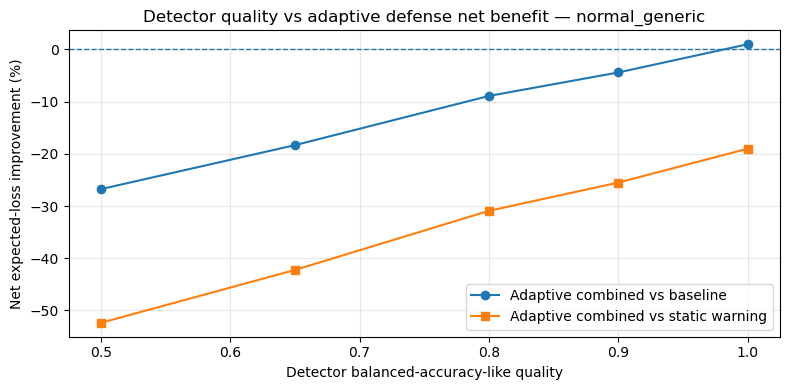

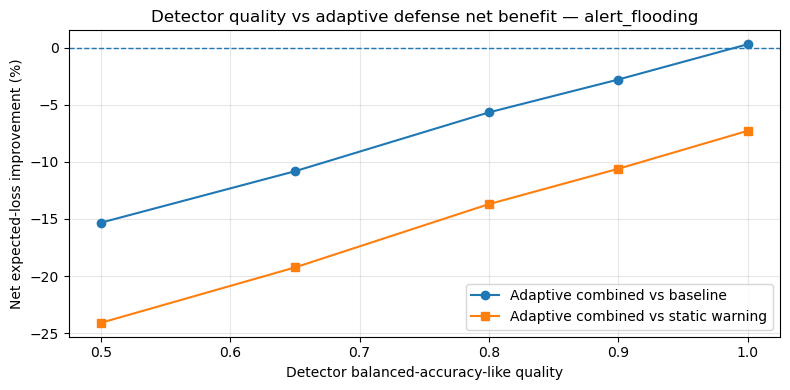

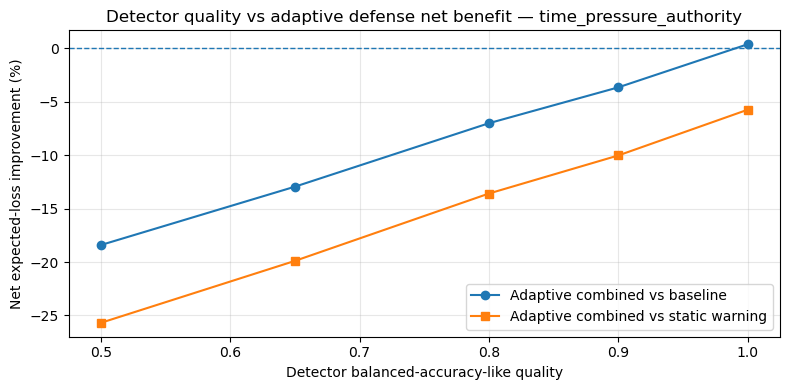

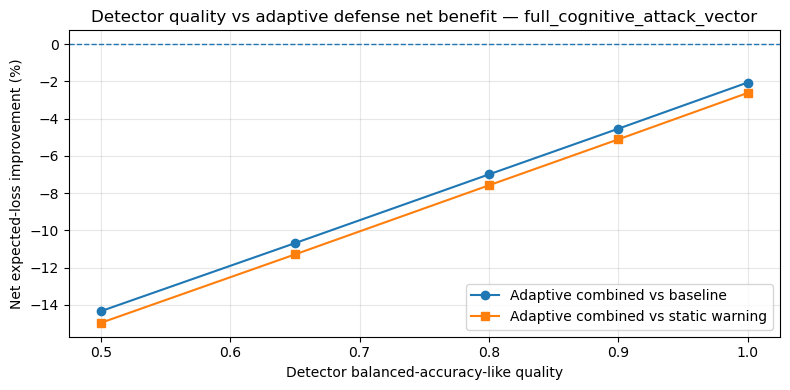

In [15]:
# Summarize detector sensitivity results
sens_summary = sensitivity_results.groupby(['campaign', 'defense', 'detector_ba']).agg(
    click_rate=('click_rate_exposed', 'mean'),
    click_ci95=('click_rate_exposed', ci95),
    report_rate=('report_rate_exposed', 'mean'),
    breach_risk=('org_breach_risk', 'mean'),
    expected_loss=('expected_loss_score', 'mean'),
    net_expected_loss=('net_expected_loss', 'mean'),
    false_adaptation_rate=('false_adaptation_rate', 'mean'),
    missed_overload_rate=('missed_overload_rate', 'mean'),
    warning_friction=('warning_friction', 'mean'),
    intervention_cost=('intervention_cost', 'mean'),
).reset_index()

# Extract baseline and static-warning reference values
baseline_ref = sens_summary[sens_summary['defense'] == 'baseline'][[
    'campaign', 'click_rate', 'breach_risk', 'net_expected_loss'
]].rename(columns={
    'click_rate': 'baseline_click_rate',
    'breach_risk': 'baseline_breach_risk',
    'net_expected_loss': 'baseline_net_expected_loss',
})

static_ref = sens_summary[sens_summary['defense'] == 'static_warning'][[
    'campaign', 'click_rate', 'breach_risk', 'net_expected_loss'
]].rename(columns={
    'click_rate': 'static_warning_click_rate',
    'breach_risk': 'static_warning_breach_risk',
    'net_expected_loss': 'static_warning_net_expected_loss',
})

sens_summary = sens_summary.merge(baseline_ref, on='campaign', how='left')
sens_summary = sens_summary.merge(static_ref, on='campaign', how='left')

sens_summary['relative_click_reduction_vs_baseline_pct'] = (
    100 * (sens_summary['baseline_click_rate'] - sens_summary['click_rate'])
    / sens_summary['baseline_click_rate']
)

sens_summary['relative_net_loss_reduction_vs_baseline_pct'] = (
    100 * (sens_summary['baseline_net_expected_loss'] - sens_summary['net_expected_loss'])
    / sens_summary['baseline_net_expected_loss']
)

sens_summary['net_loss_advantage_vs_static_warning_pct'] = (
    100 * (sens_summary['static_warning_net_expected_loss'] - sens_summary['net_expected_loss'])
    / sens_summary['static_warning_net_expected_loss']
)

sens_summary.to_csv(OUTPUT_DIR / 'detector_sensitivity_summary.csv', index=False)
display(sens_summary.round(4))

for campaign in BASE_CAMPAIGN_NAMES:
    d = sens_summary[
        (sens_summary['campaign'] == campaign)
        & (sens_summary['defense'] == 'adaptive_combined')
    ].sort_values('detector_ba')

    plt.figure(figsize=(8, 4))
    plt.plot(
        d['detector_ba'],
        d['relative_net_loss_reduction_vs_baseline_pct'],
        marker='o',
        label='Adaptive combined vs baseline'
    )
    plt.plot(
        d['detector_ba'],
        d['net_loss_advantage_vs_static_warning_pct'],
        marker='s',
        label='Adaptive combined vs static warning'
    )
    plt.axhline(0, linestyle='--', linewidth=1)
    plt.title(f'Detector quality vs adaptive defense net benefit — {campaign}')
    plt.xlabel('Detector balanced-accuracy-like quality')
    plt.ylabel('Net expected-loss improvement (%)')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'detector_sensitivity_net_loss_{campaign}.png', dpi=160)
    plt.show()

## 12. Role and cognitive-profile analysis

This section checks which roles and cognitive profiles benefit most from adaptive defense.

In [16]:
def run_agent_level_samples(population: pd.DataFrame, campaign='full_cognitive_attack_vector', defenses=None, n_runs=20) -> pd.DataFrame:
    if defenses is None:
        defenses = ['baseline', 'static_warning', 'adaptive_combined']
    frames = []
    for run in range(n_runs):
        for j, defense in enumerate(defenses):
            agents, _ = simulate_campaign(population, campaign, defense, config, 80_000 + run*100 + j, config.detector_ba, True)
            agents['run'] = run
            frames.append(agents)
    return pd.concat(frames, ignore_index=True)

agent_samples = run_agent_level_samples(population, n_runs=20)
print(agent_samples.shape)

role_summary = agent_samples.groupby(['defense','role']).agg(
    click_rate=('clicked','mean'), report_rate=('reported','mean'), overload_rate=('overloaded','mean'),
    compromise_rate=('compromised','mean'), mean_load=('cognitive_load','mean')).reset_index()
display(role_summary.round(3))

profile_summary = agent_samples.groupby(['defense','cognitive_profile']).agg(
    click_rate=('clicked','mean'), report_rate=('reported','mean'), overload_rate=('overloaded','mean'),
    compromise_rate=('compromised','mean'), mean_load=('cognitive_load','mean')).reset_index()
display(profile_summary.round(3))

(120000, 42)


,defense,role,click_rate,report_rate,overload_rate,compromise_rate,mean_load
0,adaptive_combined,CustomerCare,0.744,0.283,0.403,0.246,0.606
1,adaptive_combined,Engineering,0.117,0.062,0.201,0.039,0.533
2,adaptive_combined,Executive,0.702,0.274,0.399,0.262,0.612
3,adaptive_combined,Finance,0.695,0.299,0.321,0.230,0.572
4,adaptive_combined,HR,0.689,0.315,0.272,0.219,0.562
5,adaptive_combined,IT_SOC,0.113,0.075,0.207,0.040,0.550
6,adaptive_combined,Operations,0.675,0.284,0.308,0.221,0.566
7,adaptive_combined,Sales,0.161,0.066,0.345,0.051,0.593
8,baseline,CustomerCare,0.755,0.248,0.483,0.243,0.617
9,baseline,Engineering,0.122,0.058,0.255,0.040,0.539


,defense,cognitive_profile,click_rate,report_rate,overload_rate,compromise_rate,mean_load
0,adaptive_combined,authority_sensitive,0.404,0.162,0.471,0.131,0.572
1,adaptive_combined,cautious_user,0.418,0.188,0.031,0.136,0.561
2,adaptive_combined,fatigued_overloaded,0.464,0.161,0.968,0.159,0.606
3,adaptive_combined,neutral_user,0.413,0.171,0.258,0.135,0.571
4,adaptive_combined,resilient_skeptic,0.409,0.222,0.000,0.138,0.541
5,adaptive_combined,trained_but_fatigued_expert,0.450,0.207,0.236,0.153,0.585
6,adaptive_combined,trusting_fast_responder,0.485,0.190,0.560,0.162,0.579
7,baseline,authority_sensitive,0.419,0.137,0.604,0.138,0.585
8,baseline,cautious_user,0.425,0.190,0.049,0.137,0.562
9,baseline,fatigued_overloaded,0.477,0.114,0.975,0.156,0.628


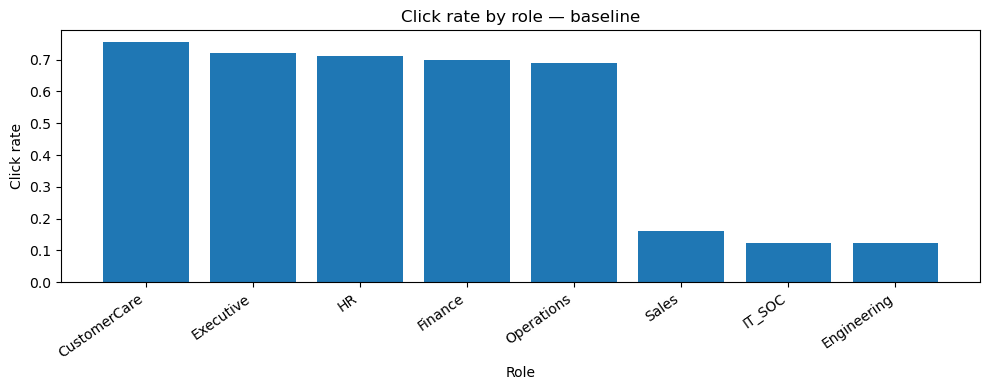

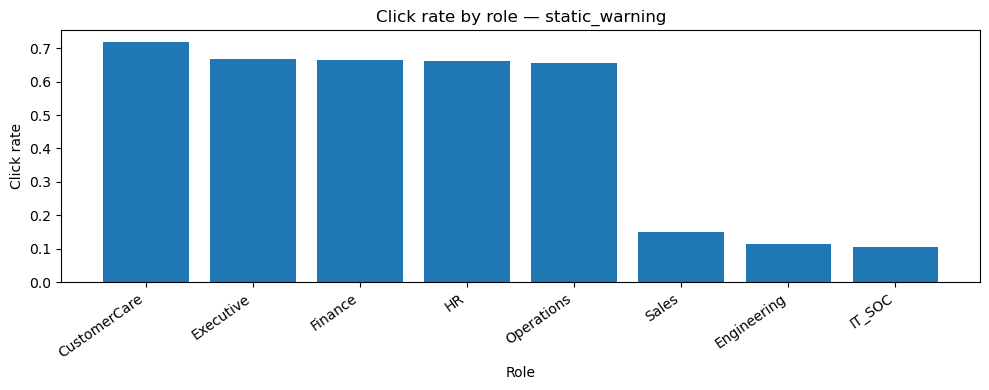

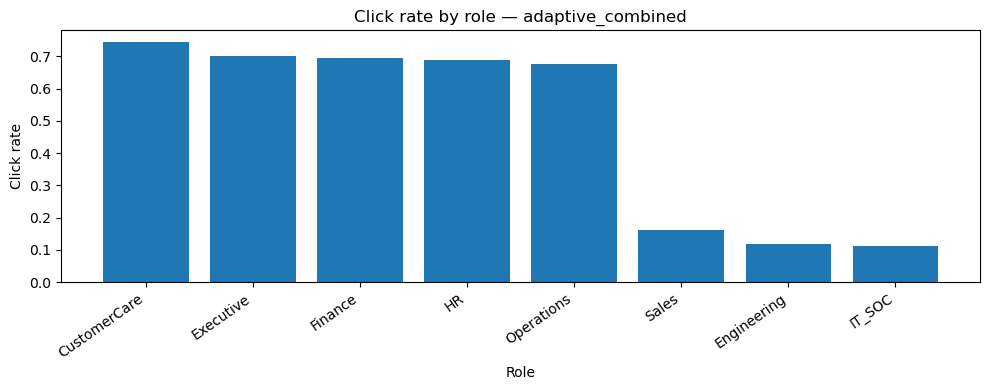

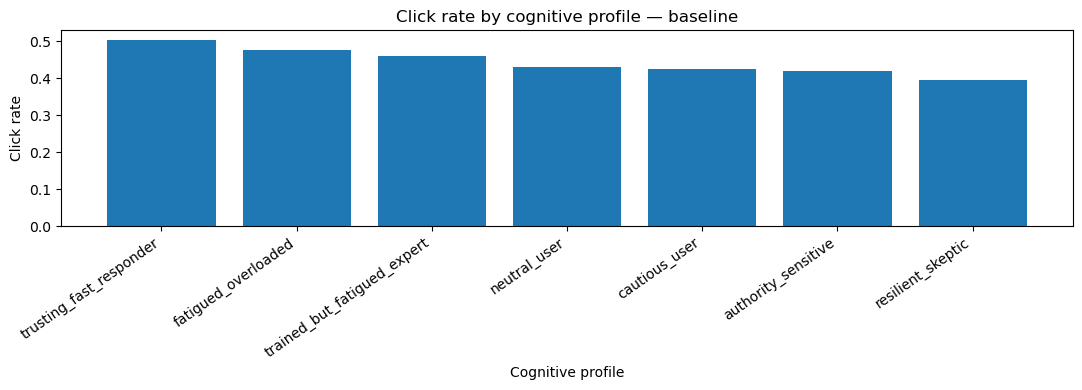

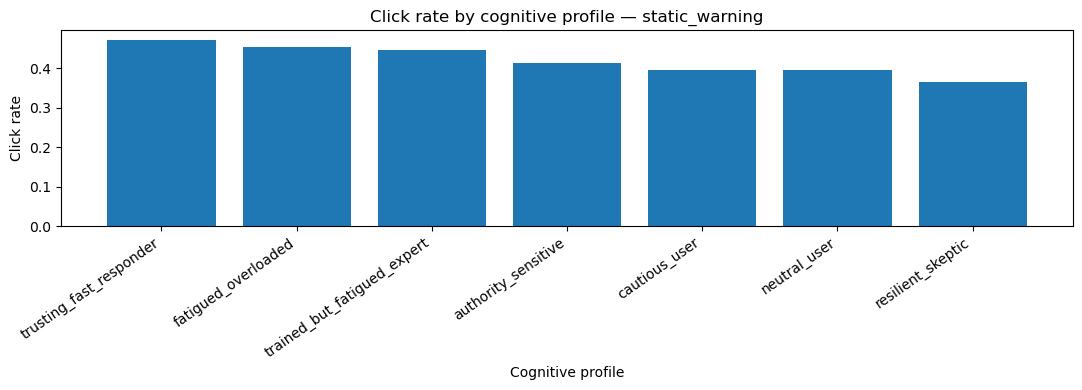

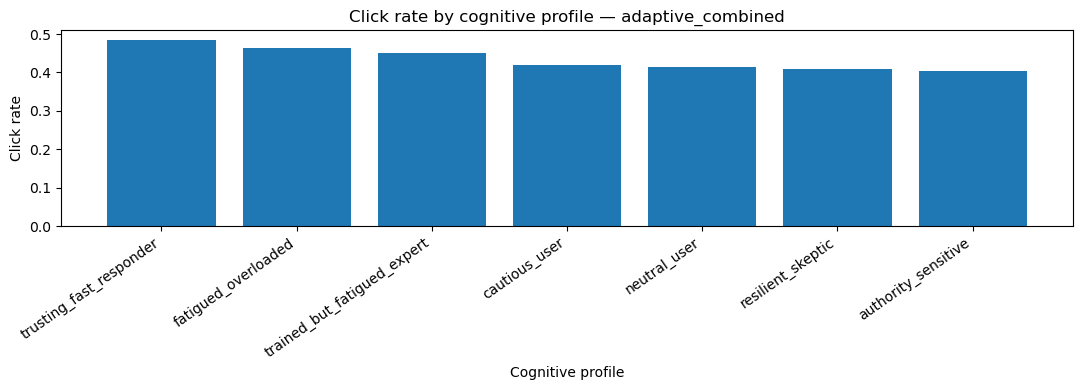

In [17]:
for defense in ['baseline', 'static_warning', 'adaptive_combined']:
    d = role_summary[role_summary['defense'] == defense].sort_values('click_rate', ascending=False)
    plt.figure(figsize=(10, 4))
    plt.bar(d['role'], d['click_rate'])
    plt.title(f'Click rate by role — {defense}')
    plt.ylabel('Click rate')
    plt.xlabel('Role')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'role_click_{defense}.png', dpi=160)
    plt.show()

for defense in ['baseline', 'static_warning', 'adaptive_combined']:
    d = profile_summary[profile_summary['defense'] == defense].sort_values('click_rate', ascending=False)
    plt.figure(figsize=(11, 4))
    plt.bar(d['cognitive_profile'], d['click_rate'])
    plt.title(f'Click rate by cognitive profile — {defense}')
    plt.ylabel('Click rate')
    plt.xlabel('Cognitive profile')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'profile_click_{defense}.png', dpi=160)
    plt.show()

## 13. Automatic ABM interpretation

This is a helper, not a final scientific interpretation.

In [18]:
print(summary.columns.tolist())
print(sens_summary.columns.tolist())

['campaign', 'defense', 'click_rate', 'click_ci95', 'report_rate', 'report_ci95', 'compromise_rate', 'org_breach_risk', 'overloaded_rate', 'false_adaptation_rate', 'missed_overload_rate', 'containment_success', 'median_ttr_h', 'expected_loss', 'net_expected_loss', 'warning_friction', 'intervention_cost', 'baseline_click_rate', 'baseline_breach_risk', 'baseline_expected_loss', 'baseline_net_expected_loss', 'absolute_click_reduction', 'relative_click_reduction_pct', 'absolute_breach_risk_reduction', 'relative_breach_risk_reduction_pct', 'absolute_expected_loss_reduction', 'relative_expected_loss_reduction_pct', 'absolute_net_loss_reduction', 'relative_net_loss_reduction_pct']
['campaign', 'defense', 'detector_ba', 'click_rate', 'click_ci95', 'report_rate', 'breach_risk', 'expected_loss', 'net_expected_loss', 'false_adaptation_rate', 'missed_overload_rate', 'warning_friction', 'intervention_cost', 'baseline_click_rate', 'baseline_breach_risk', 'baseline_net_expected_loss', 'static_warning

In [19]:
def generate_abm_report(summary: pd.DataFrame, sens_summary: pd.DataFrame) -> str:
    lines = []

    lines.append('COGNITIVE-LOAD-AWARE PHISHING ABM REPORT')
    lines.append('=' * 60)
    lines.append('')
    lines.append(
        'This report summarizes the simulation results for the cognitive-load-aware '
        'phishing-defense experiment. The experiment is a simulation-based extension, '
        'not an empirical estimate of real-world phishing rates.'
    )
    lines.append('')

    # ------------------------------------------------------------------
    # 1. Main ABM results
    # ------------------------------------------------------------------
    lines.append('1. Main ABM scenario-defense results')
    lines.append('-' * 60)
    lines.append(
        'The main ABM experiment compares defense strategies across phishing/social-engineering '
        'campaign scenarios. Results are interpreted using click rate, breach risk, expected loss, '
        'and net expected loss. Net expected loss is the strictest metric because it includes '
        'intervention cost, false adaptation, and missed overload penalties.'
    )
    lines.append('')

    for campaign in BASE_CAMPAIGN_NAMES:
        d = summary[summary['campaign'] == campaign].copy()

        if d.empty:
            lines.append(f'- {campaign}: no results found.')
            continue

        baseline_rows = d[d['defense'] == 'baseline']
        if baseline_rows.empty:
            lines.append(f'- {campaign}: baseline result missing.')
            continue

        baseline = baseline_rows.iloc[0]

        best_click = d.sort_values('click_rate', ascending=True).iloc[0]
        best_breach = d.sort_values('org_breach_risk', ascending=True).iloc[0]
        best_expected_loss = d.sort_values('expected_loss', ascending=True).iloc[0]
        best_net_loss = d.sort_values('net_expected_loss', ascending=True).iloc[0]

        lines.append(f'- {campaign}:')
        lines.append(
            f'  Baseline: click rate = {baseline["click_rate"]:.3f}, '
            f'breach-risk score = {baseline["org_breach_risk"]:.3f}, '
            f'expected loss = {baseline["expected_loss"]:.3f}, '
            f'net expected loss = {baseline["net_expected_loss"]:.3f}.'
        )

        lines.append(
            f'  Best click-rate defense: {best_click["defense"]} '
            f'(click rate = {best_click["click_rate"]:.3f}; '
            f'relative click reduction = {best_click["relative_click_reduction_pct"]:.1f}%).'
        )

        lines.append(
            f'  Best breach-risk defense: {best_breach["defense"]} '
            f'(breach-risk score = {best_breach["org_breach_risk"]:.3f}; '
            f'relative breach-risk reduction = {best_breach["relative_breach_risk_reduction_pct"]:.1f}%).'
        )

        lines.append(
            f'  Best expected-loss defense: {best_expected_loss["defense"]} '
            f'(expected loss = {best_expected_loss["expected_loss"]:.3f}; '
            f'relative expected-loss reduction = {best_expected_loss["relative_expected_loss_reduction_pct"]:.1f}%).'
        )

        lines.append(
            f'  Best net-loss defense: {best_net_loss["defense"]} '
            f'(net expected loss = {best_net_loss["net_expected_loss"]:.3f}; '
            f'relative net-loss reduction = {best_net_loss["relative_net_loss_reduction_pct"]:.1f}%).'
        )

        # Short interpretation hint
        if best_click["defense"] != best_net_loss["defense"]:
            lines.append(
                f'  Interpretation: the defense that minimizes clicking is not the same as the defense '
                f'that minimizes net expected loss. This suggests a trade-off between immediate click '
                f'prevention and broader organizational cost.'
            )
        else:
            lines.append(
                f'  Interpretation: the same defense minimizes both click rate and net expected loss '
                f'in this scenario.'
            )

        lines.append('')

    # ------------------------------------------------------------------
    # 2. Detector sensitivity results
    # ------------------------------------------------------------------
    lines.append('2. Detector-sensitivity analysis')
    lines.append('-' * 60)
    lines.append(
        'Detector sensitivity evaluates adaptive_combined defense under different '
        'balanced-accuracy-like detector qualities. The key question is whether adaptive defense '
        'remains useful when the cognitive-load detector is imperfect.'
    )
    lines.append(
        'The most important metric here is net expected loss, because click reduction alone can '
        'make weak detectors look artificially good when they over-intervene.'
    )
    lines.append('')

    adaptive_sens = sens_summary[sens_summary['defense'] == 'adaptive_combined'].copy()

    if adaptive_sens.empty:
        lines.append('No adaptive_combined detector-sensitivity results were found.')
    else:
        for campaign in BASE_CAMPAIGN_NAMES:
            s = adaptive_sens[adaptive_sens['campaign'] == campaign].copy()

            if s.empty:
                lines.append(f'- {campaign}: no adaptive_combined sensitivity results found.')
                continue

            s = s.sort_values('detector_ba')

            idx_065 = (s['detector_ba'] - 0.65).abs().idxmin()
            ba65 = s.loc[idx_065]

            oracle = s.loc[s['detector_ba'].idxmax()]
            best_net = s.loc[s['net_expected_loss'].idxmin()]

            lines.append(f'- {campaign}:')
            lines.append(
                f'  At detector BA≈{ba65["detector_ba"]:.2f}, adaptive_combined gives '
                f'{ba65["relative_click_reduction_vs_baseline_pct"]:.1f}% click reduction vs baseline, '
                f'{ba65["relative_net_loss_reduction_vs_baseline_pct"]:.1f}% net-loss reduction vs baseline, '
                f'and {ba65["net_loss_advantage_vs_static_warning_pct"]:.1f}% net-loss advantage vs static warning.'
            )

            lines.append(
                f'  At oracle/max detector BA={oracle["detector_ba"]:.2f}, adaptive_combined gives '
                f'{oracle["relative_click_reduction_vs_baseline_pct"]:.1f}% click reduction vs baseline, '
                f'{oracle["relative_net_loss_reduction_vs_baseline_pct"]:.1f}% net-loss reduction vs baseline, '
                f'and {oracle["net_loss_advantage_vs_static_warning_pct"]:.1f}% net-loss advantage vs static warning.'
            )

            lines.append(
                f'  Lowest net expected loss occurs at detector BA={best_net["detector_ba"]:.2f} '
                f'(net expected loss = {best_net["net_expected_loss"]:.3f}).'
            )

            if best_net["detector_ba"] < oracle["detector_ba"]:
                lines.append(
                    '  Interpretation: the best net-loss result does not occur at the oracle detector. '
                    'This may indicate that intervention effects, false-positive costs, or detector-cost assumptions '
                    'still need calibration.'
                )
            else:
                lines.append(
                    '  Interpretation: stronger cognitive-load detection reduces the net expected loss of adaptive defense. '
                    'However, this does not necessarily mean that adaptive defense outperforms static warning.'
                )

            lines.append('')

    # ------------------------------------------------------------------
    # 3. Overall interpretation
    # ------------------------------------------------------------------
    lines.append('3. Overall interpretation')
    lines.append('-' * 60)
    lines.append(
        'The ABM layer estimates short-term operational outcomes of phishing-based social engineering '
        'under cognitive load. The detector-sensitivity layer tests whether cognitive-load-aware adaptation '
        'remains useful when overload detection is imperfect.'
    )
    lines.append(
        'A defensible conclusion should distinguish between click prevention and organizational risk reduction. '
        'Under the current parameterization, static warning is the strongest overall defense, while adaptive combined '
        'defense improves as detector quality increases but does not generally outperform static warning in net expected loss. '
        'This suggests that cognitive-load-aware adaptation should be evaluated against simple static baselines and cost-aware metrics.'
    )
    lines.append('')

    # ------------------------------------------------------------------
    # 4. Interpretation guardrails
    # ------------------------------------------------------------------
    lines.append('4. Interpretation guardrails')
    lines.append('-' * 60)
    lines.append(
        'These are simulation results, not empirical measurements. They depend on the chosen behavioral equations, '
        'parameter values, payoff weights, detector quality assumptions, false-warning costs, and intervention effects.'
    )
    lines.append(
        'If weak detectors still outperform strong detectors in net expected loss, the model should be recalibrated: '
        'false-positive intervention may still be too beneficial, too cheap, or insufficiently fatigue-inducing.'
    )
    lines.append(
        'The safest scientific claim is that the notebook provides a formal simulation framework for evaluating '
        'cognitive-load-aware cybersecurity defenses, rather than proving that such systems will work in real organizations.'
    )

    return '\n'.join(lines)


abm_report = generate_abm_report(summary, sens_summary)
print(abm_report)

with open(OUTPUT_DIR / 'abm_report.txt', 'w', encoding='utf-8') as f:
    f.write(abm_report)

COGNITIVE-LOAD-AWARE PHISHING ABM REPORT

This report summarizes the simulation results for the cognitive-load-aware phishing-defense experiment. The experiment is a simulation-based extension, not an empirical estimate of real-world phishing rates.

1. Main ABM scenario-defense results
------------------------------------------------------------
The main ABM experiment compares defense strategies across phishing/social-engineering campaign scenarios. Results are interpreted using click rate, breach risk, expected loss, and net expected loss. Net expected loss is the strictest metric because it includes intervention cost, false adaptation, and missed overload penalties.

- normal_generic:
  Baseline: click rate = 0.422, breach-risk score = 0.446, expected loss = 0.009, net expected loss = 0.537.
  Best click-rate defense: static_warning (click rate = 0.361; relative click reduction = 14.5%).
  Best breach-risk defense: static_warning (breach-risk score = 0.362; relative breach-risk red

## 14. Evolutionary Game Theory layer

The ABM estimates outcomes for one campaign. The EGT layer asks which strategies become stable over repeated campaigns.

We estimate payoff values from ABM simulations for combinations of:

- user profile strategy
- defender strategy
- attacker strategy

Then we run discrete replicator dynamics.

In [21]:
USER_STRATEGIES = ['resilient_skeptic', 'cautious_user', 'neutral_user', 'trusting_fast_responder', 'fatigued_overloaded']
DEFENDER_STRATEGIES_EGT = ['baseline', 'training', 'static_warning', 'soc_fast', 'adaptive_combined']
ATTACKER_STRATEGIES_EGT = ['generic_phishing', 'authority_urgency', 'invoice_fraud', 'alert_flooding_attack', 'cognitive_attack_vector']

ATTACK_TO_ENV = {
    'generic_phishing': 'normal',
    'authority_urgency': 'time_pressure',
    'invoice_fraud': 'time_pressure',
    'alert_flooding_attack': 'alert_flooding',
    'cognitive_attack_vector': 'cognitive_attack_vector',
}
ATTACK_TO_CAMPAIGN_TEMP = {
    'generic_phishing': 'egt_generic',
    'authority_urgency': 'egt_authority',
    'invoice_fraud': 'egt_invoice',
    'alert_flooding_attack': 'egt_flooding',
    'cognitive_attack_vector': 'egt_cognitive_vector',
}
for attack_name, temp_campaign in ATTACK_TO_CAMPAIGN_TEMP.items():
    CAMPAIGN_SCENARIOS[temp_campaign] = {'environment': ATTACK_TO_ENV[attack_name], 'attack': attack_name}

DEFENSE_COST = {'baseline':0.00, 'training':0.055, 'static_warning':0.040, 'soc_fast':0.070, 'adaptive_combined':0.075}
USER_FRICTION_COST = {'resilient_skeptic':0.035, 'cautious_user':0.025, 'neutral_user':0.015, 'trusting_fast_responder':0.010, 'fatigued_overloaded':0.005}

In [22]:
def estimate_egt_payoff_matrix(config: SimConfig, n_runs_per_combo: int = 30, n_agents_per_combo: int = 900) -> pd.DataFrame:
    rows = []
    base_seed = 120_000
    cfg = SimConfig(**asdict(config))
    cfg.n_agents = n_agents_per_combo
    cfg.n_runs = n_runs_per_combo
    combo_counter = 0
    for u in USER_STRATEGIES:
        pop_u = generate_population(cfg, seed=base_seed + combo_counter, forced_profile=u)
        for d_strategy in DEFENDER_STRATEGIES_EGT:
            for a_strategy in ATTACKER_STRATEGIES_EGT:
                campaign = ATTACK_TO_CAMPAIGN_TEMP[a_strategy]
                sim_rows = []
                for r in range(n_runs_per_combo):
                    _, s = simulate_campaign(pop_u, campaign, d_strategy, cfg, base_seed + combo_counter*1000 + r, cfg.detector_ba, False)
                    sim_rows.append(s)
                sim = pd.DataFrame(sim_rows)
                click = sim['click_rate_exposed'].mean()
                report = sim['report_rate_exposed'].mean()
                compromise = sim['compromise_rate_all'].mean()
                breach = sim['org_breach_risk'].mean()
                contain = sim['containment_success_rate'].mean(skipna=True)
                load = sim['mean_cognitive_load'].mean()
                false_adapt = sim['false_adaptation_rate'].mean()

                attack_cost = ATTACK_STRATEGIES[a_strategy]['attack_cost']
                defense_cost = DEFENSE_COST[d_strategy]
                user_friction = USER_FRICTION_COST[u]
                contain_val = 0.0 if np.isnan(contain) else contain

                user_payoff = 1.00 - 0.85*click - 1.20*compromise + 0.25*report - 0.20*load - user_friction - 0.05*false_adapt
                defender_payoff = 1.00 - 1.80*breach - 1.20*compromise + 0.40*report + 0.45*contain_val - defense_cost - 0.10*false_adapt
                attacker_payoff = 0.60*click + 1.20*compromise + 1.80*breach - attack_cost - 0.40*contain_val - 0.25*report

                rows.append({
                    'user_strategy':u, 'defender_strategy':d_strategy, 'attacker_strategy':a_strategy,
                    'click_rate':click, 'report_rate':report, 'compromise_rate':compromise, 'org_breach_risk':breach,
                    'containment_success':contain, 'mean_cognitive_load':load, 'false_adaptation_rate':false_adapt,
                    'user_payoff':user_payoff, 'defender_payoff':defender_payoff, 'attacker_payoff':attacker_payoff,
                })
                combo_counter += 1
    return pd.DataFrame(rows)

payoff_matrix = estimate_egt_payoff_matrix(config, n_runs_per_combo=30, n_agents_per_combo=900)
payoff_matrix.to_csv(OUTPUT_DIR / 'egt_payoff_matrix.csv', index=False)
print(payoff_matrix.shape)
display(payoff_matrix.head())

(125, 13)


,user_strategy,defender_strategy,attacker_strategy,click_rate,report_rate,compromise_rate,org_breach_risk,containment_success,mean_cognitive_load,false_adaptation_rate,user_payoff,defender_payoff,attacker_payoff
0,resilient_skeptic,baseline,generic_phishing,0.329320,0.503179,0.038481,0.187783,0.271474,0.248046,0.0,0.715086,0.939248,0.327395
1,resilient_skeptic,baseline,authority_urgency,0.598930,0.444792,0.053815,0.375772,0.272648,0.410203,0.0,0.420489,0.559641,0.810069
2,resilient_skeptic,baseline,invoice_fraud,0.579722,0.444329,0.044296,0.339572,0.258238,0.396763,0.0,0.450810,0.629554,0.717840
3,resilient_skeptic,baseline,alert_flooding_attack,0.491655,0.448493,0.086074,0.473267,0.269073,0.400678,0.0,0.475792,0.345311,0.940409
4,resilient_skeptic,baseline,cognitive_attack_vector,0.745065,0.384051,0.134222,0.763275,0.207810,0.540548,0.0,0.158531,-0.287826,1.662863


## 15. Replicator dynamics

Strategies with above-average payoff increase in frequency; strategies with below-average payoff decrease.

In [23]:
def normalize(x, eps=1e-12):
    x = np.asarray(x, dtype=float)
    x = np.maximum(x, eps)
    return x / x.sum()


def replicator_update(freq, fitness, learning_rate=0.45):
    freq = normalize(freq)
    fitness = np.asarray(fitness, dtype=float)
    shifted = fitness - np.dot(freq, fitness)
    updated = freq * np.exp(learning_rate * shifted)
    return normalize(updated)


def expected_payoffs(payoffs: pd.DataFrame, user_freq, defender_freq, attacker_freq):
    uf = dict(zip(USER_STRATEGIES, user_freq))
    df = dict(zip(DEFENDER_STRATEGIES_EGT, defender_freq))
    af = dict(zip(ATTACKER_STRATEGIES_EGT, attacker_freq))
    user_fit = []
    for u in USER_STRATEGIES:
        sub = payoffs[payoffs['user_strategy'] == u]
        user_fit.append(sum(row.user_payoff * df[row.defender_strategy] * af[row.attacker_strategy] for row in sub.itertuples()))
    defender_fit = []
    for d in DEFENDER_STRATEGIES_EGT:
        sub = payoffs[payoffs['defender_strategy'] == d]
        defender_fit.append(sum(row.defender_payoff * uf[row.user_strategy] * af[row.attacker_strategy] for row in sub.itertuples()))
    attacker_fit = []
    for a in ATTACKER_STRATEGIES_EGT:
        sub = payoffs[payoffs['attacker_strategy'] == a]
        attacker_fit.append(sum(row.attacker_payoff * uf[row.user_strategy] * df[row.defender_strategy] for row in sub.itertuples()))
    return np.array(user_fit), np.array(defender_fit), np.array(attacker_fit)


def expected_metrics(payoffs: pd.DataFrame, user_freq, defender_freq, attacker_freq):
    uf = dict(zip(USER_STRATEGIES, user_freq))
    df = dict(zip(DEFENDER_STRATEGIES_EGT, defender_freq))
    af = dict(zip(ATTACKER_STRATEGIES_EGT, attacker_freq))
    metrics = {m:0.0 for m in ['click_rate','report_rate','compromise_rate','org_breach_risk','mean_cognitive_load']}
    for row in payoffs.itertuples():
        w = uf[row.user_strategy] * df[row.defender_strategy] * af[row.attacker_strategy]
        for m in metrics:
            metrics[m] += w * getattr(row, m)
    return metrics


def run_replicator_dynamics(payoffs: pd.DataFrame, steps=80, learning_rate=0.45):
    user_freq = normalize(np.ones(len(USER_STRATEGIES)))
    defender_freq = normalize(np.ones(len(DEFENDER_STRATEGIES_EGT)))
    attacker_freq = normalize(np.ones(len(ATTACKER_STRATEGIES_EGT)))
    rows = []
    for t in range(steps + 1):
        metrics = expected_metrics(payoffs, user_freq, defender_freq, attacker_freq)
        row = {'t':t, **metrics}
        for s, v in zip(USER_STRATEGIES, user_freq): row[f'user_{s}'] = v
        for s, v in zip(DEFENDER_STRATEGIES_EGT, defender_freq): row[f'def_{s}'] = v
        for s, v in zip(ATTACKER_STRATEGIES_EGT, attacker_freq): row[f'att_{s}'] = v
        rows.append(row)
        if t < steps:
            u_fit, d_fit, a_fit = expected_payoffs(payoffs, user_freq, defender_freq, attacker_freq)
            user_freq = replicator_update(user_freq, u_fit, learning_rate)
            defender_freq = replicator_update(defender_freq, d_fit, learning_rate)
            attacker_freq = replicator_update(attacker_freq, a_fit, learning_rate)
    return pd.DataFrame(rows)

rep = run_replicator_dynamics(payoff_matrix, steps=80, learning_rate=0.45)
rep.to_csv(OUTPUT_DIR / 'egt_replicator_dynamics.csv', index=False)
display(rep.head())
display(rep.tail())

,t,click_rate,report_rate,compromise_rate,org_breach_risk,mean_cognitive_load,user_resilient_skeptic,user_cautious_user,user_neutral_user,user_trusting_fast_responder,user_fatigued_overloaded,def_baseline,def_training,def_static_warning,def_soc_fast,def_adaptive_combined,att_generic_phishing,att_authority_urgency,att_invoice_fraud,att_alert_flooding_attack,att_cognitive_attack_vector
0,0,0.638591,0.387160,0.082095,0.473407,0.437443,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000
1,1,0.658481,0.383172,0.088619,0.508181,0.454057,0.210758,0.204216,0.199194,0.194940,0.190893,0.196986,0.195391,0.209167,0.201985,0.196470,0.148325,0.192726,0.184744,0.204077,0.270127
2,2,0.678130,0.379098,0.095611,0.544264,0.470779,0.221741,0.208166,0.198135,0.189786,0.182171,0.193895,0.190678,0.218416,0.203796,0.193215,0.105833,0.178575,0.164140,0.200184,0.351268
3,3,0.697025,0.375119,0.102755,0.580292,0.487065,0.232883,0.211832,0.196849,0.184584,0.173853,0.190731,0.185897,0.227707,0.205403,0.190262,0.072612,0.159009,0.140190,0.188663,0.439526
4,4,0.714573,0.371447,0.109679,0.614687,0.502312,0.244121,0.215203,0.195361,0.179372,0.165943,0.187505,0.181085,0.237007,0.206786,0.187616,0.047950,0.136190,0.115207,0.170990,0.529663


,t,click_rate,report_rate,compromise_rate,org_breach_risk,mean_cognitive_load,user_resilient_skeptic,user_cautious_user,user_neutral_user,user_trusting_fast_responder,user_fatigued_overloaded,def_baseline,def_training,def_static_warning,def_soc_fast,def_adaptive_combined,att_generic_phishing,att_authority_urgency,att_invoice_fraud,att_alert_flooding_attack,att_cognitive_attack_vector
76,76,0.700629,0.456435,0.126039,0.706859,0.543350,0.887170,0.090041,0.018391,0.003208,0.001190,0.008401,0.005966,0.925886,0.045360,0.014387,1.000000e-12,1.000000e-12,1.000000e-12,3.100730e-11,1.0
77,77,0.700160,0.456921,0.125952,0.706529,0.543248,0.890790,0.087632,0.017512,0.002976,0.001090,0.007872,0.005580,0.929499,0.043489,0.013560,1.000000e-12,1.000000e-12,1.000000e-12,2.209380e-11,1.0
78,78,0.699710,0.457386,0.125867,0.706212,0.543149,0.894296,0.085274,0.016672,0.002760,0.000998,0.007374,0.005217,0.932946,0.041684,0.012779,1.000000e-12,1.000000e-12,1.000000e-12,1.574040e-11,1.0
79,79,0.699278,0.457831,0.125786,0.705907,0.543054,0.897691,0.082967,0.015870,0.002559,0.000913,0.006905,0.004876,0.936235,0.039945,0.012039,1.000000e-12,1.000000e-12,1.000000e-12,1.121251e-11,1.0
80,80,0.698863,0.458256,0.125708,0.705614,0.542963,0.900979,0.080710,0.015103,0.002372,0.000836,0.006465,0.004557,0.939370,0.038268,0.011340,1.000000e-12,1.000000e-12,1.000000e-12,7.986093e-12,1.0


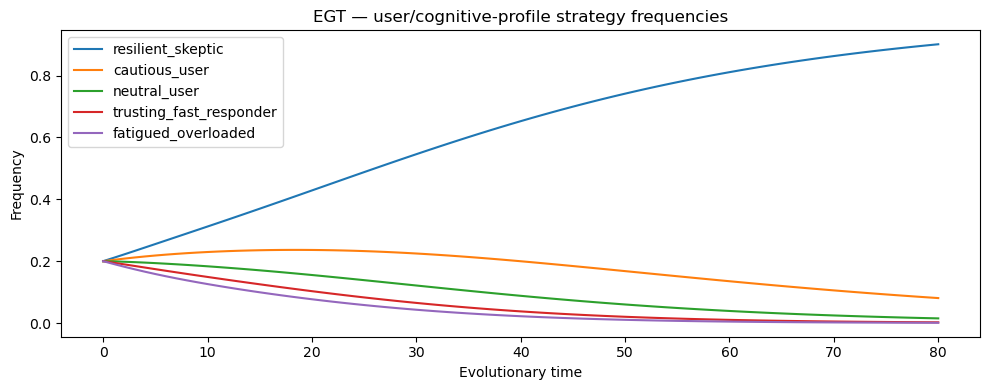

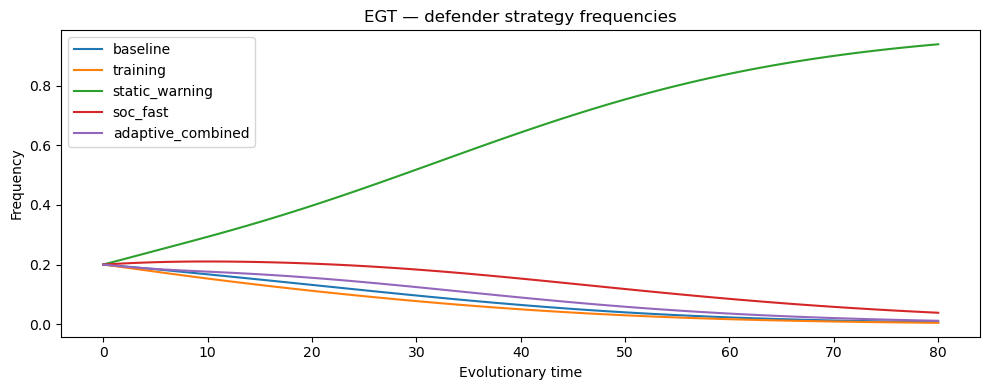

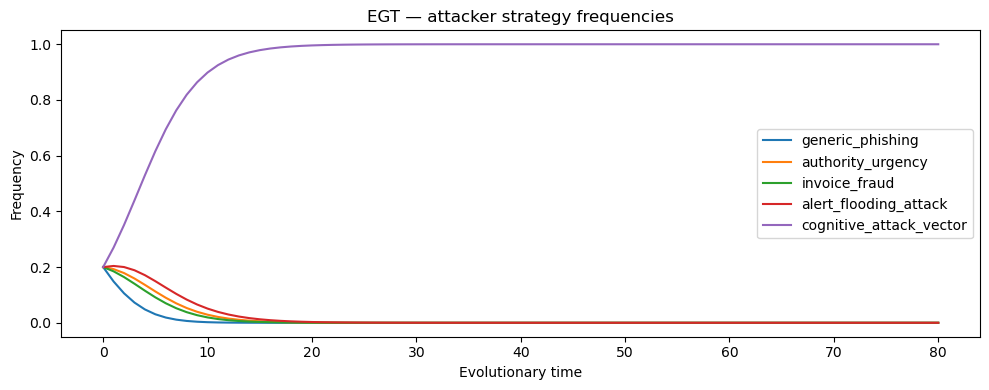

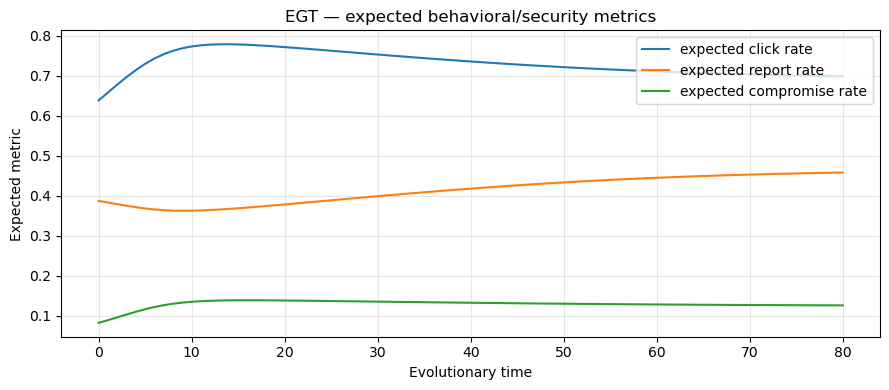

In [26]:
plt.figure(figsize=(10, 4))
for s in USER_STRATEGIES:
    plt.plot(rep['t'], rep[f'user_{s}'], label=s)
plt.title('EGT — user/cognitive-profile strategy frequencies')
plt.xlabel('Evolutionary time')
plt.ylabel('Frequency')
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'egt_user_strategies.png', dpi=160)
plt.show()

plt.figure(figsize=(10, 4))
for s in DEFENDER_STRATEGIES_EGT:
    plt.plot(rep['t'], rep[f'def_{s}'], label=s)
plt.title('EGT — defender strategy frequencies')
plt.xlabel('Evolutionary time')
plt.ylabel('Frequency')
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'egt_defender_strategies.png', dpi=160)
plt.show()

plt.figure(figsize=(10, 4))
for s in ATTACKER_STRATEGIES_EGT:
    plt.plot(rep['t'], rep[f'att_{s}'], label=s)
plt.title('EGT — attacker strategy frequencies')
plt.xlabel('Evolutionary time')
plt.ylabel('Frequency')
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'egt_attacker_strategies.png', dpi=160)
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(rep['t'], rep['click_rate'], label='expected click rate')
plt.plot(rep['t'], rep['report_rate'], label='expected report rate')
plt.plot(rep['t'], rep['compromise_rate'], label='expected compromise rate')
plt.title('EGT — expected behavioral/security metrics')
plt.xlabel('Evolutionary time')
plt.ylabel('Expected metric')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'egt_expected_metrics.png', dpi=160)
plt.show()

## 16. Automatic EGT interpretation

In [27]:
def generate_egt_report(rep: pd.DataFrame) -> str:
    final = rep.iloc[-1]
    dominant_user = max(USER_STRATEGIES, key=lambda s: final[f'user_{s}'])
    dominant_def = max(DEFENDER_STRATEGIES_EGT, key=lambda s: final[f'def_{s}'])
    dominant_att = max(ATTACKER_STRATEGIES_EGT, key=lambda s: final[f'att_{s}'])
    lines = []
    lines.append('EGT RESULT SUMMARY')
    lines.append('=' * 72)
    lines.append(f'Dominant user/cognitive profile strategy: {dominant_user} ({final[f"user_{dominant_user}"]:.3f})')
    lines.append(f'Dominant defender strategy: {dominant_def} ({final[f"def_{dominant_def}"]:.3f})')
    lines.append(f'Dominant attacker strategy: {dominant_att} ({final[f"att_{dominant_att}"]:.3f})')
    lines.append(f'Final expected click rate: {final["click_rate"]:.3f}')
    lines.append(f'Final expected report rate: {final["report_rate"]:.3f}')
    lines.append(f'Final expected compromise rate: {final["compromise_rate"]:.3f}')
    lines.append(f'Final expected organization breach risk: {final["org_breach_risk"]:.3f}')
    lines.append(f'Final expected cognitive load: {final["mean_cognitive_load"]:.3f}')
    lines.append('')
    lines.append('Interpretation: EGT does not prove real-world dominance. It shows what follows from the payoff assumptions encoded here.')
    return '\n'.join(lines)

egt_report = generate_egt_report(rep)
print(egt_report)
with open(OUTPUT_DIR / 'egt_report.txt', 'w', encoding='utf-8') as f:
    f.write(egt_report)

EGT RESULT SUMMARY
Dominant user/cognitive profile strategy: resilient_skeptic (0.901)
Dominant defender strategy: static_warning (0.939)
Dominant attacker strategy: cognitive_attack_vector (1.000)
Final expected click rate: 0.699
Final expected report rate: 0.458
Final expected compromise rate: 0.126
Final expected organization breach risk: 0.706
Final expected cognitive load: 0.543

Interpretation: EGT does not prove real-world dominance. It shows what follows from the payoff assumptions encoded here.


## 17. Text for report

Recommended method description:

> The academic mobility extension used agent-based modeling to simulate phishing-based social engineering as an initial-access scenario under cognitive load. Agents were represented using both organizational roles and cognitive resilience profiles. Social-engineering attacks were formalized as pretext vectors containing urgency, authority, personalization, novelty, plausibility, and visible suspiciousness cues. Cognitive load was modeled as a dynamic state influenced by organizational stress, alert flooding, time pressure, pattern disruption, role stress, fatigue, and defensive readiness. The simulation compared static defenses with adaptive defenses triggered by an imperfect cognitive-load detector. A second Evolutionary Game Theory layer used ABM-derived payoffs to examine the long-term stability of user, defender, and attacker strategies.

Recommended novelty statement:

> The novelty of the experiment lies in testing not merely whether stress increases phishing vulnerability, but when cognitive-load-aware adaptive defense outperforms static interventions and how sensitive this advantage is to detector reliability, false adaptations, and missed overload states.

Recommended limitation statement:

> The simulation is not an empirical measurement of real phishing behavior. Its parameters are theoretical and should be interpreted as assumptions. The results are useful for comparing mechanisms and generating hypotheses, but real deployment would require validation using behavioral experiments, SOC logs, or controlled cyber-range studies.

## 18. Future extensions

1. Replace theoretical parameters with empirical values from phishing-awareness experiments or cyber-range studies.
2. Add behavioral calibration using real click/report data, if available and ethical.
3. Add realistic SOC queue dynamics for analyst overload and alert triage.
4. Use a bandit/RL model only if attacker strategy learning becomes the main research question.
5. Connect the cognitive-load detector to real EEG/fNIRS/eye-tracking data in a controlled study.
6. Use MiroFish only after this notebook is stable. It is not required for the present experiment.

## 19. Export manifest

All CSV tables, PNG figures, and TXT summaries are saved in `cogload_phishing_outputs/`.

In [28]:
manifest = sorted(str(p) for p in OUTPUT_DIR.glob('*'))
print('\n'.join(manifest))

cogload_phishing_outputs_last\abm_report.txt
cogload_phishing_outputs_last\click_rate_alert_flooding.png
cogload_phishing_outputs_last\click_rate_full_cognitive_attack_vector.png
cogload_phishing_outputs_last\click_rate_normal_generic.png
cogload_phishing_outputs_last\click_rate_time_pressure_authority.png
cogload_phishing_outputs_last\detector_sensitivity_net_loss_alert_flooding.png
cogload_phishing_outputs_last\detector_sensitivity_net_loss_full_cognitive_attack_vector.png
cogload_phishing_outputs_last\detector_sensitivity_net_loss_normal_generic.png
cogload_phishing_outputs_last\detector_sensitivity_net_loss_time_pressure_authority.png
cogload_phishing_outputs_last\detector_sensitivity_results.csv
cogload_phishing_outputs_last\detector_sensitivity_summary.csv
cogload_phishing_outputs_last\egt_attacker_strategies.png
cogload_phishing_outputs_last\egt_defender_strategies.png
cogload_phishing_outputs_last\egt_expected_metrics.png
cogload_phishing_outputs_last\egt_payoff_matrix.csv
cogl

## 20. RACS robustness and ablation experiments

This section extends the original academic-mobility simulation for a conference-style paper. The original experiment above is kept as the default configuration. The cells below add five controlled extensions:

1. **Defense-cost sensitivity:** test whether the default conclusion depends on adaptive-intervention cost and false-positive/friction penalties.
2. **Static-warning habituation:** reduce static-warning effectiveness to model warning fatigue.
3. **Targeted adaptive defense:** apply adaptive combined intervention only to high-risk/high-access/high-exposure users.
4. **Comparison with the original default results:** compute deltas against the original default baseline, static warning, and adaptive combined results.
5. **Cognitive-load ablation:** keep cognitive load computed, but remove its direct behavioral effect to test whether results are actually driven by the cognitive-load mechanism.

For a quick test, set `RACS_N_RUNS = 20`. For final paper tables, use `RACS_N_RUNS = config.n_runs` (200 by default).

In [29]:
# -------------------------------
# RACS extension helpers
# -------------------------------
RACS_N_RUNS = config.n_runs          # change to 20 for debugging; use config.n_runs for final results
RACS_CORE_DEFENSES = ['baseline', 'static_warning', 'adaptive_combined', 'adaptive_combined_targeted']
RACS_ROBUSTNESS_DIR = OUTPUT_DIR / 'racs_robustness'
RACS_ROBUSTNESS_DIR.mkdir(parents=True, exist_ok=True)


def clone_config(base_config: SimConfig, **updates) -> SimConfig:
    """Return a modified copy of the simulation configuration."""
    return replace(base_config, **updates)


def run_scenario_experiment(population: pd.DataFrame,
                            base_config: SimConfig,
                            scenario_type: str,
                            scenario_name: str,
                            updates: Dict,
                            defenses=None,
                            campaigns=None,
                            n_runs: Optional[int] = None,
                            seed_offset: int = 200_000) -> pd.DataFrame:
    """Run one robustness/ablation scenario and annotate all output rows."""
    if defenses is None:
        defenses = RACS_CORE_DEFENSES
    if campaigns is None:
        campaigns = BASE_CAMPAIGN_NAMES

    cfg = clone_config(base_config, **updates)
    if n_runs is not None:
        cfg = clone_config(cfg, n_runs=n_runs)

    rows = []
    for run in range(cfg.n_runs):
        for c_i, campaign in enumerate(campaigns):
            for d_i, defense in enumerate(defenses):
                _, s = simulate_campaign(
                    population,
                    campaign,
                    defense,
                    cfg,
                    seed=seed_offset + run * 10_000 + c_i * 100 + d_i,
                    detector_ba=cfg.detector_ba,
                    return_agents=False,
                )
                s['run'] = run
                s['scenario_type'] = scenario_type
                s['scenario_name'] = scenario_name
                for key, value in updates.items():
                    s[f'cfg_{key}'] = value
                rows.append(s)

        if (run + 1) % max(1, cfg.n_runs // 5) == 0:
            print(f'{scenario_type} / {scenario_name}: completed {run + 1}/{cfg.n_runs} runs')

    return pd.DataFrame(rows)


def summarize_robustness_results(df: pd.DataFrame) -> pd.DataFrame:
    """Compact summary used for paper tables."""
    group_cols = ['scenario_type', 'scenario_name', 'campaign', 'defense']
    metrics = [
        'click_rate_exposed', 'report_rate_exposed', 'compromise_rate_all',
        'org_breach_risk', 'net_expected_loss', 'overloaded_rate',
        'predicted_overload_rate', 'targeted_adaptive_eligible_rate',
        'false_adaptation_rate', 'missed_overload_rate',
        'mean_cognitive_load', 'mean_behavioral_cognitive_load',
        'intervention_cost', 'warning_friction'
    ]
    available_metrics = [m for m in metrics if m in df.columns]
    summary = df.groupby(group_cols)[available_metrics].agg(['mean', 'std']).reset_index()
    summary.columns = ['_'.join(c).rstrip('_') if isinstance(c, tuple) else c for c in summary.columns]
    return summary


def summarize_default_results(main_results: pd.DataFrame) -> pd.DataFrame:
    """Convert the original main experiment into the same summary format."""
    default_df = main_results.copy()
    default_df['scenario_type'] = 'original_default'
    default_df['scenario_name'] = 'original_default'
    return summarize_robustness_results(default_df)

print('RACS robustness output directory:', RACS_ROBUSTNESS_DIR.resolve())
print('RACS_N_RUNS =', RACS_N_RUNS)
print('Core defenses:', RACS_CORE_DEFENSES)

RACS robustness output directory: C:\Users\User\Jupyter projects\eeg-analysis\academic mobility\cogload_phishing_outputs_last\racs_robustness
RACS_N_RUNS = 200
Core defenses: ['baseline', 'static_warning', 'adaptive_combined', 'adaptive_combined_targeted']


### 20.1 Defense-cost sensitivity analysis

This experiment tests whether the main conclusion depends on cost assumptions. It varies adaptive combined intervention cost and false-positive/friction penalties while keeping the original model equations otherwise unchanged.

In [30]:
# -------------------------------
# 20.1 Defense-cost sensitivity
# -------------------------------
cost_scenarios = {
    'default_costs': {},
    'low_adaptive_cost': {
        'adaptive_combined_cost_per_predicted': 0.030,
        'adaptive_combined_fixed_cost': 0.015,
    },
    'high_adaptive_cost': {
        'adaptive_combined_cost_per_predicted': 0.090,
        'adaptive_combined_fixed_cost': 0.045,
    },
    'low_false_positive_penalty': {
        'false_adaptation_loss_weight': 0.10,
        'warning_friction_cost': 0.03,
    },
    'high_false_positive_penalty': {
        'false_adaptation_loss_weight': 0.50,
        'warning_friction_cost': 0.10,
    },
}

cost_results = []
for scenario_name, updates in cost_scenarios.items():
    cost_results.append(
        run_scenario_experiment(
            population=population,
            base_config=config,
            scenario_type='cost_sensitivity',
            scenario_name=scenario_name,
            updates=updates,
            defenses=RACS_CORE_DEFENSES,
            n_runs=RACS_N_RUNS,
            seed_offset=210_000,
        )
    )

cost_sensitivity_results = pd.concat(cost_results, ignore_index=True)
cost_sensitivity_results.to_csv(RACS_ROBUSTNESS_DIR / 'cost_sensitivity_results.csv', index=False)
cost_sensitivity_summary = summarize_robustness_results(cost_sensitivity_results)
cost_sensitivity_summary.to_csv(RACS_ROBUSTNESS_DIR / 'cost_sensitivity_summary.csv', index=False)

print(cost_sensitivity_results.shape)
display(cost_sensitivity_summary.head(20))

cost_sensitivity / default_costs: completed 40/200 runs
cost_sensitivity / default_costs: completed 80/200 runs
cost_sensitivity / default_costs: completed 120/200 runs
cost_sensitivity / default_costs: completed 160/200 runs
cost_sensitivity / default_costs: completed 200/200 runs
cost_sensitivity / low_adaptive_cost: completed 40/200 runs
cost_sensitivity / low_adaptive_cost: completed 80/200 runs
cost_sensitivity / low_adaptive_cost: completed 120/200 runs
cost_sensitivity / low_adaptive_cost: completed 160/200 runs
cost_sensitivity / low_adaptive_cost: completed 200/200 runs
cost_sensitivity / high_adaptive_cost: completed 40/200 runs
cost_sensitivity / high_adaptive_cost: completed 80/200 runs
cost_sensitivity / high_adaptive_cost: completed 120/200 runs
cost_sensitivity / high_adaptive_cost: completed 160/200 runs
cost_sensitivity / high_adaptive_cost: completed 200/200 runs
cost_sensitivity / low_false_positive_penalty: completed 40/200 runs
cost_sensitivity / low_false_positive

,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std
0,cost_sensitivity,default_costs,alert_flooding,adaptive_combined,0.586784,0.012204,0.391699,0.011813,0.101877,0.006774,0.812389,0.026052,1.100074,0.029640,0.051818,0.001702,0.370865,0.011288,0.000,0.0,0.325333,0.010998,0.024468,0.002671,0.435737,0.000093,0.435737,0.000093,0.052252,0.000677,0.022252,0.000677
1,cost_sensitivity,default_costs,alert_flooding,adaptive_combined_targeted,0.587655,0.011739,0.387751,0.012509,0.102407,0.006912,0.821767,0.024477,1.073513,0.028323,0.055345,0.001699,0.265823,0.009112,0.712,0.0,0.229002,0.008578,0.033180,0.002496,0.436066,0.000088,0.436066,0.000088,0.045949,0.000547,0.015949,0.000547
2,cost_sensitivity,default_costs,alert_flooding,baseline,0.596894,0.011926,0.379467,0.012729,0.103505,0.007299,0.846922,0.022198,0.992378,0.025703,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000
3,cost_sensitivity,default_costs,alert_flooding,static_warning,0.532225,0.012272,0.463743,0.011490,0.092042,0.006777,0.778156,0.027704,0.923788,0.030740,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.040000,0.000000,0.000000,0.000000
4,cost_sensitivity,default_costs,full_cognitive_attack_vector,adaptive_combined,0.808336,0.011633,0.347381,0.015129,0.142217,0.007316,0.961500,0.008153,1.247427,0.012252,0.292650,0.003568,0.457530,0.010389,0.000,0.0,0.223942,0.008171,0.126412,0.006423,0.569052,0.000225,0.569052,0.000225,0.057452,0.000623,0.027452,0.000623
5,cost_sensitivity,default_costs,full_cognitive_attack_vector,adaptive_combined_targeted,0.811596,0.011394,0.338695,0.015729,0.142995,0.007572,0.965776,0.007193,1.230123,0.011220,0.307968,0.003086,0.330500,0.008752,0.712,0.0,0.155360,0.006964,0.184860,0.005612,0.571114,0.000196,0.571114,0.000196,0.049830,0.000525,0.019830,0.000525
6,cost_sensitivity,default_costs,full_cognitive_attack_vector,baseline,0.822889,0.011395,0.317963,0.015290,0.144650,0.007786,0.974440,0.005613,1.126465,0.009646,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.000000,0.000000,0.000000,0.000000
7,cost_sensitivity,default_costs,full_cognitive_attack_vector,static_warning,0.782096,0.012699,0.395880,0.016313,0.137618,0.007234,0.959779,0.008540,1.120201,0.012129,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.040000,0.000000,0.000000,0.000000
8,cost_sensitivity,default_costs,normal_generic,adaptive_combined,0.416263,0.011947,0.440974,0.011770,0.046603,0.004901,0.409262,0.039250,0.645793,0.041570,0.000693,0.000244,0.350555,0.011313,0.000,0.0,0.349907,0.011313,0.000353,0.000316,0.284715,0.000012,0.284715,0.000012,0.051033,0.000679,0.021033,0.000679
9,cost_sensitivity,default_costs,normal_generic,adaptive_combined_targeted,0.415980,0.011997,0.439872,0.012706,0.046025,0.004775,0.411071,0.039113,0.608366,0.042125,0.000673,0.000238,0.249230,0.008795,0.712,0.0,0.248585,0.008756,0.000355,0.000327,0.284741,0.000012,0.284741,0.000012,0.044954,0.000528,0.014954,0.000528


### 20.2 Static-warning habituation analysis

This experiment tests whether static warning remains best when warning effectiveness decays. A habituation value of 0.0 reproduces the original static warning. Higher values reduce the warning-strength effect.

In [31]:
# -------------------------------
# 20.2 Static-warning habituation
# -------------------------------
habituation_values = [0.00, 0.25, 0.50, 0.75]
habituation_results = []

for h in habituation_values:
    habituation_results.append(
        run_scenario_experiment(
            population=population,
            base_config=config,
            scenario_type='static_warning_habituation',
            scenario_name=f'habituation_{h:.2f}',
            updates={'static_warning_habituation': h},
            defenses=RACS_CORE_DEFENSES,
            n_runs=RACS_N_RUNS,
            seed_offset=230_000 + int(h * 1000),
        )
    )

static_habituation_results = pd.concat(habituation_results, ignore_index=True)
static_habituation_results.to_csv(RACS_ROBUSTNESS_DIR / 'static_warning_habituation_results.csv', index=False)
static_habituation_summary = summarize_robustness_results(static_habituation_results)
static_habituation_summary.to_csv(RACS_ROBUSTNESS_DIR / 'static_warning_habituation_summary.csv', index=False)

print(static_habituation_results.shape)
display(static_habituation_summary.head(20))

static_warning_habituation / habituation_0.00: completed 40/200 runs
static_warning_habituation / habituation_0.00: completed 80/200 runs
static_warning_habituation / habituation_0.00: completed 120/200 runs
static_warning_habituation / habituation_0.00: completed 160/200 runs
static_warning_habituation / habituation_0.00: completed 200/200 runs
static_warning_habituation / habituation_0.25: completed 40/200 runs
static_warning_habituation / habituation_0.25: completed 80/200 runs
static_warning_habituation / habituation_0.25: completed 120/200 runs
static_warning_habituation / habituation_0.25: completed 160/200 runs
static_warning_habituation / habituation_0.25: completed 200/200 runs
static_warning_habituation / habituation_0.50: completed 40/200 runs
static_warning_habituation / habituation_0.50: completed 80/200 runs
static_warning_habituation / habituation_0.50: completed 120/200 runs
static_warning_habituation / habituation_0.50: completed 160/200 runs
static_warning_habituation

,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std
0,static_warning_habituation,habituation_0.00,alert_flooding,adaptive_combined,0.586914,0.012093,0.391797,0.011740,0.101910,0.006761,0.812571,0.025922,1.100266,0.029453,0.051810,0.001698,0.370827,0.011282,0.000,0.0,0.325273,0.010978,0.024445,0.002616,0.435737,0.000092,0.435737,0.000092,0.052250,0.000677,0.022250,0.000677
1,static_warning_habituation,habituation_0.00,alert_flooding,adaptive_combined_targeted,0.587711,0.011733,0.387518,0.012536,0.102500,0.006827,0.822090,0.024208,1.073870,0.028036,0.055353,0.001698,0.265842,0.009150,0.712,0.0,0.229015,0.008598,0.033173,0.002503,0.436066,0.000088,0.436066,0.000088,0.045951,0.000549,0.015951,0.000549
2,static_warning_habituation,habituation_0.00,alert_flooding,baseline,0.596762,0.011878,0.379401,0.012719,0.103547,0.007283,0.847096,0.022082,0.992559,0.025604,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000
3,static_warning_habituation,habituation_0.00,alert_flooding,static_warning,0.532361,0.012394,0.463805,0.011447,0.092110,0.006764,0.778607,0.027705,0.924278,0.030764,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.040000,0.000000,0.000000,0.000000
4,static_warning_habituation,habituation_0.00,full_cognitive_attack_vector,adaptive_combined,0.808404,0.011662,0.347304,0.015116,0.142132,0.007324,0.961417,0.008129,1.247269,0.012238,0.292648,0.003594,0.457533,0.010375,0.000,0.0,0.223895,0.008124,0.126363,0.006394,0.569050,0.000224,0.569050,0.000224,0.057452,0.000622,0.027452,0.000622
5,static_warning_habituation,habituation_0.00,full_cognitive_attack_vector,adaptive_combined_targeted,0.811383,0.011366,0.338621,0.015753,0.143040,0.007577,0.965832,0.007170,1.230144,0.011223,0.307955,0.003101,0.330375,0.008697,0.712,0.0,0.155245,0.006948,0.184870,0.005605,0.571115,0.000196,0.571115,0.000196,0.049822,0.000522,0.019822,0.000522
6,static_warning_habituation,habituation_0.00,full_cognitive_attack_vector,baseline,0.822716,0.011587,0.317872,0.015192,0.144452,0.007772,0.974364,0.005577,1.126277,0.009609,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.000000,0.000000,0.000000,0.000000
7,static_warning_habituation,habituation_0.00,full_cognitive_attack_vector,static_warning,0.782029,0.012640,0.395960,0.016335,0.137547,0.007194,0.959741,0.008523,1.120128,0.012092,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.040000,0.000000,0.000000,0.000000
8,static_warning_habituation,habituation_0.00,normal_generic,adaptive_combined,0.416256,0.011988,0.440969,0.012021,0.046617,0.004887,0.409297,0.039218,0.645713,0.041520,0.000695,0.000244,0.350235,0.011555,0.000,0.0,0.349595,0.011542,0.000360,0.000322,0.284716,0.000012,0.284716,0.000012,0.051014,0.000693,0.021014,0.000693
9,static_warning_habituation,habituation_0.00,normal_generic,adaptive_combined_targeted,0.416263,0.012108,0.439802,0.012803,0.046085,0.004811,0.411281,0.039256,0.608571,0.042263,0.000673,0.000238,0.249000,0.008905,0.712,0.0,0.248358,0.008865,0.000358,0.000326,0.284741,0.000012,0.284741,0.000012,0.044940,0.000534,0.014940,

### 20.3 Targeted adaptive-defense policy

This experiment compares broad adaptive combined intervention against a targeted adaptive policy. The targeted version intervenes only when the detector predicts overload and the user is in a high-risk role, has high access value, or has high external exposure.

In [32]:
# -------------------------------
# 20.3 Targeted adaptive-defense comparison
# -------------------------------
targeted_policy_results = run_scenario_experiment(
    population=population,
    base_config=config,
    scenario_type='targeted_adaptive_policy',
    scenario_name='default_targeting_thresholds',
    updates={},
    defenses=RACS_CORE_DEFENSES,
    n_runs=RACS_N_RUNS,
    seed_offset=250_000,
)

targeted_policy_results.to_csv(RACS_ROBUSTNESS_DIR / 'targeted_adaptive_policy_results.csv', index=False)
targeted_policy_summary = summarize_robustness_results(targeted_policy_results)
targeted_policy_summary.to_csv(RACS_ROBUSTNESS_DIR / 'targeted_adaptive_policy_summary.csv', index=False)

print(targeted_policy_results.shape)
display(targeted_policy_summary.head(20))

targeted_adaptive_policy / default_targeting_thresholds: completed 40/200 runs
targeted_adaptive_policy / default_targeting_thresholds: completed 80/200 runs
targeted_adaptive_policy / default_targeting_thresholds: completed 120/200 runs
targeted_adaptive_policy / default_targeting_thresholds: completed 160/200 runs
targeted_adaptive_policy / default_targeting_thresholds: completed 200/200 runs
(3200, 34)


,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std
0,targeted_adaptive_policy,default_targeting_thresholds,alert_flooding,adaptive_combined,0.586907,0.012200,0.391605,0.011748,0.101928,0.006735,0.812398,0.025723,1.100128,0.029272,0.051798,0.001693,0.371005,0.011250,0.000,0.0,0.325390,0.010970,0.024385,0.002610,0.435734,0.000091,0.435734,0.000091,0.052260,0.000675,0.022260,0.000675
1,targeted_adaptive_policy,default_targeting_thresholds,alert_flooding,adaptive_combined_targeted,0.587741,0.011722,0.387667,0.012773,0.102487,0.006823,0.821836,0.024274,1.073637,0.028039,0.055382,0.001683,0.265870,0.009184,0.712,0.0,0.229073,0.008636,0.033203,0.002487,0.436067,0.000087,0.436067,0.000087,0.045952,0.000551,0.015952,0.000551
2,targeted_adaptive_policy,default_targeting_thresholds,alert_flooding,baseline,0.596747,0.011934,0.379542,0.012770,0.103453,0.007259,0.846880,0.022017,0.992303,0.025549,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000
3,targeted_adaptive_policy,default_targeting_thresholds,alert_flooding,static_warning,0.532308,0.012391,0.463795,0.011445,0.092015,0.006913,0.778115,0.028430,0.923730,0.031558,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.040000,0.000000,0.000000,0.000000
4,targeted_adaptive_policy,default_targeting_thresholds,full_cognitive_attack_vector,adaptive_combined,0.808464,0.011703,0.347260,0.015072,0.142148,0.007327,0.961477,0.008164,1.247397,0.012283,0.292672,0.003593,0.457613,0.010257,0.000,0.0,0.224022,0.008023,0.126410,0.006440,0.569052,0.000225,0.569052,0.000225,0.057457,0.000615,0.027457,0.000615
5,targeted_adaptive_policy,default_targeting_thresholds,full_cognitive_attack_vector,adaptive_combined_targeted,0.811296,0.011408,0.338584,0.015850,0.142927,0.007509,0.965709,0.007080,1.229977,0.011121,0.307918,0.003135,0.330423,0.008715,0.712,0.0,0.155280,0.006928,0.184858,0.005640,0.571114,0.000197,0.571114,0.000197,0.049825,0.000523,0.019825,0.000523
6,targeted_adaptive_policy,default_targeting_thresholds,full_cognitive_attack_vector,baseline,0.822883,0.011756,0.317687,0.015146,0.144465,0.007851,0.974356,0.005638,1.126296,0.009691,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.000000,0.000000,0.000000,0.000000
7,targeted_adaptive_policy,default_targeting_thresholds,full_cognitive_attack_vector,static_warning,0.782062,0.012657,0.395979,0.016401,0.137552,0.007202,0.959764,0.008564,1.120156,0.012123,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.040000,0.000000,0.000000,0.000000
8,targeted_adaptive_policy,default_targeting_thresholds,normal_generic,adaptive_combined,0.416239,0.012056,0.441111,0.012081,0.046578,0.004885,0.408724,0.039161,0.645140,0.041537,0.000695,0.000244,0.350268,0.011494,0.000,0.0,0.349633,0.011480,0.000365,0.000324,0.284716,0.000012,0.284716,0.000012,0.051016,0.000690,0.021016,0.000690
9,targeted_adaptive_policy,default_targeting_thresholds,normal_generic,adaptive_combined_targeted,0.416096,0.011966,0.439722,0.012896,0.046148,0.004807,0.411651,0.039128,0.608976,0.042112,0.000673,0.000238,0.249108,0.008816,0.712,0.0

### 20.4 Cognitive-load ablation

This experiment keeps cognitive load computed for diagnostics, but removes its direct behavioral effect by setting `cognitive_load_behavior_weight = 0.0`. This tests whether phishing outcomes are actually driven by the cognitive-load mechanism or mostly by attack/defense parameters.

In [33]:
# -------------------------------
# 20.4 Cognitive-load behavioral ablation
# -------------------------------
load_ablation_scenarios = {
    'load_original_weight_1': {'cognitive_load_behavior_weight': 1.0},
    'load_behavior_ablation_weight_0': {'cognitive_load_behavior_weight': 0.0},
}

load_ablation_results_list = []
for scenario_name, updates in load_ablation_scenarios.items():
    load_ablation_results_list.append(
        run_scenario_experiment(
            population=population,
            base_config=config,
            scenario_type='cognitive_load_ablation',
            scenario_name=scenario_name,
            updates=updates,
            defenses=RACS_CORE_DEFENSES,
            n_runs=RACS_N_RUNS,
            seed_offset=270_000,
        )
    )

cognitive_load_ablation_results = pd.concat(load_ablation_results_list, ignore_index=True)
cognitive_load_ablation_results.to_csv(RACS_ROBUSTNESS_DIR / 'cognitive_load_ablation_results.csv', index=False)
cognitive_load_ablation_summary = summarize_robustness_results(cognitive_load_ablation_results)
cognitive_load_ablation_summary.to_csv(RACS_ROBUSTNESS_DIR / 'cognitive_load_ablation_summary.csv', index=False)

print(cognitive_load_ablation_results.shape)
display(cognitive_load_ablation_summary.head(20))

cognitive_load_ablation / load_original_weight_1: completed 40/200 runs
cognitive_load_ablation / load_original_weight_1: completed 80/200 runs
cognitive_load_ablation / load_original_weight_1: completed 120/200 runs
cognitive_load_ablation / load_original_weight_1: completed 160/200 runs
cognitive_load_ablation / load_original_weight_1: completed 200/200 runs
cognitive_load_ablation / load_behavior_ablation_weight_0: completed 40/200 runs
cognitive_load_ablation / load_behavior_ablation_weight_0: completed 80/200 runs
cognitive_load_ablation / load_behavior_ablation_weight_0: completed 120/200 runs
cognitive_load_ablation / load_behavior_ablation_weight_0: completed 160/200 runs
cognitive_load_ablation / load_behavior_ablation_weight_0: completed 200/200 runs
(6400, 35)


,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std
0,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined,0.460935,0.012262,0.482249,0.011209,0.080075,0.006069,0.650219,0.038431,0.907184,0.041134,0.051803,0.001695,0.370950,0.011138,0.000,0.0,0.325345,0.010873,0.024395,0.002613,0.435735,0.000091,0.000000,0.000000,0.052257,0.000668,0.022257,0.000668
1,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined_targeted,0.462091,0.011398,0.479337,0.012233,0.080513,0.006042,0.665347,0.037049,0.886379,0.039978,0.055382,0.001687,0.265900,0.009270,0.712,0.0,0.229082,0.008676,0.033182,0.002518,0.436066,0.000089,0.000000,0.000000,0.045954,0.000556,0.015954,0.000556
2,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,baseline,0.471121,0.010904,0.469864,0.013114,0.081918,0.006252,0.727496,0.033089,0.842410,0.035807,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.406720,0.011880,0.557896,0.011559,0.070360,0.006080,0.602922,0.039430,0.717981,0.042057,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.000000,0.000000,0.040000,0.000000,0.000000,0.000000
4,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,adaptive_combined,0.684361,0.014404,0.465848,0.015827,0.120292,0.007351,0.873934,0.021835,1.136933,0.025463,0.292662,0.003576,0.457618,0.010269,0.000,0.0,0.224032,0.008043,0.126415,0.006534,0.569052,0.000229,0.000000,0.000000,0.057457,0.000616,0.027457,0.000616
5,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,adaptive_combined_targeted,0.688551,0.013810,0.456415,0.015579,0.121207,0.007204,0.888066,0.019396,1.129543,0.022484,0.307908,0.003121,0.330418,0.008737,0.712,0.0,0.155240,0.007033,0.184823,0.005660,0.571113,0.000198,0.000000,0.000000,0.049825,0.000524,0.019825,0.000524
6,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,baseline,0.705159,0.013728,0.434636,0.015522,0.123628,0.007395,0.930377,0.012700,1.060492,0.016210,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,static_warning,0.647317,0.014788,0.520342,0.015899,0.114128,0.006703,0.873641,0.023629,1.009277,0.026784,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.000000,0.000000,0.040000,0.000000,0.000000,0.000000
8,cognitive_load_ablation,load_behavior_ablation_weight_0,normal_generic,adaptive_combined,0.337382,0.011651,0.501130,0.012623,0.037820,0.004453,0.307878,0.039940,0.527189,0.041997,0.000695,0.000244,0.350080,0.011559,0.000,0.0,0.349442,0.011551,0.000362,0.000325,0.284716,0.000012,0.000000,0.000000,0.051005,0.000694,0.021005,0.000694
9,cognitive_load_ablation,load_behavior_ablation_weight_0,normal_generic,adaptive_combined_targeted,0.337507,0.011658,0.499298,0.012361,0.037440,0.004364,0.308982,0.038592,0.489332,0.041234,0.000675,0.000239,0.24907

### 20.5 Comparison against the original default results

This cell combines the new robustness experiments and compares them against the original default experiment. The most useful paper-level comparisons are the deltas in net expected loss, click rate, breach risk, and report rate relative to the original default result for the same campaign and defense.

In [34]:
# -------------------------------
# 20.5 Original-default comparison
# -------------------------------
robustness_results = pd.concat([
    cost_sensitivity_results,
    static_habituation_results,
    targeted_policy_results,
    cognitive_load_ablation_results,
], ignore_index=True)

robustness_results.to_csv(RACS_ROBUSTNESS_DIR / 'all_racs_robustness_results.csv', index=False)
robustness_summary = summarize_robustness_results(robustness_results)
robustness_summary.to_csv(RACS_ROBUSTNESS_DIR / 'all_racs_robustness_summary.csv', index=False)

original_default_summary = summarize_default_results(main_results)
original_default_summary.to_csv(RACS_ROBUSTNESS_DIR / 'original_default_summary_for_comparison.csv', index=False)

# Reference 1: same campaign and same defense under original default conditions.
ref_same_defense = original_default_summary[[
    'campaign', 'defense',
    'click_rate_exposed_mean', 'report_rate_exposed_mean', 'org_breach_risk_mean', 'net_expected_loss_mean'
]].rename(columns={
    'click_rate_exposed_mean': 'orig_same_defense_click_rate_exposed_mean',
    'report_rate_exposed_mean': 'orig_same_defense_report_rate_exposed_mean',
    'org_breach_risk_mean': 'orig_same_defense_org_breach_risk_mean',
    'net_expected_loss_mean': 'orig_same_defense_net_expected_loss_mean',
})

comparison = robustness_summary.merge(ref_same_defense, on=['campaign', 'defense'], how='left')
comparison['delta_net_loss_vs_orig_same_defense'] = comparison['net_expected_loss_mean'] - comparison['orig_same_defense_net_expected_loss_mean']
comparison['delta_click_exposed_vs_orig_same_defense'] = comparison['click_rate_exposed_mean'] - comparison['orig_same_defense_click_rate_exposed_mean']
comparison['delta_breach_risk_vs_orig_same_defense'] = comparison['org_breach_risk_mean'] - comparison['orig_same_defense_org_breach_risk_mean']
comparison['delta_report_exposed_vs_orig_same_defense'] = comparison['report_rate_exposed_mean'] - comparison['orig_same_defense_report_rate_exposed_mean']

# Reference 2: original default static warning for the same campaign.
ref_static = original_default_summary[original_default_summary['defense'] == 'static_warning'][[
    'campaign', 'net_expected_loss_mean', 'click_rate_exposed_mean', 'org_breach_risk_mean'
]].rename(columns={
    'net_expected_loss_mean': 'orig_static_net_expected_loss_mean',
    'click_rate_exposed_mean': 'orig_static_click_rate_exposed_mean',
    'org_breach_risk_mean': 'orig_static_org_breach_risk_mean',
})
comparison = comparison.merge(ref_static, on='campaign', how='left')
comparison['delta_net_loss_vs_orig_static_warning'] = comparison['net_expected_loss_mean'] - comparison['orig_static_net_expected_loss_mean']
comparison['delta_click_exposed_vs_orig_static_warning'] = comparison['click_rate_exposed_mean'] - comparison['orig_static_click_rate_exposed_mean']
comparison['delta_breach_risk_vs_orig_static_warning'] = comparison['org_breach_risk_mean'] - comparison['orig_static_org_breach_risk_mean']

comparison.to_csv(RACS_ROBUSTNESS_DIR / 'racs_robustness_comparison_vs_original.csv', index=False)

# Best defense per scenario/campaign by mean net expected loss.
best_by_scenario = (
    robustness_summary
    .sort_values(['scenario_type', 'scenario_name', 'campaign', 'net_expected_loss_mean'])
    .groupby(['scenario_type', 'scenario_name', 'campaign'], as_index=False)
    .first()
)
best_by_scenario.to_csv(RACS_ROBUSTNESS_DIR / 'best_defense_by_racs_scenario.csv', index=False)

print('All robustness results:', robustness_results.shape)
print('Comparison table:', comparison.shape)
display(comparison.head(30))
display(best_by_scenario[['scenario_type', 'scenario_name', 'campaign', 'defense', 'net_expected_loss_mean', 'click_rate_exposed_mean', 'org_breach_risk_mean']].head(30))

All robustness results: (38400, 40)
Comparison table: (192, 46)


,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std,orig_same_defense_click_rate_exposed_mean,orig_same_defense_report_rate_exposed_mean,orig_same_defense_org_breach_risk_mean,orig_same_defense_net_expected_loss_mean,delta_net_loss_vs_orig_same_defense,delta_click_exposed_vs_orig_same_defense,delta_breach_risk_vs_orig_same_defense,delta_report_exposed_vs_orig_same_defense,orig_static_net_expected_loss_mean,orig_static_click_rate_exposed_mean,orig_static_org_breach_risk_mean,delta_net_loss_vs_orig_static_warning,delta_click_exposed_vs_orig_static_warning,delta_breach_risk_vs_orig_static_warning
0,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined,0.460935,0.012262,0.482249,0.011209,0.080075,0.006069,0.650219,0.038431,0.907184,0.041134,0.051803,0.001695,0.370950,0.011138,0.000,0.0,0.325345,0.010873,0.024395,0.002613,0.435735,0.000091,0.000000,0.000000,0.052257,0.000668,0.022257,0.000668,0.585728,0.391155,0.814615,1.102522,-0.195338,-0.124793,-0.164396,0.091095,0.923298,0.534521,0.777147,-0.016114,-0.073586,-0.126927
1,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined_targeted,0.462091,0.011398,0.479337,0.012233,0.080513,0.006042,0.665347,0.037049,0.886379,0.039978,0.055382,0.001687,0.265900,0.009270,0.712,0.0,0.229082,0.008676,0.033182,0.002518,0.436066,0.000089,0.000000,0.000000,0.045954,0.000556,0.015954,0.000556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.923298,0.534521,0.777147,-0.036919,-0.072429,-0.111800
2,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,baseline,0.471121,0.010904,0.469864,0.013114,0.081918,0.006252,0.727496,0.033089,0.842410,0.035807,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.596174,0.379982,0.849567,0.995635,-0.153225,-0.125053,-0.122071,0.089882,0.923298,0.534521,0.777147,-0.080888,-0.063400,-0.049651
3,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.406720,0.011880,0.557896,0.011559,0.070360,0.006080,0.602922,0.039430,0.717981,0.042057,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.000000,0.000000,0.040000,0.000000,0.000000,0.000000,0.534521,0.464551,0.777147,0.923298,-0.205317,-0.127801,-0.174225,0.093345,0.923298,0.534521,0.777147,-0.205317,-0.127801,-0.174225
4,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,adaptive_combined,0.684361,0.014404,0.465848,0.015827,0.120292,0.007351,0.873934,0.021835,1.136933,0.025463,0.292662,0.003576,0.457618,0.010269,0.000,0.0,0.224032,0.008043,0.126415,0.006534,0.569052,0.000229,0.000000,0.000000,0.057457,0.000616,0.027457,0.000616,0.808806,0.347538,0.961795,1.247625,-0.110692,-0.124445,-0.087861,0.118310,1.121657,0.783199,0.960535,0.015276,-0.098838,-0.086601
5,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,adaptive_combined_targeted,0.688551,0.013810,0.456415,0.015579,0.121207,0.007204,0.888066,0.019396,1.129543,0.022484,0.307908,0.003121,0.330418,0.008737,0.712,0.0,0.155240,0.007033,0.184823,0.005660,0.571113,0.000198,0.000000,0.000000,0.049825,0.000524,0.019825,0.000524,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.121657,0.783199,0

,scenario_type,scenario_name,campaign,defense,net_expected_loss_mean,click_rate_exposed_mean,org_breach_risk_mean
0,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.717981,0.406720,0.602922
1,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,static_warning,1.009277,0.647317,0.873641
2,cognitive_load_ablation,load_behavior_ablation_weight_0,normal_generic,static_warning,0.337056,0.285929,0.259248
3,cognitive_load_ablation,load_behavior_ablation_weight_0,time_pressure_authority,static_warning,0.612209,0.534430,0.535226
4,cognitive_load_ablation,load_original_weight_1,alert_flooding,static_warning,0.923684,0.532454,0.778042
5,cognitive_load_ablation,load_original_weight_1,full_cognitive_attack_vector,static_warning,1.120120,0.782036,0.959751
6,cognitive_load_ablation,load_original_weight_1,normal_generic,static_warning,0.451549,0.359711,0.357829
7,cognitive_load_ablation,load_original_weight_1,time_pressure_authority,static_warning,0.780197,0.658459,0.689151
8,cost_sensitivity,default_costs,alert_flooding,static_warning,0.923788,0.532225,0.778156
9,cost_sensitivity,default_costs,full_cognitive_attack_vector,static_warning,1.120201,0.782096,0.959779


### 20.6 Compact paper tables

In [35]:
# -------------------------------
# 20.6 Compact tables for the paper
# -------------------------------
# Table A: Does static warning still win under robustness scenarios?
static_win_rows = []
for (scenario_type, scenario_name, campaign), sub in robustness_summary.groupby(['scenario_type', 'scenario_name', 'campaign']):
    best = sub.sort_values('net_expected_loss_mean').iloc[0]
    static_row = sub[sub['defense'] == 'static_warning']
    adaptive_row = sub[sub['defense'] == 'adaptive_combined']
    targeted_row = sub[sub['defense'] == 'adaptive_combined_targeted']

    static_loss = float(static_row['net_expected_loss_mean'].iloc[0]) if len(static_row) else np.nan
    adaptive_loss = float(adaptive_row['net_expected_loss_mean'].iloc[0]) if len(adaptive_row) else np.nan
    targeted_loss = float(targeted_row['net_expected_loss_mean'].iloc[0]) if len(targeted_row) else np.nan

    static_win_rows.append({
        'scenario_type': scenario_type,
        'scenario_name': scenario_name,
        'campaign': campaign,
        'best_defense': best['defense'],
        'best_net_loss': best['net_expected_loss_mean'],
        'static_net_loss': static_loss,
        'adaptive_combined_net_loss': adaptive_loss,
        'adaptive_targeted_net_loss': targeted_loss,
        'static_wins': best['defense'] == 'static_warning',
        'targeted_beats_broad_adaptive': targeted_loss < adaptive_loss if np.isfinite(targeted_loss) and np.isfinite(adaptive_loss) else np.nan,
    })

paper_static_win_table = pd.DataFrame(static_win_rows)
paper_static_win_table.to_csv(RACS_ROBUSTNESS_DIR / 'paper_static_warning_robustness_table.csv', index=False)

# Table B: Cognitive-load ablation effect averaged over campaigns for each defense.
load_ablation_effect = (
    robustness_summary[robustness_summary['scenario_type'] == 'cognitive_load_ablation']
    .pivot_table(
        index=['campaign', 'defense'],
        columns='scenario_name',
        values=['click_rate_exposed_mean', 'org_breach_risk_mean', 'net_expected_loss_mean'],
        aggfunc='mean'
    )
)
load_ablation_effect.columns = ['__'.join(col).strip() for col in load_ablation_effect.columns.values]
load_ablation_effect = load_ablation_effect.reset_index()
if 'net_expected_loss_mean__load_behavior_ablation_weight_0' in load_ablation_effect.columns and 'net_expected_loss_mean__load_original_weight_1' in load_ablation_effect.columns:
    load_ablation_effect['delta_net_loss_without_behavioral_load'] = (
        load_ablation_effect['net_expected_loss_mean__load_behavior_ablation_weight_0']
        - load_ablation_effect['net_expected_loss_mean__load_original_weight_1']
    )
load_ablation_effect.to_csv(RACS_ROBUSTNESS_DIR / 'paper_cognitive_load_ablation_table.csv', index=False)

# Table C: targeted-vs-broad adaptive comparison under default targeting thresholds.
targeted_compact = targeted_policy_summary[
    targeted_policy_summary['defense'].isin(['static_warning', 'adaptive_combined', 'adaptive_combined_targeted'])
][[
    'campaign', 'defense', 'click_rate_exposed_mean', 'report_rate_exposed_mean',
    'org_breach_risk_mean', 'false_adaptation_rate_mean', 'intervention_cost_mean', 'net_expected_loss_mean'
]].sort_values(['campaign', 'net_expected_loss_mean'])
targeted_compact.to_csv(RACS_ROBUSTNESS_DIR / 'paper_targeted_adaptive_comparison_table.csv', index=False)

print('Paper table A:', paper_static_win_table.shape)
display(paper_static_win_table.head(30))
print('Paper table B:', load_ablation_effect.shape)
display(load_ablation_effect.head(20))
print('Paper table C:', targeted_compact.shape)
display(targeted_compact.head(20))

Paper table A: (48, 10)


,scenario_type,scenario_name,campaign,best_defense,best_net_loss,static_net_loss,adaptive_combined_net_loss,adaptive_targeted_net_loss,static_wins,targeted_beats_broad_adaptive
0,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.717981,0.717981,0.907184,0.886379,True,True
1,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,static_warning,1.009277,1.009277,1.136933,1.129543,True,True
2,cognitive_load_ablation,load_behavior_ablation_weight_0,normal_generic,static_warning,0.337056,0.337056,0.527189,0.489332,True,True
3,cognitive_load_ablation,load_behavior_ablation_weight_0,time_pressure_authority,static_warning,0.612209,0.612209,0.773673,0.746896,True,True
4,cognitive_load_ablation,load_original_weight_1,alert_flooding,static_warning,0.923684,0.923684,1.100345,1.073617,True,True
5,cognitive_load_ablation,load_original_weight_1,full_cognitive_attack_vector,static_warning,1.120120,1.120120,1.247296,1.229976,True,True
6,cognitive_load_ablation,load_original_weight_1,normal_generic,static_warning,0.451549,0.451549,0.645341,0.609220,True,True
7,cognitive_load_ablation,load_original_weight_1,time_pressure_authority,static_warning,0.780197,0.780197,0.934851,0.907253,True,True
8,cost_sensitivity,default_costs,alert_flooding,static_warning,0.923788,0.923788,1.100074,1.073513,True,True
9,cost_sensitivity,default_costs,full_cognitive_attack_vector,static_warning,1.120201,1.120201,1.247427,1.230123,True,True


Paper table B: (16, 9)


,campaign,defense,click_rate_exposed_mean__load_behavior_ablation_weight_0,click_rate_exposed_mean__load_original_weight_1,net_expected_loss_mean__load_behavior_ablation_weight_0,net_expected_loss_mean__load_original_weight_1,org_breach_risk_mean__load_behavior_ablation_weight_0,org_breach_risk_mean__load_original_weight_1,delta_net_loss_without_behavioral_load
0,alert_flooding,adaptive_combined,0.460935,0.586888,0.907184,1.100345,0.650219,0.812625,-0.193161
1,alert_flooding,adaptive_combined_targeted,0.462091,0.587626,0.886379,1.073617,0.665347,0.821848,-0.187238
2,alert_flooding,baseline,0.471121,0.596713,0.842410,0.992439,0.727496,0.846997,-0.150029
3,alert_flooding,static_warning,0.406720,0.532454,0.717981,0.923684,0.602922,0.778042,-0.205703
4,full_cognitive_attack_vector,adaptive_combined,0.684361,0.808522,1.136933,1.247296,0.873934,0.961389,-0.110363
5,full_cognitive_attack_vector,adaptive_combined_targeted,0.688551,0.811441,1.129543,1.229976,0.888066,0.965700,-0.100433
6,full_cognitive_attack_vector,baseline,0.705159,0.822932,1.060492,1.126234,0.930377,0.974334,-0.065742
7,full_cognitive_attack_vector,static_warning,0.647317,0.782036,1.009277,1.120120,0.873641,0.959751,-0.110843
8,normal_generic,adaptive_combined,0.337382,0.416400,0.527189,0.645341,0.307878,0.408966,-0.118153
9,normal_generic,adaptive_combined_targeted,0.337507,0.416252,0.489332,0.609220,0.308982,0.411878,-0.119888


Paper table C: (12, 8)


,campaign,defense,click_rate_exposed_mean,report_rate_exposed_mean,org_breach_risk_mean,false_adaptation_rate_mean,intervention_cost_mean,net_expected_loss_mean
3,alert_flooding,static_warning,0.532308,0.463795,0.778115,0.000000,0.040000,0.923730
1,alert_flooding,adaptive_combined_targeted,0.587741,0.387667,0.821836,0.229073,0.045952,1.073637
0,alert_flooding,adaptive_combined,0.586907,0.391605,0.812398,0.325390,0.052260,1.100128
7,full_cognitive_attack_vector,static_warning,0.782062,0.395979,0.959764,0.000000,0.040000,1.120156
5,full_cognitive_attack_vector,adaptive_combined_targeted,0.811296,0.338584,0.965709,0.155280,0.049825,1.229977
4,full_cognitive_attack_vector,adaptive_combined,0.808464,0.347260,0.961477,0.224022,0.057457,1.247397
11,normal_generic,static_warning,0.359645,0.519094,0.357146,0.000000,0.040000,0.450842
9,normal_generic,adaptive_combined_targeted,0.416096,0.439722,0.411651,0.248468,0.044946,0.608976
8,normal_generic,adaptive_combined,0.416239,0.441111,0.408724,0.349633,0.051016,0.645140
15,time_pressure_authority,static_warning,0.658479,0.449209,0.688800,0.000000,0.040000,0.779796


### 20.7 Detector-quality sensitivity for RACS defenses

In [36]:
# ============================================================
# 20.7 RACS detector-quality sensitivity
# ============================================================
# This experiment asks whether adaptive defense becomes competitive
# when the cognitive-load detector improves from the default BA=0.65
# to stronger hypothetical values such as BA=0.80 or BA=0.90.

DETECTOR_BA_VALUES_RACS = [0.65, 0.80, 0.90]

detector_ba_results_list = []

for ba in DETECTOR_BA_VALUES_RACS:
    detector_ba_results_list.append(
        run_scenario_experiment(
            population=population,
            base_config=config,
            scenario_type='detector_ba_sensitivity',
            scenario_name=f'detector_ba_{ba:.2f}',
            updates={'detector_ba': ba},
            defenses=RACS_CORE_DEFENSES,
            campaigns=BASE_CAMPAIGN_NAMES,
            n_runs=RACS_N_RUNS,
            seed_offset=290_000 + int(ba * 1000),
        )
    )

racs_detector_ba_results = pd.concat(detector_ba_results_list, ignore_index=True)
racs_detector_ba_results.to_csv(
    RACS_ROBUSTNESS_DIR / 'detector_ba_sensitivity_results.csv',
    index=False
)

racs_detector_ba_summary = summarize_robustness_results(racs_detector_ba_results)
racs_detector_ba_summary.to_csv(
    RACS_ROBUSTNESS_DIR / 'detector_ba_sensitivity_summary.csv',
    index=False
)

print(racs_detector_ba_results.shape)
display(racs_detector_ba_summary.head(30))

detector_ba_sensitivity / detector_ba_0.65: completed 40/200 runs
detector_ba_sensitivity / detector_ba_0.65: completed 80/200 runs
detector_ba_sensitivity / detector_ba_0.65: completed 120/200 runs
detector_ba_sensitivity / detector_ba_0.65: completed 160/200 runs
detector_ba_sensitivity / detector_ba_0.65: completed 200/200 runs
detector_ba_sensitivity / detector_ba_0.80: completed 40/200 runs
detector_ba_sensitivity / detector_ba_0.80: completed 80/200 runs
detector_ba_sensitivity / detector_ba_0.80: completed 120/200 runs
detector_ba_sensitivity / detector_ba_0.80: completed 160/200 runs
detector_ba_sensitivity / detector_ba_0.80: completed 200/200 runs
detector_ba_sensitivity / detector_ba_0.90: completed 40/200 runs
detector_ba_sensitivity / detector_ba_0.90: completed 80/200 runs
detector_ba_sensitivity / detector_ba_0.90: completed 120/200 runs
detector_ba_sensitivity / detector_ba_0.90: completed 160/200 runs
detector_ba_sensitivity / detector_ba_0.90: completed 200/200 runs
(

,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,report_rate_exposed_mean,report_rate_exposed_std,compromise_rate_all_mean,compromise_rate_all_std,org_breach_risk_mean,org_breach_risk_std,net_expected_loss_mean,net_expected_loss_std,overloaded_rate_mean,overloaded_rate_std,predicted_overload_rate_mean,predicted_overload_rate_std,targeted_adaptive_eligible_rate_mean,targeted_adaptive_eligible_rate_std,false_adaptation_rate_mean,false_adaptation_rate_std,missed_overload_rate_mean,missed_overload_rate_std,mean_cognitive_load_mean,mean_cognitive_load_std,mean_behavioral_cognitive_load_mean,mean_behavioral_cognitive_load_std,intervention_cost_mean,intervention_cost_std,warning_friction_mean,warning_friction_std
0,detector_ba_sensitivity,detector_ba_0.65,alert_flooding,adaptive_combined,0.585498,0.012429,0.391006,0.010627,0.101792,0.006625,0.810668,0.024997,1.097869,0.028874,0.051757,0.001863,0.370505,0.010088,0.000,0.0,0.324975,0.009156,0.024470,0.002864,0.435737,0.000101,0.435737,0.000101,0.052230,0.000605,0.022230,0.000605
1,detector_ba_sensitivity,detector_ba_0.65,alert_flooding,adaptive_combined_targeted,0.587722,0.011776,0.388088,0.012989,0.102955,0.007033,0.822174,0.025576,1.074036,0.029057,0.055412,0.001685,0.265713,0.008925,0.712,0.0,0.229032,0.008875,0.033320,0.002468,0.436071,0.000086,0.436071,0.000086,0.045943,0.000536,0.015943,0.000536
2,detector_ba_sensitivity,detector_ba_0.65,alert_flooding,baseline,0.597333,0.012064,0.379570,0.011285,0.104185,0.006398,0.848615,0.021122,0.994469,0.024403,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.000000,0.000000,0.000000,0.000000
3,detector_ba_sensitivity,detector_ba_0.65,alert_flooding,static_warning,0.533839,0.012789,0.461752,0.010946,0.093328,0.006389,0.781600,0.027838,0.928236,0.030875,0.070000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.437413,0.000000,0.437413,0.000000,0.040000,0.000000,0.000000,0.000000
4,detector_ba_sensitivity,detector_ba_0.65,full_cognitive_attack_vector,adaptive_combined,0.808740,0.011577,0.346702,0.014800,0.141780,0.007475,0.960660,0.008580,1.246742,0.012858,0.292467,0.003521,0.459398,0.010696,0.000,0.0,0.225153,0.009027,0.125755,0.006839,0.569028,0.000239,0.569028,0.000239,0.057564,0.000642,0.027564,0.000642
5,detector_ba_sensitivity,detector_ba_0.65,full_cognitive_attack_vector,adaptive_combined_targeted,0.811551,0.012754,0.339161,0.013599,0.142692,0.007649,0.964810,0.007769,1.228881,0.012259,0.308335,0.003182,0.330427,0.009598,0.712,0.0,0.155370,0.007428,0.184943,0.005715,0.571117,0.000200,0.571117,0.000200,0.049826,0.000576,0.019826,0.000576
6,detector_ba_sensitivity,detector_ba_0.65,full_cognitive_attack_vector,baseline,0.821542,0.011567,0.316933,0.015775,0.145187,0.007762,0.974653,0.005736,1.126947,0.009849,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.000000,0.000000,0.000000,0.000000
7,detector_ba_sensitivity,detector_ba_0.65,full_cognitive_attack_vector,static_warning,0.780754,0.013237,0.398880,0.015051,0.137165,0.007590,0.960301,0.008681,1.120362,0.012610,0.360000,0.000000,0.000000,0.000000,0.000,0.0,0.000000,0.000000,NaN,NaN,0.577283,0.000000,0.577283,0.000000,0.040000,0.000000,0.000000,0.000000
8,detector_ba_sensitivity,detector_ba_0.65,normal_generic,adaptive_combined,0.413020,0.011385,0.442301,0.012353,0.046500,0.004999,0.407530,0.039876,0.643977,0.042954,0.000693,0.000244,0.351777,0.010261,0.000,0.0,0.351162,0.010271,0.000385,0.000331,0.284716,0.000012,0.284716,0.000012,0.051107,0.000616,0.021107,0.000616
9,detector_ba_sensitivity,detector_ba_0.65,normal_generic,adaptive_combined_targeted,0.416909,0.012254,0.439993,0.013244,0.046235,0.004977,0.410421,0.042125,0.607856,0.044642,0.000655,0.000232,0.249103,0.009013,0.712,0.0,0.248430,0.008982,0.000327,0.000349,0.284740,0.000013,0.284740,0.000013,0.044946,0.000541,0.014946,0.000541


In [37]:
# ============================================================
# Detector BA interpretation table
# ============================================================

ba_summary = racs_detector_ba_summary.copy()

# Compact table focused on the main decision metric.
ba_net_loss_table = ba_summary.pivot_table(
    index=['campaign', 'defense'],
    columns='scenario_name',
    values='net_expected_loss_mean',
    aggfunc='mean'
).reset_index()

ba_net_loss_table.to_csv(
    RACS_ROBUSTNESS_DIR / 'paper_detector_ba_net_loss_table.csv',
    index=False
)

print("Net expected loss by detector BA:")
display(ba_net_loss_table)

# Adaptive-only view: how much does better BA improve adaptive defenses?
adaptive_ba_view = ba_net_loss_table[
    ba_net_loss_table['defense'].isin([
        'adaptive_combined',
        'adaptive_combined_targeted'
    ])
].copy()

if 'detector_ba_0.65' in adaptive_ba_view.columns and 'detector_ba_0.80' in adaptive_ba_view.columns:
    adaptive_ba_view['delta_net_loss_ba80_minus_ba65'] = (
        adaptive_ba_view['detector_ba_0.80'] -
        adaptive_ba_view['detector_ba_0.65']
    )

if 'detector_ba_0.65' in adaptive_ba_view.columns and 'detector_ba_0.90' in adaptive_ba_view.columns:
    adaptive_ba_view['delta_net_loss_ba90_minus_ba65'] = (
        adaptive_ba_view['detector_ba_0.90'] -
        adaptive_ba_view['detector_ba_0.65']
    )

adaptive_ba_view.to_csv(
    RACS_ROBUSTNESS_DIR / 'paper_adaptive_detector_ba_improvement_table.csv',
    index=False
)

print("Adaptive-defense improvement from better detector BA:")
print("Negative delta means better detector quality reduced net expected loss.")
display(adaptive_ba_view)

Net expected loss by detector BA:


scenario_name,campaign,defense,detector_ba_0.65,detector_ba_0.80,detector_ba_0.90
0,alert_flooding,adaptive_combined,1.097869,1.054543,1.026560
1,alert_flooding,adaptive_combined_targeted,1.074036,1.039609,1.019594
2,alert_flooding,baseline,0.994469,0.995464,0.993655
3,alert_flooding,static_warning,0.928236,0.930379,0.928531
4,full_cognitive_attack_vector,adaptive_combined,1.246742,1.206197,1.178729
5,full_cognitive_attack_vector,adaptive_combined_targeted,1.228881,1.200655,1.182356
6,full_cognitive_attack_vector,baseline,1.126947,1.125567,1.125424
7,full_cognitive_attack_vector,static_warning,1.120362,1.118386,1.121026
8,normal_generic,adaptive_combined,0.643977,0.589648,0.562610
9,normal_generic,adaptive_combined_targeted,0.607856,0.577377,0.554851


Adaptive-defense improvement from better detector BA:
Negative delta means better detector quality reduced net expected loss.


scenario_name,campaign,defense,detector_ba_0.65,detector_ba_0.80,detector_ba_0.90,delta_net_loss_ba80_minus_ba65,delta_net_loss_ba90_minus_ba65
0,alert_flooding,adaptive_combined,1.097869,1.054543,1.026560,-0.043326,-0.071309
1,alert_flooding,adaptive_combined_targeted,1.074036,1.039609,1.019594,-0.034427,-0.054442
4,full_cognitive_attack_vector,adaptive_combined,1.246742,1.206197,1.178729,-0.040545,-0.068013
5,full_cognitive_attack_vector,adaptive_combined_targeted,1.228881,1.200655,1.182356,-0.028226,-0.046525
8,normal_generic,adaptive_combined,0.643977,0.589648,0.562610,-0.054329,-0.081366
9,normal_generic,adaptive_combined_targeted,0.607856,0.577377,0.554851,-0.030480,-0.053005
12,time_pressure_authority,adaptive_combined,0.932274,0.889604,0.857656,-0.042670,-0.074619
13,time_pressure_authority,adaptive_combined_targeted,0.909857,0.874127,0.853351,-0.035730,-0.056506


In [38]:
# ============================================================
# Does adaptive defense beat static warning at higher BA?
# ============================================================

def compare_adaptive_to_static_by_ba(summary_df):
    rows = []

    for (scenario_name, campaign), sub in summary_df.groupby(['scenario_name', 'campaign']):
        static = sub[sub['defense'] == 'static_warning']
        adaptive = sub[sub['defense'] == 'adaptive_combined']
        targeted = sub[sub['defense'] == 'adaptive_combined_targeted']

        static_loss = float(static['net_expected_loss_mean'].iloc[0]) if len(static) else np.nan
        adaptive_loss = float(adaptive['net_expected_loss_mean'].iloc[0]) if len(adaptive) else np.nan
        targeted_loss = float(targeted['net_expected_loss_mean'].iloc[0]) if len(targeted) else np.nan

        rows.append({
            'detector_ba_scenario': scenario_name,
            'campaign': campaign,
            'static_warning_net_loss': static_loss,
            'adaptive_combined_net_loss': adaptive_loss,
            'adaptive_targeted_net_loss': targeted_loss,
            'adaptive_minus_static': adaptive_loss - static_loss,
            'targeted_minus_static': targeted_loss - static_loss,
            'adaptive_beats_static': adaptive_loss < static_loss,
            'targeted_beats_static': targeted_loss < static_loss,
        })

    return pd.DataFrame(rows)

ba_adaptive_vs_static = compare_adaptive_to_static_by_ba(racs_detector_ba_summary)

ba_adaptive_vs_static.to_csv(
    RACS_ROBUSTNESS_DIR / 'paper_detector_ba_adaptive_vs_static_table.csv',
    index=False
)

print("Adaptive vs static warning by detector BA:")
print("Negative delta means adaptive is better than static warning.")
display(ba_adaptive_vs_static.sort_values(['detector_ba_scenario', 'campaign']))

Adaptive vs static warning by detector BA:
Negative delta means adaptive is better than static warning.


,detector_ba_scenario,campaign,static_warning_net_loss,adaptive_combined_net_loss,adaptive_targeted_net_loss,adaptive_minus_static,targeted_minus_static,adaptive_beats_static,targeted_beats_static
0,detector_ba_0.65,alert_flooding,0.928236,1.097869,1.074036,0.169633,0.145800,False,False
1,detector_ba_0.65,full_cognitive_attack_vector,1.120362,1.246742,1.228881,0.126380,0.108519,False,False
2,detector_ba_0.65,normal_generic,0.457041,0.643977,0.607856,0.186935,0.150815,False,False
3,detector_ba_0.65,time_pressure_authority,0.776638,0.932274,0.909857,0.155636,0.133219,False,False
4,detector_ba_0.80,alert_flooding,0.930379,1.054543,1.039609,0.124164,0.109230,False,False
5,detector_ba_0.80,full_cognitive_attack_vector,1.118386,1.206197,1.200655,0.087811,0.082268,False,False
6,detector_ba_0.80,normal_generic,0.459627,0.589648,0.577377,0.130020,0.117749,False,False
7,detector_ba_0.80,time_pressure_authority,0.775171,0.889604,0.874127,0.114433,0.098956,False,False
8,detector_ba_0.90,alert_flooding,0.928531,1.026560,1.019594,0.098029,0.091063,False,False
9,detector_ba_0.90,full_cognitive_attack_vector,1.121026,1.178729,1.182356,0.057704,0.061330,False,False


### 20.8 Optional quick visualization

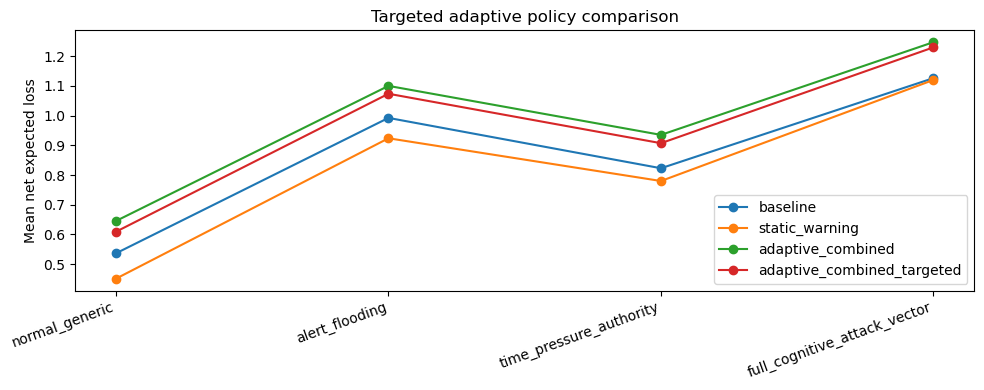

In [39]:
# Optional plot: mean net expected loss by defense for the targeted-policy experiment.
plot_df = targeted_policy_summary.copy()
plt.figure(figsize=(10, 4))
for defense in RACS_CORE_DEFENSES:
    sub = plot_df[plot_df['defense'] == defense]
    x = np.arange(len(BASE_CAMPAIGN_NAMES))
    y = [sub[sub['campaign'] == c]['net_expected_loss_mean'].mean() for c in BASE_CAMPAIGN_NAMES]
    plt.plot(x, y, marker='o', label=defense)
plt.xticks(np.arange(len(BASE_CAMPAIGN_NAMES)), BASE_CAMPAIGN_NAMES, rotation=20, ha='right')
plt.ylabel('Mean net expected loss')
plt.title('Targeted adaptive policy comparison')
plt.legend()
plt.tight_layout()
plt.savefig(RACS_ROBUSTNESS_DIR / 'targeted_policy_net_loss_plot.png', dpi=200)
plt.show()

In [40]:
# ============================================================
# RACS robustness result interpreter
# Add this after Section 20 outputs are generated.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 80)

# Use notebook variable if available; otherwise use default relative path.
try:
    RESULT_DIR = Path(RACS_ROBUSTNESS_DIR)
except NameError:
    RESULT_DIR = Path("cogload_phishing_outputs/racs_robustness")

print("Reading results from:", RESULT_DIR.resolve())

def read_csv_if_exists(filename):
    path = RESULT_DIR / filename
    if path.exists():
        print(f"Loaded: {filename}")
        return pd.read_csv(path)
    print(f"Missing: {filename}")
    return None

raw = read_csv_if_exists("all_racs_robustness_results.csv")
existing_summary = read_csv_if_exists("all_racs_robustness_summary.csv")
comparison = read_csv_if_exists("racs_robustness_comparison_vs_original.csv")
best_existing = read_csv_if_exists("best_defense_by_racs_scenario.csv")

# ------------------------------------------------------------
# 1. Build summary with confidence intervals from raw data
# ------------------------------------------------------------

GROUP_COLS = ["scenario_type", "scenario_name", "campaign", "defense"]

METRICS = [
    "click_rate_exposed",
    "report_rate_exposed",
    "compromise_rate_all",
    "org_breach_risk",
    "net_expected_loss",
    "overloaded_rate",
    "predicted_overload_rate",
    "false_adaptation_rate",
    "missed_overload_rate",
    "intervention_cost",
    "warning_friction",
]

def summarize_raw_results(df):
    available_metrics = [m for m in METRICS if m in df.columns]
    
    summary = (
        df.groupby(GROUP_COLS)[available_metrics]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    
    summary.columns = [
        "_".join(col).rstrip("_") if isinstance(col, tuple) else col
        for col in summary.columns
    ]
    
    # Add standard error and 95% CI half-width.
    for metric in available_metrics:
        std_col = f"{metric}_std"
        count_col = f"{metric}_count"
        if std_col in summary.columns and count_col in summary.columns:
            summary[f"{metric}_se"] = summary[std_col] / np.sqrt(summary[count_col])
            summary[f"{metric}_ci95"] = 1.96 * summary[f"{metric}_se"]
    
    return summary

if raw is not None:
    summary = summarize_raw_results(raw)
else:
    summary = existing_summary.copy()

print("\nSummary shape:", summary.shape)
display(summary.head())

# ------------------------------------------------------------
# 2. Rank defenses by primary metric: net expected loss
# ------------------------------------------------------------

PRIMARY = "net_expected_loss_mean"

def rank_defenses(summary_df, metric_col=PRIMARY):
    ranked = summary_df.sort_values(
        ["scenario_type", "scenario_name", "campaign", metric_col],
        ascending=[True, True, True, True]
    ).copy()
    
    ranked["rank_by_net_loss"] = (
        ranked.groupby(["scenario_type", "scenario_name", "campaign"])
        .cumcount() + 1
    )
    
    return ranked

ranked = rank_defenses(summary)

best_defense = ranked[ranked["rank_by_net_loss"] == 1].copy()

print("\nBest defense per scenario/campaign:")
display(
    best_defense[
        [
            "scenario_type", "scenario_name", "campaign", "defense",
            "net_expected_loss_mean", "click_rate_exposed_mean",
            "org_breach_risk_mean", "report_rate_exposed_mean"
        ]
    ].head(60)
)

# Save for later use
best_defense.to_csv(RESULT_DIR / "interpreted_best_defense_by_scenario.csv", index=False)

# ------------------------------------------------------------
# 3. Overall win counts: which defense most often wins?
# ------------------------------------------------------------

win_counts = (
    best_defense.groupby(["scenario_type", "defense"])
    .size()
    .reset_index(name="n_wins")
    .sort_values(["scenario_type", "n_wins"], ascending=[True, False])
)

print("\nDefense win counts by scenario type:")
display(win_counts)

overall_win_counts = (
    best_defense["defense"]
    .value_counts()
    .rename_axis("defense")
    .reset_index(name="n_wins_total")
)

print("\nOverall defense win counts:")
display(overall_win_counts)

# ------------------------------------------------------------
# 4. Pairwise comparison helper
# ------------------------------------------------------------

def pairwise_compare(summary_df, defense_a, defense_b, metric="net_expected_loss"):
    """
    Compares defense_a against defense_b.
    
    For lower-is-better metrics:
        delta_a_minus_b < 0 means defense_a is better.
        delta_a_minus_b > 0 means defense_a is worse.
    """
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    count_col = f"{metric}_count"
    
    a = summary_df[summary_df["defense"] == defense_a].copy()
    b = summary_df[summary_df["defense"] == defense_b].copy()
    
    keep_cols = ["scenario_type", "scenario_name", "campaign", mean_col]
    
    if std_col in summary_df.columns and count_col in summary_df.columns:
        keep_cols += [std_col, count_col]
    
    a = a[keep_cols].rename(columns={
        mean_col: f"{metric}_{defense_a}",
        std_col: f"{metric}_{defense_a}_std",
        count_col: f"{metric}_{defense_a}_n",
    })
    
    b = b[keep_cols].rename(columns={
        mean_col: f"{metric}_{defense_b}",
        std_col: f"{metric}_{defense_b}_std",
        count_col: f"{metric}_{defense_b}_n",
    })
    
    merged = a.merge(
        b,
        on=["scenario_type", "scenario_name", "campaign"],
        how="inner"
    )
    
    merged[f"delta_{defense_a}_minus_{defense_b}"] = (
        merged[f"{metric}_{defense_a}"] - merged[f"{metric}_{defense_b}"]
    )
    
    # Approximate uncertainty for the difference, if raw-derived counts exist.
    a_std = f"{metric}_{defense_a}_std"
    b_std = f"{metric}_{defense_b}_std"
    a_n = f"{metric}_{defense_a}_n"
    b_n = f"{metric}_{defense_b}_n"
    
    if all(c in merged.columns for c in [a_std, b_std, a_n, b_n]):
        merged["delta_se"] = np.sqrt(
            (merged[a_std] ** 2 / merged[a_n]) +
            (merged[b_std] ** 2 / merged[b_n])
        )
        merged["delta_ci95"] = 1.96 * merged["delta_se"]
        merged["difference_clear_by_ci95"] = (
            merged[f"delta_{defense_a}_minus_{defense_b}"].abs()
            > merged["delta_ci95"]
        )
    
    return merged

# Adaptive combined vs static warning
adaptive_vs_static = pairwise_compare(
    summary,
    defense_a="adaptive_combined",
    defense_b="static_warning",
    metric="net_expected_loss"
)

print("\nAdaptive combined vs static warning, based on net expected loss:")
print("delta < 0 means adaptive_combined is better than static_warning.")
display(adaptive_vs_static.sort_values("delta_adaptive_combined_minus_static_warning").head(40))

# Targeted adaptive vs broad adaptive
targeted_vs_broad = pairwise_compare(
    summary,
    defense_a="adaptive_combined_targeted",
    defense_b="adaptive_combined",
    metric="net_expected_loss"
)

print("\nTargeted adaptive vs broad adaptive, based on net expected loss:")
print("delta < 0 means targeted adaptive is better than broad adaptive.")
display(targeted_vs_broad.sort_values("delta_adaptive_combined_targeted_minus_adaptive_combined").head(40))

adaptive_vs_static.to_csv(RESULT_DIR / "interpreted_adaptive_vs_static_net_loss.csv", index=False)
targeted_vs_broad.to_csv(RESULT_DIR / "interpreted_targeted_vs_broad_adaptive_net_loss.csv", index=False)

# ------------------------------------------------------------
# 5. Static warning robustness
# ------------------------------------------------------------

def make_static_warning_robustness_table(summary_df):
    rows = []
    
    for (scenario_type, scenario_name, campaign), sub in summary_df.groupby(
        ["scenario_type", "scenario_name", "campaign"]
    ):
        sub_sorted = sub.sort_values("net_expected_loss_mean")
        best = sub_sorted.iloc[0]
        
        def get_loss(defense):
            row = sub[sub["defense"] == defense]
            if len(row) == 0:
                return np.nan
            return float(row["net_expected_loss_mean"].iloc[0])
        
        static_loss = get_loss("static_warning")
        broad_loss = get_loss("adaptive_combined")
        targeted_loss = get_loss("adaptive_combined_targeted")
        
        rows.append({
            "scenario_type": scenario_type,
            "scenario_name": scenario_name,
            "campaign": campaign,
            "best_defense": best["defense"],
            "best_net_loss": best["net_expected_loss_mean"],
            "static_net_loss": static_loss,
            "adaptive_combined_net_loss": broad_loss,
            "adaptive_targeted_net_loss": targeted_loss,
            "static_wins": best["defense"] == "static_warning",
            "targeted_beats_broad_adaptive": (
                targeted_loss < broad_loss
                if np.isfinite(targeted_loss) and np.isfinite(broad_loss)
                else np.nan
            ),
            "broad_adaptive_beats_static": (
                broad_loss < static_loss
                if np.isfinite(broad_loss) and np.isfinite(static_loss)
                else np.nan
            ),
            "targeted_adaptive_beats_static": (
                targeted_loss < static_loss
                if np.isfinite(targeted_loss) and np.isfinite(static_loss)
                else np.nan
            ),
        })
    
    return pd.DataFrame(rows)

static_robustness = make_static_warning_robustness_table(summary)

print("\nStatic-warning robustness table:")
display(static_robustness.head(80))

print("\nStatic warning win rate by scenario type:")
display(
    static_robustness.groupby("scenario_type")["static_wins"]
    .agg(["mean", "sum", "count"])
    .rename(columns={"mean": "static_win_rate", "sum": "static_wins", "count": "total_cases"})
)

static_robustness.to_csv(RESULT_DIR / "interpreted_static_warning_robustness.csv", index=False)

# ------------------------------------------------------------
# 6. Cognitive-load ablation interpretation
# ------------------------------------------------------------

def cognitive_load_ablation_effect(summary_df):
    ablation = summary_df[summary_df["scenario_type"] == "cognitive_load_ablation"].copy()
    
    if ablation.empty:
        print("No cognitive-load ablation rows found.")
        return pd.DataFrame()
    
    names = sorted(ablation["scenario_name"].unique())
    print("Cognitive-load ablation scenario names:", names)
    
    # Try to identify original and ablated scenario names automatically.
    original_candidates = [n for n in names if "original" in n or "weight_1" in n or n.endswith("_1")]
    ablated_candidates = [n for n in names if "ablation" in n or "weight_0" in n or n.endswith("_0")]
    
    if not original_candidates or not ablated_candidates:
        raise ValueError("Could not identify original and ablation scenario names automatically.")
    
    original_name = original_candidates[0]
    ablated_name = ablated_candidates[0]
    
    metrics = [
        "click_rate_exposed_mean",
        "org_breach_risk_mean",
        "net_expected_loss_mean",
        "report_rate_exposed_mean",
    ]
    
    available = [m for m in metrics if m in ablation.columns]
    
    pivot = ablation.pivot_table(
        index=["campaign", "defense"],
        columns="scenario_name",
        values=available,
        aggfunc="mean"
    )
    
    pivot.columns = ["__".join(col).strip() for col in pivot.columns.values]
    pivot = pivot.reset_index()
    
    for metric in available:
        orig_col = f"{metric}__{original_name}"
        abl_col = f"{metric}__{ablated_name}"
        
        if orig_col in pivot.columns and abl_col in pivot.columns:
            # Negative delta for loss/click/breach means removing cognitive-load behavior improved outcomes.
            pivot[f"without_load_minus_original__{metric}"] = pivot[abl_col] - pivot[orig_col]
    
    return pivot

load_effect = cognitive_load_ablation_effect(summary)

print("\nCognitive-load ablation effect:")
print("For click/breach/net loss: negative delta means removing behavioral cognitive load improved outcomes.")
print("That means cognitive load was increasing risk in the original model.")
display(load_effect.head(80))

load_effect.to_csv(RESULT_DIR / "interpreted_cognitive_load_ablation_effect.csv", index=False)

# ------------------------------------------------------------
# 7. Cost sensitivity and habituation focused views
# ------------------------------------------------------------

cost_view = static_robustness[static_robustness["scenario_type"] == "cost_sensitivity"].copy()
habituation_view = static_robustness[static_robustness["scenario_type"] == "static_warning_habituation"].copy()
targeted_view = static_robustness[static_robustness["scenario_type"] == "targeted_adaptive_policy"].copy()

print("\nCost sensitivity: when does the best defense change?")
display(
    cost_view[
        [
            "scenario_name", "campaign", "best_defense",
            "static_net_loss", "adaptive_combined_net_loss",
            "adaptive_targeted_net_loss", "static_wins"
        ]
    ].sort_values(["scenario_name", "campaign"])
)

print("\nStatic-warning habituation: does warning fatigue make static warning lose?")
display(
    habituation_view[
        [
            "scenario_name", "campaign", "best_defense",
            "static_net_loss", "adaptive_combined_net_loss",
            "adaptive_targeted_net_loss", "static_wins"
        ]
    ].sort_values(["scenario_name", "campaign"])
)

print("\nTargeted adaptive policy: does targeted adaptive beat broad adaptive?")
display(
    targeted_view[
        [
            "campaign", "best_defense",
            "static_net_loss", "adaptive_combined_net_loss",
            "adaptive_targeted_net_loss",
            "targeted_beats_broad_adaptive",
            "targeted_adaptive_beats_static"
        ]
    ].sort_values(["campaign"])
)

# ------------------------------------------------------------
# 8. Automatic plain-language takeaways
# ------------------------------------------------------------

def print_interpretive_takeaways(static_table, load_table=None):
    print("\n" + "=" * 80)
    print("AUTOMATIC INTERPRETATION")
    print("=" * 80)
    
    total_cases = len(static_table)
    static_wins = int(static_table["static_wins"].sum())
    targeted_beats_broad = int(static_table["targeted_beats_broad_adaptive"].fillna(False).sum())
    broad_beats_static = int(static_table["broad_adaptive_beats_static"].fillna(False).sum())
    targeted_beats_static = int(static_table["targeted_adaptive_beats_static"].fillna(False).sum())
    
    print(f"\n1) Static warning wins in {static_wins}/{total_cases} scenario-campaign cases.")
    print(f"2) Broad adaptive combined beats static warning in {broad_beats_static}/{total_cases} cases.")
    print(f"3) Targeted adaptive beats broad adaptive in {targeted_beats_broad}/{total_cases} cases.")
    print(f"4) Targeted adaptive beats static warning in {targeted_beats_static}/{total_cases} cases.")
    
    not_static = static_table[~static_table["static_wins"]]
    if len(not_static) > 0:
        print("\nCases where static warning is NOT best:")
        display(
            not_static[
                [
                    "scenario_type", "scenario_name", "campaign",
                    "best_defense", "best_net_loss",
                    "static_net_loss", "adaptive_combined_net_loss",
                    "adaptive_targeted_net_loss"
                ]
            ].sort_values(["scenario_type", "scenario_name", "campaign"])
        )
    else:
        print("\nStatic warning remains best in all tested cases.")
    
    if load_table is not None and not load_table.empty:
        net_delta_cols = [c for c in load_table.columns if c.startswith("without_load_minus_original__net_expected_loss")]
        click_delta_cols = [c for c in load_table.columns if c.startswith("without_load_minus_original__click_rate_exposed")]
        
        if net_delta_cols:
            col = net_delta_cols[0]
            n_lower = int((load_table[col] < 0).sum())
            n_total = int(load_table[col].notna().sum())
            print(f"\n5) Removing behavioral cognitive load reduced net expected loss in {n_lower}/{n_total} campaign-defense cases.")
            print("   If this number is high, the cognitive-load mechanism is materially contributing to risk.")
        
        if click_delta_cols:
            col = click_delta_cols[0]
            n_lower = int((load_table[col] < 0).sum())
            n_total = int(load_table[col].notna().sum())
            print(f"6) Removing behavioral cognitive load reduced exposed-user click rate in {n_lower}/{n_total} campaign-defense cases.")
            print("   If this number is high, your cognitive-load mechanism is not decorative; it changes behavior.")

print_interpretive_takeaways(static_robustness, load_effect)

Reading results from: C:\Users\User\Jupyter projects\eeg-analysis\academic mobility\cogload_phishing_outputs_last\racs_robustness
Loaded: all_racs_robustness_results.csv
Loaded: all_racs_robustness_summary.csv
Loaded: racs_robustness_comparison_vs_original.csv
Loaded: best_defense_by_racs_scenario.csv

Summary shape: (192, 59)


,scenario_type,scenario_name,campaign,defense,click_rate_exposed_mean,click_rate_exposed_std,click_rate_exposed_count,report_rate_exposed_mean,report_rate_exposed_std,report_rate_exposed_count,compromise_rate_all_mean,compromise_rate_all_std,compromise_rate_all_count,org_breach_risk_mean,org_breach_risk_std,org_breach_risk_count,net_expected_loss_mean,net_expected_loss_std,net_expected_loss_count,overloaded_rate_mean,overloaded_rate_std,overloaded_rate_count,predicted_overload_rate_mean,predicted_overload_rate_std,predicted_overload_rate_count,false_adaptation_rate_mean,false_adaptation_rate_std,false_adaptation_rate_count,missed_overload_rate_mean,missed_overload_rate_std,missed_overload_rate_count,intervention_cost_mean,intervention_cost_std,intervention_cost_count,warning_friction_mean,warning_friction_std,warning_friction_count,click_rate_exposed_se,click_rate_exposed_ci95,report_rate_exposed_se,report_rate_exposed_ci95,compromise_rate_all_se,compromise_rate_all_ci95,org_breach_risk_se,org_breach_risk_ci95,net_expected_loss_se,net_expected_loss_ci95,overloaded_rate_se,overloaded_rate_ci95,predicted_overload_rate_se,predicted_overload_rate_ci95,false_adaptation_rate_se,false_adaptation_rate_ci95,missed_overload_rate_se,missed_overload_rate_ci95,intervention_cost_se,intervention_cost_ci95,warning_friction_se,warning_friction_ci95
0,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined,0.460935,0.012262,200,0.482249,0.011209,200,0.080075,0.006069,200,0.650219,0.038431,200,0.907184,0.041134,200,0.051803,0.001695,200,0.370950,0.011138,200,0.325345,0.010873,200,0.024395,0.002613,200,0.052257,0.000668,200,0.022257,0.000668,200,0.000867,0.001699,0.000793,0.001554,0.000429,0.000841,0.002718,0.005326,0.002909,0.005701,0.000120,0.000235,0.000788,0.001544,0.000769,0.001507,0.000185,0.000362,0.000047,0.000093,0.000047,0.000093
1,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,adaptive_combined_targeted,0.462091,0.011398,200,0.479337,0.012233,200,0.080513,0.006042,200,0.665347,0.037049,200,0.886379,0.039978,200,0.055382,0.001687,200,0.265900,0.009270,200,0.229082,0.008676,200,0.033182,0.002518,200,0.045954,0.000556,200,0.015954,0.000556,200,0.000806,0.001580,0.000865,0.001695,0.000427,0.000837,0.002620,0.005135,0.002827,0.005541,0.000119,0.000234,0.000655,0.001285,0.000614,0.001202,0.000178,0.000349,0.000039,0.000077,0.000039,0.000077
2,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,baseline,0.471121,0.010904,200,0.469864,0.013114,200,0.081918,0.006252,200,0.727496,0.033089,200,0.842410,0.035807,200,0.070000,0.000000,200,0.000000,0.000000,200,0.000000,0.000000,200,NaN,NaN,0,0.000000,0.000000,200,0.000000,0.000000,200,0.000771,0.001511,0.000927,0.001818,0.000442,0.000866,0.002340,0.004586,0.002532,0.004963,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
3,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.406720,0.011880,200,0.557896,0.011559,200,0.070360,0.006080,200,0.602922,0.039430,200,0.717981,0.042057,200,0.070000,0.000000,200,0.000000,0.000000,200,0.000000,0.000000,200,NaN,NaN,0,0.040000,0.000000,200,0.000000,0.000000,200,0.000840,0.001646,0.000817,0.001602,0.000430,0.000843,0.002788,0.005465,0.002974,0.005829,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
4,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,adaptive_combined,0.684361,0.014404,200,0.465848,0.015827,200,0.120292,0.007351,200,0.873934,0.021835,200,1.136933,0.025463,200,0.292662,0.003576,200,0.457618,0.010269,200,0.224032,0.008043,200,0.126415,0.006534,200,0.057457,0.000616,200,0.027457,0.000616,200,0.001019,0.001996,0.001119,0.002194,0.000520,0.001019,0.001544,0.003026,0.001800,0.003529,0.000253,0.000496,0.000726,0.001423,0.000569,0.001115,0.000462,0.000906,0.000044,0.000085,0.000044,0.000085



Best defense per scenario/campaign:


,scenario_type,scenario_name,campaign,defense,net_expected_loss_mean,click_rate_exposed_mean,org_breach_risk_mean,report_rate_exposed_mean
3,cognitive_load_ablation,load_behavior_ablation_weight_0,alert_flooding,static_warning,0.717981,0.406720,0.602922,0.557896
7,cognitive_load_ablation,load_behavior_ablation_weight_0,full_cognitive_attack_vector,static_warning,1.009277,0.647317,0.873641,0.520342
11,cognitive_load_ablation,load_behavior_ablation_weight_0,normal_generic,static_warning,0.337056,0.285929,0.259248,0.580770
15,cognitive_load_ablation,load_behavior_ablation_weight_0,time_pressure_authority,static_warning,0.612209,0.534430,0.535226,0.545377
19,cognitive_load_ablation,load_original_weight_1,alert_flooding,static_warning,0.923684,0.532454,0.778042,0.464043
23,cognitive_load_ablation,load_original_weight_1,full_cognitive_attack_vector,static_warning,1.120120,0.782036,0.959751,0.396084
27,cognitive_load_ablation,load_original_weight_1,normal_generic,static_warning,0.451549,0.359711,0.357829,0.519131
31,cognitive_load_ablation,load_original_weight_1,time_pressure_authority,static_warning,0.780197,0.658459,0.689151,0.449295
35,cost_sensitivity,default_costs,alert_flooding,static_warning,0.923788,0.532225,0.778156,0.463743
39,cost_sensitivity,default_costs,full_cognitive_attack_vector,static_warning,1.120201,0.782096,0.959779,0.395880



Defense win counts by scenario type:


...


Targeted adaptive policy: does targeted adaptive beat broad adaptive?


,campaign,best_defense,static_net_loss,adaptive_combined_net_loss,adaptive_targeted_net_loss,targeted_beats_broad_adaptive,targeted_adaptive_beats_static
44,alert_flooding,static_warning,0.923730,1.100128,1.073637,True,False
45,full_cognitive_attack_vector,static_warning,1.120156,1.247397,1.229977,True,False
46,normal_generic,static_warning,0.450842,0.645140,0.608976,True,False
47,time_pressure_authority,static_warning,0.779796,0.935100,0.907138,True,False



AUTOMATIC INTERPRETATION

1) Static warning wins in 44/48 scenario-campaign cases.
2) Broad adaptive combined beats static warning in 0/48 cases.
3) Targeted adaptive beats broad adaptive in 47/48 cases.
4) Targeted adaptive beats static warning in 0/48 cases.

Cases where static warning is NOT best:


,scenario_type,scenario_name,campaign,best_defense,best_net_loss,static_net_loss,adaptive_combined_net_loss,adaptive_targeted_net_loss
33,static_warning_habituation,habituation_0.25,full_cognitive_attack_vector,baseline,1.127297,1.128365,1.248473,1.228304
37,static_warning_habituation,habituation_0.50,full_cognitive_attack_vector,baseline,1.128243,1.134300,1.246767,1.228572
40,static_warning_habituation,habituation_0.75,alert_flooding,baseline,0.990570,0.993485,1.100776,1.074527
41,static_warning_habituation,habituation_0.75,full_cognitive_attack_vector,baseline,1.127155,1.138101,1.247720,1.229541



5) Removing behavioral cognitive load reduced net expected loss in 16/16 campaign-defense cases.
   If this number is high, the cognitive-load mechanism is materially contributing to risk.
6) Removing behavioral cognitive load reduced exposed-user click rate in 16/16 campaign-defense cases.
   If this number is high, your cognitive-load mechanism is not decorative; it changes behavior.
